# M21 · Convolution, matrices de Toeplitz et équivariance — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookMaths/blob/main/chapitres/m21_convolution/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wbm.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | M21.1 à M21.11, M21.17 | Les exercices papier (vérification) | ✏️ 🔗 | | |
| A | M21.19 | La convolution de deux suites, dans les trois modes · `convolve` | 🔨 | ★★ | 30 |
|  | M21.20 | La matrice de Toeplitz d'une convolution · `toeplitz_matrix` | 🔨 | ★★ | 25 |
|  | M21.21 | La convolution circulaire · `circular_convolve` | 🔨 | ★ | 20 |
|  | M21.22 | Reconnaître un noyau séparable et le factoriser · `separable_factors` | 🔨 | ★★ | 25 |
|  | M21.23 | Le noyau équivalent et le pas d'une pile de sommes glissantes · `equivalent_kernel` | 🔨 | ★★ | 30 |
| B | M21.24 | Prédire l'effet d'un décalage de l'entrée sur un filtrage avec pas, puis vérifier | 🔮 | ★ | 15 |
|  | M21.25 | Le coût d'un filtrage direct ou séparable, selon la taille du noyau : mesurer, puis comparer à k² et 2k | 🔬 | ★★ | 20 |
|  | M21.26 | La carte des recouvrements d'une convolution transposée : un damier ou pas, selon k et s | 🎨 | ★ | 15 |
| C | M21.27 | Chasse à l'erreur : un noyau non retourné, des recouvrements supposés réguliers, un noyau de rang 2 « séparé » | 🐛 | ★ | 20 |
|  | M21.28 | Un test de propriété : la matrice de Toeplitz fois x égale la convolution, pour des longueurs tirées au hasard | 🛠️ | ★ | 15 |
| D | M21.29 | Défi : retrouver un noyau inconnu à partir d'un signal et de sa version filtrée bruitée, par les moindres carrés | 🏆 | ★★★ | 25 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (a few seconds per cell); False = bigger experiments
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookMaths.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookMaths")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WBM_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wbm").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wbm").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier de workbookMaths.")

os.environ["WBM_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wbm  # noqa: E402

cfg = wbm.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mymath = wbm.load_mymath("ref")  # reference implementation

🧪 workbookMaths : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | scipy 1.16.3 | sympy 1.14.0 | matplotlib 3.10.0 | pandas 2.2.3 | scikit-learn 1.6.1
   Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Vérifier tes calculs papier (partie 0) : une loi de somme de dés, des convolutions et des corrélations dans les trois modes, des pochoirs, une matrice de Toeplitz, l'équivariance avec un pas, des positions, une convolution transposée, une carte filtrée, des paramètres et des coûts, un champ récepteur, un pire cas, et un pont.
- Écrire les cinq fonctions de `mymath/convolution.py` (`convolve`, `toeplitz_matrix`, `circular_convolve`, `separable_factors`, `equivalent_kernel`) et les tester.
- Prédire l'effet d'un décalage sur un filtrage avec pas, mesurer le gain d'un noyau séparable, dessiner les recouvrements d'une convolution transposée, corriger trois erreurs classiques, écrire un test de propriété, et relever un défi : retrouver un noyau par les moindres carrés.

**Rappel express.** Convolution $(\mathbf{a} * \mathbf{b})_m = \sum_i a_i\,b_{m-i}$, noyau retourné (`np.convolve`) ; corrélation croisée $(\mathbf{w} \star \mathbf{x})_i = \sum_u w_u\,x_{i+u}$, sans retournement (les bibliothèques) : c'est la convolution valide par $\tilde{\mathbf{w}}$. Modes : plein $n + k - 1$, valide $n - k + 1$, même taille $n$ à partir de l'indice $\lfloor\frac{k-1}{2}\rfloor$ de la pleine. Toeplitz : $T_{ij} = w_{i-j}$, $nk$ coefficients non nuls ; la transposée de la valide est la pleine par $\tilde{\mathbf{w}}$. Circulaire : $\operatorname{circ}(\mathbf{h})^\top = \operatorname{circ}(\check{\mathbf{h}})$, $\check{\mathbf{h}} = (h_0, h_{n-1}, \ldots, h_1)$. Positions : $\lfloor\frac{n + 2p - d(k-1) - 1}{s}\rfloor + 1$. Transposée : $(m - 1)s - 2p + d(k - 1) + 1 + p_{\text{out}}$ valeurs, un damier si $s$ ne divise pas $k$. Paramètres $C_{\text{out}}(\frac{C_{\text{in}}}{g}k_hk_w + 1)$, coût $H_{\text{out}}W_{\text{out}}C_{\text{out}}\frac{C_{\text{in}}}{g}k_hk_w$ ; un noyau de rang 1 se fait en deux passes. Champ récepteur $1 + \sum_\ell d_\ell(k_\ell - 1)s_1\cdots s_{\ell-1}$, pas $S = s_1\cdots s_L$. Pire cas : $\varepsilon\lVert\mathbf{g}\rVert_1$ sur la boule L∞, en $\varepsilon\operatorname{signe}(\mathbf{g})$ ; $\varepsilon\lVert\mathbf{g}\rVert_2$ sur la boule L2.

## Partie 0 · Vérifier tes exercices papier (✏️ M21.1 à M21.11, 🔗 M21.17)

Fais d'abord les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse ici : **la valeur** que tu as trouvée, sous la forme indiquée en commentaire, jamais le calcul qui y mène :
- un entier, ou un nombre avec un point décimal, `-1.25`, arrondi comme le demande la question ;
- une liste `[0.2, -1]` ; une matrice comme la liste de ses **lignes**, `[[1, 0], [-2, 3]]`, un nombre décimal s'y écrivant avec un point ;
- une **forme** comme un tuple, `(7, 2)`, ou comme un texte, `"(7, 2)"` ;
- une fraction irréductible entre guillemets, `"3/7"`, quand la question le dit ;
- `True` ou `False` pour un vrai ou faux.

Les réponses pas encore remplies affichent ⏳.

In [2]:
# Part 0: the answers are computed from the statements (exact fractions, loops, NumPy)
import math
from fractions import Fraction
from itertools import product

import numpy as np
import scipy.signal


def shape_of(shape):
    """A shape (a tuple, or that of an array) written as NumPy prints it: "(3, 4, 5)", "(5,)"."""
    shape = np.shape(shape) if hasattr(shape, "shape") else shape
    return str(tuple(int(n) for n in shape))


def ints(values):
    """A list of Python ints from exact values (integers, fractions, floats equal to integers)."""
    values = list(values)
    out = [int(round(float(v))) for v in values]
    assert all(abs(float(v) - o) < 1e-9 for v, o in zip(values, out)), values
    return out


def floats(array):
    """A matrix of exact values as a list of rows of floats."""
    return [[float(v) for v in row] for row in array]


def correlate_valid(x, w, s=1):
    """The sliding sum of the libraries, valid mode, step s: y[i] = Σ_u w[u] x[s i + u] (loops)."""
    k = len(w)
    return [sum(w[u] * x[s * i + u] for u in range(k)) for i in range((len(x) - k) // s + 1)]


def fraction_convolve(a, b):
    """The exact full convolution (a * b)[m] = Σ_i a[i] b[m − i], with fractions."""
    out = [Fraction(0)] * (len(a) + len(b) - 1)
    for i, ai in enumerate(a):
        for j, bj in enumerate(b):
            out[i + j] += Fraction(ai) * Fraction(bj)
    return out


def count_positions(n, k, s=1, p=0, d=1):
    """The windows that fit in the padded signal (length n + 2p), counted one by one: no formula."""
    return sum(1 for start in range(0, n + 2 * p, s) if start + d * (k - 1) <= n + 2 * p - 1)


def correlate2d_valid(X, K):
    """The valid sliding sum of a grid X by a kernel K (no flip), with loops."""
    kh, kw = len(K), len(K[0])
    return np.array([[sum(K[u][v] * X[i + u][j + v] for u in range(kh) for v in range(kw))
                      for j in range(len(X[0]) - kw + 1)] for i in range(len(X) - kh + 1)])


FACES_A_1, FACES_B_1 = [1, 1, 1, 2, 2, 3], [1, 2, 3, 3, 4, 4, 4, 4]                           # M21.1
LAW_A_1 = [Fraction(FACES_A_1.count(v), 6) for v in (1, 2, 3)]                               # P(A = 1), ...
LAW_B_1 = [Fraction(FACES_B_1.count(v), 8) for v in (1, 2, 3, 4)]
POLY_1 = ints(fraction_convolve([3, 2, 1], [1, 1, 2, 4]))                    # (3 + 2X + X²)(1 + X + 2X² + 4X³)
CORR_1 = ints(fraction_convolve([3, 2, 1], [4, 2, 1, 1]))                    # sliding without flipping
CORR_OTHER_1 = ints(fraction_convolve([1, 2, 3], [1, 1, 2, 4]))              # the same, in the other direction
P_S_1 = {m + 2: p for m, p in enumerate(fraction_convolve(LAW_A_1, LAW_B_1))}                # index m ↔ S = m + 2
assert P_S_1 == {s: Fraction(sum(a + b == s for a, b in product(FACES_A_1, FACES_B_1)), 48) for s in P_S_1}
P_T_1 = {m + 3: p for m, p in enumerate(fraction_convolve(fraction_convolve(LAW_A_1, LAW_B_1), LAW_A_1))}  # + A'
assert sum(P_T_1.values()) == 1
X_2, W_2 = [3, -2, 0, 5, 1, -4, 2], [4, -1, 2]                                               # M21.2
N_2, K_2 = len(X_2), len(W_2)
FULL_2 = ints(fraction_convolve(X_2, W_2))                                                    # x * w, full
CORR_VALID_2 = correlate_valid(X_2, W_2)                                                      # w ⋆ x, valid
assert FULL_2 == np.convolve(X_2, W_2).tolist()
H_3 = 2                                                                                       # M21.3


def f_3(t):
    """The volume of the tank, f(t) = t³/4."""
    return Fraction(t) ** 3 / 4


def df_3(t):
    """f'(t) = 3t²/4."""
    return 3 * Fraction(t) ** 2 / 4


F_3 = [f_3(t) for t in range(0, 11, H_3)]                                                     # (0, 2, 16, ...)
FORWARD_3 = [(F_3[i + 1] - F_3[i]) / H_3 for i in range(len(F_3) - 1)]
CENTRED_3 = [(F_3[i + 1] - F_3[i - 1]) / (2 * H_3) for i in range(1, len(F_3) - 1)]          # t = 2 to 8
SECOND_3 = [(F_3[i + 1] - 2 * F_3[i] + F_3[i - 1]) / H_3 ** 2 for i in range(1, len(F_3) - 1)]
ERROR_D_3 = CENTRED_3[1] - df_3(4)                                                            # t = 4 is index 2
W_4, N_4 = [1, -3, 2], 5                                                                      # M21.4
K_4, X_4 = len(W_4), [2, 0, -1, 3, 1]


def toeplitz_4(w, n):
    """The matrix of x ↦ x * w, full mode: T[i, j] = w[i − j], 0 outside the kernel."""
    return np.array([[w[i - j] if 0 <= i - j < len(w) else 0 for j in range(n)] for i in range(n + len(w) - 1)])


T_4 = toeplitz_4(W_4, N_4)
V_4 = T_4[K_4 - 1:N_4]                                                                        # rows k − 1 to n − 1
assert np.array_equal(T_4 @ X_4, np.convolve(X_4, W_4))
RANK_V_4 = int(np.linalg.matrix_rank(V_4))
GEOMETRIC_4 = [2 ** i for i in range(N_4)]
KERNEL_VT_4 = V_4.T[:K_4, 0].tolist()                                                         # read on a column of Vᵀ
assert np.array_equal(toeplitz_4(KERNEL_VT_4, N_4 - K_4 + 1), V_4.T)
X_5, W_5 = [0, 0, 2, -1, 3, 0, 0, 0, 0, 0], [1, -1, 2]                                       # M21.5


def delayed_5(x, t):
    """τ_t x: t zeros enter on the left, the last t values leave on the right."""
    return [0] * t + x[:len(x) - t]


def shift_between_5(y, y0):
    """The m ≥ 0 such that y is y0 moved m places to the right (zeros entering on the left), or None."""
    return next((m for m in range(len(y0)) if y[m:] == y0[:len(y0) - m] and not any(y[:m])), None)


A_5 = correlate_valid(X_5, W_5)
LOST_5 = sum(1 for i, v in enumerate(A_5) if v != 0 and i + 5 > len(A_5) - 1)          # shifted beyond the end
assert LOST_5 == sum(v != 0 for v in A_5) - sum(v != 0 for v in correlate_valid(delayed_5(X_5, 5), W_5))
STRIDE2_5 = {t: correlate_valid(delayed_5(X_5, t), W_5, s=2) for t in (0, 1, 4)}
N_OUT_6 = -(-365 // 3)                                                                        # M21.6: ⌈365/3⌉
TOTAL_6 = max((N_OUT_6 - 1) * 3 + 6 + 1 - 365, 0)                                             # zeros in all
ZEROS_6 = [TOTAL_6 // 2, TOTAL_6 - TOTAL_6 // 2]
assert (365 + TOTAL_6 - 6 - 1) // 3 + 1 == N_OUT_6
LENGTHS_6 = [n for n in range(1, 400) if count_positions(n, 5, s=5) == 50]
STEPS_6 = [s for s in range(1, 1000) if count_positions(1000, 7, s=s) == 125]
assert len(STEPS_6) == 1
STEP_6 = STEPS_6[0]
X_7 = [5, 1, 8, -2, 0, 4, 7]                                                                  # M21.7
D3_7 = np.eye(len(X_7), dtype=int)[::3]                                                       # (D₃ x)_i = x_{3i}
Y_7, W_7, S_7 = [3, 2, -2], [2, 1, 3, -1, 1], 3
M_7, K_7 = len(Y_7), len(W_7)


def strided_matrix_7(w, n, s):
    """The matrix C of the sliding sum of weights w, step s, valid mode, on signals of length n."""
    C = np.zeros((count_positions(n, len(w), s=s), n), dtype=int)
    for i in range(len(C)):
        C[i, s * i:s * i + len(w)] = w
    return C


LENGTHS_7 = [n for n in range(1, 50) if count_positions(n, K_7, s=S_7) == M_7]               # m positions
SIZE_7 = LENGTHS_7[0]                                                                         # p_out = 0
C_7 = strided_matrix_7(W_7, SIZE_7, S_7)
TRANSPOSED_7 = C_7.T @ Y_7                                                                    # the matrix Cᵀ (definition)
STAMPS_7 = strided_matrix_7([1] * K_7, SIZE_7, S_7).T @ np.ones(M_7, dtype=int)
SIZE_OUT_7 = (M_7 - 1) * S_7 - 2 * 0 + 1 * (K_7 - 1) + 1 + 2                                 # p_out = 2 (fiche §5)
assert SIZE_OUT_7 == LENGTHS_7[2]
LONG_7 = strided_matrix_7([1] * 12, (20 - 1) * 4 + 12, 4).T @ np.ones(20, dtype=int)         # k = 12, s = 4
assert len(set(LONG_7[11:(20 - 1) * 4 + 1].tolist())) == 1                                    # constant inside
INTERIOR_7 = int(LONG_7[len(LONG_7) // 2])
T_8 = np.array([[14, 15, 17, 16, 15, 13], [15, 18, 21, 19, 12, 14],                         # M21.8
                [16, 20, 24, 22, 17, 15], [15, 17, 19, 18, 16, 14]])
LAPLACIAN_8 = np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]])
A_8 = [Fraction(1, 5), Fraction(3, 5), Fraction(1, 5)]
LAP_8 = correlate2d_valid(T_8, LAPLACIAN_8)
VERTICAL_8 = correlate2d_valid(T_8, [[a] for a in A_8])                                       # each column by a
SMOOTH_8 = correlate2d_valid(VERTICAL_8, [A_8])                                               # then each row
assert np.array_equal(SMOOTH_8, correlate2d_valid(T_8, [[a * b for b in A_8] for a in A_8]))


def output_8(flat):
    """The [i, j] in the output of a flat index of LAP_8."""
    return [int(v) for v in np.unravel_index(flat, LAP_8.shape)]


def cell_8(flat):
    """The [i, j] in T of the centre of the window of the output LAP_8.flat[flat]."""
    return [v + 1 for v in output_8(flat)]


H_9, W_9, C_IN_9, C_OUT_9, K_9, P_9, BYTES_9 = 200, 300, 12, 20, 5, 2, 4                     # M21.9
OUT_H_9, OUT_W_9 = count_positions(H_9, K_9, p=P_9), count_positions(W_9, K_9, p=P_9)


def params_9(c_in, c_out, k, g=1):
    """The parameters of a filtering with g groups: c_out (c_in/g k k + 1)."""
    return c_out * (c_in // g * k * k + 1)


def macs_9(c_in, c_out, k, g=1):
    """One multiply-accumulate per weight and per output position (step 1, padding P_9)."""
    return count_positions(H_9, k, p=P_9) * count_positions(W_9, k, p=P_9) * c_out * (c_in // g) * k * k


A_10, B_10 = [Fraction(1, 2)] * 2, [Fraction(1, 3)] * 3                                       # M21.10
X_10 = [5, 9, 2, 8, 4, 10, 1]


def stack_kernel_10(kernels, strides, length=120):
    """The equivalent kernel of a stack of sliding sums, read on impulses: K[t] = z[0] for x = e_t (exact)."""
    def first_output(x):
        for w, s in zip(kernels, strides):
            x = correlate_valid(x, w, s)
        return x[0]
    return [first_output([Fraction(int(i == t)) for i in range(length)]) for t in range(length)]


def trimmed(kernel):
    """The kernel without its trailing zeros (the impulses beyond the receptive field)."""
    last = max(t for t, v in enumerate(kernel) if v != 0)
    return kernel[:last + 1]


def receptive_field_10(stack):
    """r = 1 + Σ d(k − 1) s_1 ... s_{ℓ−1}, by the recurrence r += d (k − 1) J, J *= s."""
    r, J = 1, 1
    for k, s, d in stack:
        r, J = r + d * (k - 1) * J, J * s
    return r


Z_10 = correlate_valid(correlate_valid(X_10, A_10), B_10)
STACK_10 = [(2, 2, 1), (5, 4, 1), (3, 1, 4)]                                                  # (k, s, d)
R_10, S_10 = receptive_field_10(STACK_10), math.prod(s for k, s, d in STACK_10)
HOLED_10 = [[1, 1], [1] * 5, [1, 0, 0, 0, 1, 0, 0, 0, 1]]                                    # the dilation as holes
assert len(trimmed(stack_kernel_10(HOLED_10, [s for k, s, d in STACK_10]))) == R_10        # read on impulses
G_11, EPS_11 = [-2, 5, 1, -3, 1], 0.25                                                        # M21.11
L1_11, L2_11, LINF_11 = sum(map(abs, G_11)), math.sqrt(sum(g * g for g in G_11)), max(map(abs, G_11))
WORST_INF_11 = max(sum(g * e for g, e in zip(G_11, signs)) for signs in product((-EPS_11, EPS_11), repeat=5))
assert math.isclose(WORST_INF_11, EPS_11 * L1_11)                                             # the 32 corners
DELTA_11 = [EPS_11 * float(np.sign(g)) for g in G_11]
WORST_ONE_11 = max(sign * EPS_11 * g for g in G_11 for sign in (-1, 1))                      # the 10 vertices ± ε eᵢ
G_H_11 = [0.02 * (-1) ** i for i in range(2500)]                                              # n = 2 500, ± 0.02
L1_H_11, L2_H_11 = sum(map(abs, G_H_11)), math.sqrt(sum(g * g for g in G_H_11))
X_17 = np.array([[[2, 1, 0, 3, 1], [0, 4, 2, 1, 3], [1, 2, 5, 0, 2], [3, 0, 1, 2, 4]],      # M21.17: (C, H, W)
                 [[1, 0, 2, 2, 0], [3, 1, 0, 4, 1], [2, 2, 1, 0, 3], [0, 1, 3, 1, 2]],
                 [[0, 2, 1, 1, 4], [1, 0, 3, 2, 0], [4, 1, 0, 2, 1], [2, 3, 1, 0, 1]]])
W_17 = np.array([[[[1, 0], [2, -1]], [[0, 1], [-1, 0]], [[2, 0], [1, 1]]],                  # (C_out, C_in, k, k)
                 [[[0, -1], [1, 0]], [[1, 1], [0, 0]], [[-1, 0], [0, 2]]]])
B_17 = np.array([1, -2])


def filter_17(X, W, b):
    """The sliding sum of the libraries on channels, valid mode: Y[o] = b[o] + Σ_c X[c] ⋆ W[o, c]."""
    return np.array([b[o] + sum(correlate2d_valid(X[c], W[o, c]) for c in range(len(X))) for o in range(len(W))])


Y_17 = filter_17(X_17, W_17, B_17)
FLIPPED_17 = filter_17(X_17, W_17[:, :, ::-1, ::-1], B_17)                                  # both axes flipped
KERNEL_2D_17 = W_17[0, 0, ::-1, ::-1]                                                         # a half turn
assert np.array_equal(scipy.signal.convolve2d(X_17[0], KERNEL_2D_17, "valid"), correlate2d_valid(X_17[0], W_17[0, 0]))
X1D_17, W1D_17 = [4, 1, 3, 2, 5], [1, 4]                                                      # y_i = x_i + 4 x_{i+1}
TORCH_SAME_17 = correlate_valid(X1D_17 + [0], W1D_17)                                         # one zero on the right
NUMPY_SAME_17 = np.convolve(X1D_17, [4, 1], "same").tolist()

**Ex M21.1 — Deux dés truqués et un produit de polynômes : la même convolution**

In [3]:
wbm.record("M21.1a", POLY_1, mistakes={"le coefficient de Xᵐ rassemble les aᵢbⱼ avec i + j = m : en faisant glisser une suite sans la "
                     "retourner, on calcule une corrélation, pas un produit de polynômes": CORR_1,
                     "le coefficient de Xᵐ rassemble les aᵢbⱼ avec i + j = m : en faisant glisser une suite sans la "
                     "retourner, dans un sens ou dans l'autre, on calcule une corrélation": CORR_OTHER_1,
                     "du terme constant au terme de plus haut degré : ta liste est dans l'autre ordre": POLY_1[::-1]})
wbm.record("M21.1b", str(P_S_1[5]), kind="fraction", simplified=True,
           mistakes={"l'indice du coefficient n'est pas la valeur de S : les faces commencent à 1, les indices à 0":
                         str(Fraction(POLY_1[5], 48)),
                     "chaque dé décale d'une case : l'écart entre l'indice m et la valeur de S compte les deux dés":
                         str(Fraction(POLY_1[4], 48))})
wbm.record("M21.1c", str(sum(p for s, p in P_S_1.items() if s >= 6)), kind="fraction", simplified=True,
           mistakes={"S ≥ 6 : la valeur 5 n'en fait pas partie": str(sum(p for s, p in P_S_1.items() if s >= 5)),
                     "quels indices m donnent S ≥ 6 ? Chaque dé décale d'une case": str(Fraction(POLY_1[5], 48))})
wbm.record("M21.1d", str(sum(s * p for s, p in P_S_1.items())), kind="fraction", simplified=True,
           mistakes={"c'est l'espérance de l'indice m ; la valeur de S est décalée":
                         str(sum(Fraction(m * c, 48) for m, c in enumerate(POLY_1)))})
wbm.record("M21.1e", next(m for m, c in enumerate(POLY_1) if Fraction(c, 48) == P_S_1[5]), mistakes={"l'indice m n'est pas la valeur de S": 5})
wbm.record("M21.1f", max(P_S_1, key=P_S_1.get), mistakes={"c'est l'indice du plus grand coefficient ; la valeur de S est décalée":
                         POLY_1.index(max(POLY_1))})
wbm.record("M21.1g", str(sum(p for t, p in P_T_1.items() if t >= 9)), kind="fraction", simplified=True,
           mistakes={"A + B + A' ≥ 9 compte aussi la plus grande valeur possible": str(P_T_1[9])})

WBM_ANSWER {"decimals": 0, "element_hashes": ["c025597bd56eba47b79960d91be97a6986f5cbb95ab0e2bd71415590068614d7", "4bb9e42462431992c390cec69a1d00e7169155a8dc94dc0a737eca9caae5bfc4", "76dc387b97f7706e97e42cb1038aabef5b4ff7ae4ba970cda4cfeeb55902f040", "e00e49719038feed7c0a98d8fb972a5bbffb717da926ce39c2b42c5cf94007ba", "3baac56c81f98f6ee3f01c9645a588643475b7de8464e020caa7f540ca2f376e", "677c7023c789fc86dc5c327a4c3c91975274f4d31451bc8c1b48ebac00c373e3"], "hash": "df94c0bbfe44c867910abe04bafe4d510ef9b1498c838f08c2b2a6ce8b3eeadc", "id": "M21.1a", "integer": true, "kind": "array", "mistakes": {"47dab3383281e59bfa0dd8b497966dc47fe98085ced99c60648237f82f999e5d": "du terme constant au terme de plus haut degré : ta liste est dans l'autre ordre", "aa05045e3f61be6435e826abbe75a5303c347384d9dde1286ded888906a7841f": "le coefficient de Xᵐ rassemble les aᵢbⱼ avec i + j = m : en faisant glisser une suite sans la retourner, dans un sens ou dans l'autre, on calcule une corrélation", "fb885388b0538fc4a7b84

WBM_ANSWER {"hash": "06e0a542671db21314580a3498085685f946352fea903290264cce5356e33e0d", "id": "M21.1b", "kind": "fraction", "mistakes": {"445a711009ad5386a2b8ecc6399e2b8e9ecde8b9ae8abcb45c9c00884928c52b": "l'indice du coefficient n'est pas la valeur de S : les faces commencent à 1, les indices à 0", "e3292c56279ad62513fbcee841755b65fd2aa9d692f78cd96f9c82b4fc763741": "chaque dé décale d'une case : l'écart entre l'indice m et la valeur de S compte les deux dés"}, "sign": 1, "simplified": true}
📝 Ex M21.1b : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "f6f2dca48493a0fe5e63eb45651ad345224875b1419da98110c093891ddba5d5", "id": "M21.1c", "kind": "fraction", "mistakes": {"690335767786a187042afc25f3c2e36af3af8bf3d33b30668734d7f1e3b9e4d2": "S ≥ 6 : la valeur 5 n'en fait pas partie", "b218ebd5bf85c67ae0d6fa068c6af1a5637f583d8097fa508022242045ab033d": "quels indices m donnent S ≥ 6 ? Chaque dé décale d'une case"}, "sign": 1, "simplified": true}
📝 Ex M21.1c : réponse enregistrée (fraction).

**Ex M21.2 — Convoluer et corréler un signal à la main, dans les trois modes**

In [4]:
wbm.record("M21.2a", CORR_VALID_2, mistakes={"la corrélation croisée ne retourne pas le noyau : tu as calculé une convolution":
                         FULL_2[K_2 - 1:N_2]})
wbm.record("M21.2b", FULL_2, mistakes={"la convolution retourne le noyau : tu as calculé une corrélation en mode plein":
                         ints(fraction_convolve(X_2, W_2[::-1]))})
wbm.record("M21.2c", FULL_2[K_2 - 1:N_2], mistakes={"la convolution retourne le noyau : tu as fait glisser w sans le retourner": CORR_VALID_2})
wbm.record("M21.2d", FULL_2[(K_2 - 1) // 2:(K_2 - 1) // 2 + N_2], mistakes={"NumPy commence le mode même taille à l'indice ⌊(min(n, k) − 1)/2⌋ de la convolution pleine, pas "
                     "à l'indice 0": FULL_2[:N_2],
                     "le mode même taille garde aussi une valeur du bord gauche : il ne commence pas à l'indice k − 1":
                         FULL_2[K_2 - 1:K_2 - 1 + N_2]})
wbm.record("M21.2e", W_2[::-1], mistakes={"une corrélation par w redonne a) : il faut un autre noyau": W_2})
wbm.record("M21.2f", CORR_VALID_2 == FULL_2[K_2 - 1:N_2], mistakes={"compare terme à terme : retourner un noyau qui n'est pas symétrique change le résultat": True})
wbm.record("M21.2g", sum(FULL_2), mistakes={"la somme d'une convolution est le PRODUIT des sommes des deux suites, pas leur somme":
                         sum(X_2) + sum(W_2)})

WBM_ANSWER {"decimals": 0, "element_hashes": ["fb126dfd0a5bc361db0be29078659a61c6e37a1ef8fc0f9ba8a083d5eb0b0980", "ad85b0fa073766da6e3c7279daa0d934a5cdf05888e4aab744520c8f09d261d4", "e596c4fd10be5cd02b8f9212a5ab5f975bbd982d56b99e7fe5162f56d9bc2b1c", "25e8f8d6282f5fc9e1b72358221123f567a9113c37a7674b39f8509435f8efc1", "b33226d6c5b5d9fc46b2bd5fbbab6bc1376d493717e6c06d0c0f0d434d7ad7fc"], "hash": "f143acceac1a70333607f4d8163ccc707222b1d0aff31206ea79c061ece89db7", "id": "M21.2a", "integer": true, "kind": "array", "mistakes": {"5468926b502d8bc880fda1c6fce0dfd7c46deb986e801bb55dc20288a79e5dce": "la corrélation croisée ne retourne pas le noyau : tu as calculé une convolution"}, "shape": [5]}
📝 Ex M21.2a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["21c3ca98a09d65e7b1a9194df0d290a4b4d251c8656b567b62e5bf2e72856cf0", "b63e711743e3bc8680c147f65a744fb8a4aa02942b2897227e1ebe6e94e7eb77", "8a73504fd889b229477bb3874af63b8daaa6c0f8fc7dd326acdb81b955dff6e9", "13

**Ex M21.3 — Des pochoirs de différences finies : dérivée et dérivée seconde d'un signal échantillonné**

In [5]:
wbm.record("M21.3a", ints(FORWARD_3), mistakes={"chaque différence se divise par h": ints(v * H_3 for v in FORWARD_3)})
wbm.record("M21.3b", ints(CENTRED_3), mistakes={"la différence centrée divise par 2h, l'écart entre les instants t − h et t + h":
                         ints(2 * v for v in CENTRED_3),
                     "ce sont des différences avant ; la différence centrée lit les deux voisins": ints(FORWARD_3[1:])})
wbm.record("M21.3c", ints(SECOND_3), mistakes={"la dérivée seconde divise par h², pas par h": ints(v * H_3 for v in SECOND_3),
                     "(fᵢ₊₁ − 2fᵢ + fᵢ₋₁)/h² : as-tu bien divisé, et par le bon nombre ?":
                         ints(v * H_3 ** 2 for v in SECOND_3)})
wbm.record("M21.3d", float(ERROR_D_3), decimals=2, mistakes={"l'erreur est la valeur approchée MOINS la vraie valeur": float(-ERROR_D_3)})
wbm.record("M21.3e", [float(FORWARD_3[1] - df_3(2)), float(FORWARD_3[1] - df_3(3))], decimals=2, mistakes={"dans l'ordre de l'énoncé : d'abord f′(2), puis f′(3)":
                                     [float(FORWARD_3[1] - df_3(3)), float(FORWARD_3[1] - df_3(2))]})
wbm.record("M21.3f", bool(np.allclose(np.convolve([float(v) for v in F_3], [-1, 0, 1], 'valid') / 4, [float(v) for v in CENTRED_3])), mistakes={"np.convolve retourne le noyau : regarde le signe de chaque terme": True})
wbm.record("M21.3g", float((f_3(5) - f_3(3)) / 2 - df_3(4)), decimals=2, mistakes={"l'erreur de la différence centrée est d'ordre 2 en h": float(ERROR_D_3 / 2),
                                 "l'erreur dépend de h : relis sa formule (M05a)": float(ERROR_D_3)})

WBM_ANSWER {"decimals": 0, "element_hashes": ["19d48eaf63a0f10c50799ea5795c067ded90467eb4659e9e986866c8146e99c2", "7a9d22cd828378f1cf189f1cf7df86833e83221bd84c2367be8abfd754512829", "1332ba9d7a139c344f0354b3a659abe9c286e3d3ceeb19ac1026c9cb2d8f945d", "388b7ba074438a26eceb0dc35f30a56f3b0e40c9369ed2c82de5e2847928be69", "942ecb5e8ab4bbff6e3ff94562594022d6674c1f633896c606422fb88fee7904"], "hash": "b6a484d552e3cbe6df00c0e7ec4d6088abba2ddef781f28c013e30011faeb6d3", "id": "M21.3a", "integer": true, "kind": "array", "mistakes": {"4d1f9a614a11ec2e86cbd439d4358e581e680dc8551be395c490d8211296927a": "chaque différence se divise par h"}, "shape": [5]}
📝 Ex M21.3a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["4588e86ab6e350e7f5e9d0fa8e58215f5750bddf70b907e634bcc4486f18e65d", "fa89ee3129cd623b63152e09b715106d40872e162a523adfa6df4e80523ebba8", "a9504a2ad045eb1987220ca0c8b48e0e333428d7d221be71c1fe1f76cc48dc43", "ac876b49ccfa342b5703f3a36fad6c9aa1f8595a214fed18

**Ex M21.4 — La matrice de Toeplitz d'une convolution pleine et d'une convolution valide : coefficients non nuls, rang et noyau**

In [6]:
wbm.record("M21.4a", T_4.tolist(), mistakes={"chaque COLONNE est le noyau, descendu d'une ligne de plus que la précédente": T_4.T.tolist(),
                     "T[i, j] = w₍ᵢ₋ⱼ₎ : la colonne j commence par w₀ ; ta matrice est celle du noyau retourné":
                         toeplitz_4(W_4[::-1], N_4).tolist()})
wbm.record("M21.4b", int(np.count_nonzero(T_4)), mistakes={"compte les coefficients NON NULS, pas tous les coefficients": int(T_4.size)})
wbm.record("M21.4c", (T_4 @ X_4).tolist(), mistakes={"la convolution retourne le noyau : ton calcul utilise le noyau à l'envers":
                         (toeplitz_4(W_4[::-1], N_4) @ X_4).tolist()})
wbm.record("M21.4d", V_4.tolist(), mistakes={"le mode valide garde les lignes k − 1 à n − 1 de T, pas les premières":
                         T_4[:N_4 - K_4 + 1].tolist(),
                     "relis une ligne de T : le noyau y apparaît retourné":
                         toeplitz_4(W_4[::-1], N_4)[K_4 - 1:N_4].tolist()})
wbm.record("M21.4e", RANK_V_4, mistakes={"les trois lignes sont échelonnées : aucune n'est combinaison des autres": RANK_V_4 - 1})
wbm.record("M21.4f", N_4 - RANK_V_4, mistakes={"c'est le rang ; théorème du rang : dim ker = nombre de colonnes − rang": RANK_V_4,
                     "V a plus de colonnes que de lignes : son noyau n'est pas réduit à 0": 0})
wbm.record("M21.4g", bool(np.all(V_4 @ GEOMETRIC_4 == 0)), mistakes={"calcule les trois coordonnées de V x pour ce signal": False})
wbm.record("M21.4h", int(np.linalg.matrix_rank(T_4)), mistakes={"les colonnes de T sont échelonnées : chacune commence une ligne plus bas, par w₀ ≠ 0": RANK_V_4})
wbm.record("M21.4i", KERNEL_VT_4, mistakes={"lis une colonne de Vᵀ : le noyau n'y est pas dans le même ordre que w": W_4})

WBM_ANSWER {"decimals": 0, "element_hashes": ["1b50a5ac9b7292caa629f959a3c18a8404725fc43601ffd59e33165237bd4f8a", "2d765243ce783a474c52ecb3030545ca0193e65c30a67efbed5c413e2823425c", "4eaa48ede0438b5ed98be155c3376a6821ce2841783a9848027f28cfdcb84907", "ab87d395179dd7b29d02b9e0ab475579a2c40e4a7b04f2d24dbb25a54b575fda", "4244fdf8d3ea868d17aa3742d5253d6171aa90842a13aa4bf25d57e9ea797d4c", "cc4f5da23113626cd612210a78c6f0ab8d2436c09282d48eeb7a374fbbb2d4b9", "db7ed10ba3b6a6be553517dc0706ebbdd4b82336782cc6918ce5acb8d9091340", "4e3849801f65d3eeacf6bf9b61565c542dc66abedaff4da84e599ded91809b7f", "e0ce97c082a73961b947a3175e492a5b55eb5db448f91264d0771495df118372", "5863b1ca9cd4e43820fb7830c5a147fd4a37df20a34a8ca19812649df0c1dd17", "a19fd30dc6cacc67f5401a89c28683b14e41fba18501642e84ddf867f929b771", "e6cc5520c530d510cd1a430b1169807ec6ac23769f6d9cf4c9a3f38d7a79934e", "5d2318940bf933d6c65d2759c7e26f9f2218347f16b354446a4dbe7c79377763", "3eca22d8f1915d6de70ef7ab02b556525cd5c0cc1bfe7c1c84fea9f9d192a9e2", "0

**Ex M21.5 — Décaler puis filtrer, ou filtrer puis décaler : l'équivariance, ses bords et son pas**

In [7]:
wbm.record("M21.5a", A_5, mistakes={"la somme glissante ne retourne pas les poids : tu as calculé une convolution":
                         ints(fraction_convolve(X_5, W_5)[len(W_5) - 1:len(X_5)])})
wbm.record("M21.5b", correlate_valid(delayed_5(X_5, 3), W_5), mistakes={"τ₃ retarde le signal : sa réponse se déplace vers la droite": A_5[3:] + [0] * 3})
wbm.record("M21.5c", LOST_5, mistakes={"compte les valeurs non nulles de a) qui, décalées de 5 cases, n'ont plus de position, pas le "
                     "décalage": 5,
                     "compte les termes, pas les valeurs distinctes : chacun des deux −4 de a) a sa propre position":
                         len({v for i, v in enumerate(A_5) if v != 0 and i + 5 > len(A_5) - 1}
                             - set(correlate_valid(delayed_5(X_5, 5), W_5)))})
wbm.record("M21.5d", STRIDE2_5[0], mistakes={"y₀ lit la fenêtre qui commence à la case 0": A_5[1::2]})
wbm.record("M21.5e", STRIDE2_5[1], mistakes={"un décalage d'une case de l'entrée ne décale pas cette sortie d'une case : recalcule les "
                     "fenêtres 0, 2, 4 et 6": [0] + STRIDE2_5[0][:-1]})
wbm.record("M21.5f", shift_between_5(STRIDE2_5[4], STRIDE2_5[0]), mistakes={"c'est le décalage de l'entrée ; la sortie, qui garde une valeur sur 2, bouge moins": 4})
wbm.record("M21.5g", (shift_between_5(STRIDE2_5[1], STRIDE2_5[0]) is not None or shift_between_5(STRIDE2_5[0], STRIDE2_5[1]) is not None), mistakes={"compare e) à d) décalée d'une ou deux cases : ce ne sont pas les mêmes nombres": True})

WBM_ANSWER {"decimals": 0, "element_hashes": ["a658d9f64f28345d4aa6f78c02ad41c229079c4b718b73dd0ebecddb9c9184ae", "b8308f0f75c9c856946e0efce27631eb184ae52ff682b4022fc2e913616cffbc", "58ad3feaf0bb7fb0d42389ea0f9a34949c5da48562491e6614cef83061c0f9d1", "33ac508b5c67e117d288ebf55763df062a4b832aa60aecc42a40523ec595adff", "6dd4149c6d42c5468864a55e7c030c37f0358ec78e21007cacdb497590b115fc", "5e8c63546ccba351dd78211d12f7bccde20e613f1a21c8332d3b2450a39bc424", "11fe487e7a134e18c9e24cc43e186784e8f86e0c58bdede3281b2997e8b3883a", "15534bb079d0bff0061b50af3abf4ce2e585974d6eeed99693e30a24f2d486a3"], "hash": "37c278300d38e02c98022b2c65b4d4892841618c800fed9f9c10ae3ed1cc5b22", "id": "M21.5a", "integer": true, "kind": "array", "mistakes": {"f5ea1074c3994b401438f000d2f705b9322ce8969e4c93b6542f1979f6ae58cc": "la somme glissante ne retourne pas les poids : tu as calculé une convolution"}, "shape": [8]}
📝 Ex M21.5a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["07bad

**Ex M21.6 — Compter les positions d'une fenêtre : pas, dilatation, padding, « même taille » avec un pas, et le problème inverse**

In [8]:
wbm.record("M21.6a", count_positions(1000, 7), mistakes={"la position 0 compte aussi": count_positions(1000, 7) - 1})
wbm.record("M21.6b", count_positions(1000, 7, s=3, p=2), mistakes={"la fenêtre incomplète n'existe pas : la partie entière se prend vers le BAS":
                         math.ceil((1000 + 2 * 2 - 6 - 1) / 3) + 1,
                     "le padding est ajouté des deux côtés": count_positions(1000, 7, s=3, p=1)})
wbm.record("M21.6c", count_positions(1000, 7, d=4), mistakes={"la dilatation étale la fenêtre : relis son étendue": count_positions(1000, 7)})
wbm.record("M21.6d", count_positions(1000, 7, s=5, p=3, d=4), mistakes={"la dilatation étale la fenêtre : relis son étendue": count_positions(1000, 7, s=5, p=3),
                     "la fenêtre incomplète n'existe pas : la partie entière se prend vers le BAS":
                         math.ceil((1000 + 2 * 3 - 4 * 6 - 1) / 5) + 1})
wbm.record("M21.6e", N_OUT_6, mistakes={"une sortie par bloc de s valeurs, le dernier bloc pouvant être incomplet": 365 // 3})
wbm.record("M21.6f", ZEROS_6, mistakes={"la règle met le zéro en trop à la fin": ZEROS_6[::-1],
                     "recalcule le nombre total de zéros, juste assez pour que la dernière fenêtre tienne":
                         [ZEROS_6[1], ZEROS_6[1]]})
wbm.record("M21.6g", LENGTHS_6, mistakes={"une partie entière confond plusieurs longueurs consécutives": LENGTHS_6[:1],
                     "vérifie la plus petite de tes longueurs : combien de positions donne-t-elle ?":
                         [n - 5 for n in LENGTHS_6]})
wbm.record("M21.6h", STEP_6, mistakes={"avec ce pas, recompte les positions : il en donne plus de 125": STEP_6 - 1,
                     "avec ce pas, recompte les positions : il en donne moins de 125": STEP_6 + 1})

WBM_ANSWER {"hash": "854aede0d6c202355c45937f085708804d01ca90bd1e5690c0a66be64f705ec7", "id": "M21.6a", "kind": "int", "magnitude": 2, "mistakes": {"31e6e7dca393f95e77bc3dbceb1d8c205a0c901ce987fa0e2e5b73a78a69cbc1": "la position 0 compte aussi"}, "sign": 1}
📝 Ex M21.6a : réponse enregistrée (int).
WBM_ANSWER {"hash": "294012feff73c228a49ece9720196e0ae69a7722e64f2816c4721ebe05f3dce6", "id": "M21.6b", "kind": "int", "magnitude": 2, "mistakes": {"b213fafba2cffbbbf088ddbc17e26e5893bcafa4922087c631daf4dc7a7f91db": "le padding est ajouté des deux côtés", "b5bd078e03617ce521d28c4544fbb9d828cd08f751da906991db1fe49dbfb619": "la fenêtre incomplète n'existe pas : la partie entière se prend vers le BAS"}, "sign": 1}
📝 Ex M21.6b : réponse enregistrée (int).
WBM_ANSWER {"hash": "74ba23b98e235bb2a0a69135acc63ee07c95c7d2b2d580c965fca352fd4d6a40", "id": "M21.6c", "kind": "int", "magnitude": 2, "mistakes": {"77a1ace1e3ee534341a42ba1ef0945e2ef07f4b532b6b813cd09de7bc5193e6c": "la dilatation étale la fenêt

**Ex M21.7 — Sous-échantillonner et insérer des zéros : la convolution transposée d'un signal et ses recouvrements**

In [9]:
wbm.record("M21.7a", (D3_7 @ X_7).tolist(), mistakes={"D₃ garde une valeur sur 3, pas les trois premières": X_7[:3]})
wbm.record("M21.7b", (D3_7.T @ D3_7 @ X_7).tolist(), mistakes={"D₃ᵀ remet chaque valeur à SA place, la case 3i": (D3_7 @ X_7).tolist() + [0] * 4})
wbm.record("M21.7c", len(TRANSPOSED_7), mistakes={"compte les intervalles entre les m valeurs, puis ajoute ce que couvre le dernier tampon":
                         M_7 * S_7,
                     "la dernière valeur imprime encore tout le noyau": SIZE_7 - 1,
                     "il y a m − 1 intervalles de s cases entre m valeurs, pas m": M_7 * S_7 + K_7})
wbm.record("M21.7d", TRANSPOSED_7.tolist(), mistakes={"chaque valeur yᵢ imprime yᵢ w tel quel : ton calcul utilise le noyau retourné":
                         (strided_matrix_7(W_7[::-1], SIZE_7, S_7).T @ Y_7).tolist()})
wbm.record("M21.7e", STAMPS_7.tolist())
wbm.record("M21.7f", LENGTHS_7, mistakes={"une partie entière confond plusieurs longueurs consécutives": LENGTHS_7[:1]})
wbm.record("M21.7g", SIZE_OUT_7, mistakes={"le padding de sortie s'ajoute une seule fois": SIZE_7 + 2 * 2,
                     "le padding de sortie allonge le résultat": SIZE_7})
wbm.record("M21.7h", INTERIOR_7, mistakes={"compte les i tels que 0 ≤ j − 4i ≤ 11 pour une case j loin des bords": INTERIOR_7 + 1})

WBM_ANSWER {"decimals": 0, "element_hashes": ["1590b8eb6f66f8ab0969545d79a13a48a2dc1b428998fb5a598d8ae535bfd515", "895f5499d1c0ac565b2a66b3fb2f9e4fbe922e502f3ae5d11b6dcb24ba610ab1", "9c5f8d5bb08e7af5760d04e533f735a2560e32dbe5efd9d69bcd6846c819ae5f"], "hash": "9878c96ff44a33c4031b68254d8524e9328d54351eff71a580013b41ad36de28", "id": "M21.7a", "integer": true, "kind": "array", "mistakes": {"5799cca8173484a96aefff476736816c9886bc81d241a0a753582a5c6f09c5f9": "D₃ garde une valeur sur 3, pas les trois premières"}, "shape": [3]}
📝 Ex M21.7a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["e88fa24ece607aa8a81f03a1b5d408457c48222e68b265e170a17201f825a987", "e3010fce59dc8c032f89a8317c6cb47abd7b5f580166c1f5182c6f35f4a14928", "11928319cdce1a4a66429d45e20d133fe094936f6ab1030b608fcb07f7a4ae8a", "a2f1853763e591551ff4401f605c20bdc9c7b5e38480155fb81517fe79841224", "40c76d7ba97b0994ee2baf944836cbcd9a80f537470cf507bc91a38945031538", "8f0813007e038a3d1c5c92df25ba78f

**Ex M21.8 — Une carte de températures filtrée par un laplacien discret et par un lissage séparable**

In [10]:
wbm.record("M21.8a", LAP_8.tolist(), mistakes={"le laplacien discret : la somme des quatre voisines MOINS 4 fois la case": (-LAP_8).tolist()})
wbm.record("M21.8b", cell_8(LAP_8.argmax()), mistakes={"c'est la position dans la sortie ; la sortie (i, j) est centrée sur la case (i + 1, j + 1) de T":
                         output_8(LAP_8.argmax()),
                     "le plus GRAND laplacien : une case plus froide que ses voisines": cell_8(LAP_8.argmin())})
wbm.record("M21.8c", cell_8(LAP_8.argmin()), mistakes={"c'est la position dans la sortie ; la sortie (i, j) est centrée sur la case (i + 1, j + 1) de T":
                         output_8(LAP_8.argmin()),
                     "le plus PETIT laplacien : une case plus chaude que ses voisines": cell_8(LAP_8.argmax())})
wbm.record("M21.8d", floats(VERTICAL_8), decimals=1, mistakes={"la passe VERTICALE combine trois lignes consécutives, dans chaque colonne":
                                     floats(correlate2d_valid(T_8, [A_8]))})
wbm.record("M21.8e", floats(SMOOTH_8), decimals=2, mistakes={"K = a aᵀ, avec a = (1, 3, 1)/5 : n'oublie pas le facteur de normalisation":
                                     floats(correlate2d_valid(T_8, [[25 * a * b for b in A_8] for a in A_8]))})
wbm.record("M21.8f", [SMOOTH_8.size * 9, VERTICAL_8.size * 3 + SMOOTH_8.size * 3], mistakes={"on demande le total pour toute la sortie, pas le compte par valeur": [9, 3 + 3],
                     "dans l'ordre : en direct, puis en deux passes":
                         [VERTICAL_8.size * 3 + SMOOTH_8.size * 3, SMOOTH_8.size * 9]})
wbm.record("M21.8g", bool(np.linalg.matrix_rank(LAPLACIAN_8) == 1), mistakes={"un noyau séparable a toutes ses lignes proportionnelles à une même ligne": True})

WBM_ANSWER {"decimals": 0, "element_hashes": ["70b384e14f683a56dc62f838bd839ff9ec9cdce2175a3243b7ef971a18fc987f", "76869cddd35369bfaf048faacf3fa057d30d4aaa4ecef0e4b1e419315c1927d9", "8aac9306d59965d70f4181a8346698d09c0e43eed0fa9edbd16366c52adcd315", "df342060c8c971f7b6db7c1c063586bd5e6071891e6ab3320935dc72cfb940ee", "ac0d542fbfd0f5bc0c87a35cfc574519821812475e64ca4e5cc3061198762221", "e320f9b54013014bb2ec9706e5b43cfc0331c776c94524ae2c810b10d19ef0c6", "186340eccf46b47bd63146a9ae2d4d515f308f3cfbb2a1a14286dc9320fa3146", "d0726de781e424293da3051a208ca5686c5ff4c2e93ae8109b397eebf7f743c2"], "hash": "663d86650c38e8e3359a8efa5c31c77928cc28316d7c7498b17f0960e8178704", "id": "M21.8a", "integer": true, "kind": "array", "mistakes": {"daf290d75e90b3ffd446628b543c2f13456f78375994b8a482d9d56703e06c2c": "le laplacien discret : la somme des quatre voisines MOINS 4 fois la case"}, "shape": [2, 4]}
📝 Ex M21.8a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["1e9979

**Ex M21.9 — Paramètres et coût d'un filtrage à plusieurs canaux : standard, groupé, par canal, 1 × 1**

In [11]:
wbm.record("M21.9a", shape_of((C_OUT_9, C_IN_9, K_9, K_9)), mistakes={"l'ordre des bibliothèques : (C_out, C_in, k_h, k_w)": shape_of((C_IN_9, C_OUT_9, K_9, K_9))})
wbm.record("M21.9b", params_9(C_IN_9, C_OUT_9, K_9), mistakes={"chaque sortie a aussi un biais": params_9(C_IN_9, C_OUT_9, K_9) - C_OUT_9})
wbm.record("M21.9c", macs_9(C_IN_9, C_OUT_9, K_9), mistakes={"une multiplication-addition par POIDS et par position : le biais s'ajoute, il ne se multiplie pas":
                         macs_9(C_IN_9, C_OUT_9, K_9) + OUT_H_9 * OUT_W_9 * C_OUT_9})
wbm.record("M21.9d", params_9(C_IN_9, C_OUT_9, K_9, g=4), mistakes={"le biais ne se divise pas par g": params_9(C_IN_9, C_OUT_9, K_9) // 4})
wbm.record("M21.9e", macs_9(C_IN_9, C_OUT_9, K_9, g=4), mistakes={"chaque sortie ne lit que les canaux de son groupe": macs_9(C_IN_9, C_OUT_9, K_9)})
wbm.record("M21.9f", params_9(C_IN_9, C_IN_9, K_9, g=C_IN_9), mistakes={"chaque sortie a aussi un biais": params_9(C_IN_9, C_IN_9, K_9, g=C_IN_9) - C_IN_9})
wbm.record("M21.9g", params_9(C_IN_9, 5, 1), mistakes={"chaque sortie a aussi un biais": params_9(C_IN_9, 5, 1) - 5})
wbm.record("M21.9h", shape_of((C_OUT_9, count_positions(H_9, K_9, s=2, p=P_9), count_positions(W_9, K_9, s=2, p=P_9))), mistakes={"la position 0 compte aussi : n'oublie pas le + 1":
                         shape_of((C_OUT_9, (H_9 + 2 * P_9 - K_9) // 2, (W_9 + 2 * P_9 - K_9) // 2)),
                     "un pas de 2 ne garde qu'une position sur 2 dans chaque direction":
                         shape_of((C_OUT_9, OUT_H_9, OUT_W_9))})
wbm.record("M21.9i", C_OUT_9 * OUT_H_9 * OUT_W_9 * BYTES_9, mistakes={"c'est le nombre de valeurs ; chacune occupe 4 octets en float32": C_OUT_9 * OUT_H_9 * OUT_W_9})

WBM_ANSWER {"hash": "b2c821076b706a25bbc1901e0d1f901bd5616b7ff50534576ae8836929c2f172", "id": "M21.9a", "kind": "str", "mistakes": {"802545f00741382c267905acbbbe289ec98ac58bbb72674c54eb14edccb4ebeb": "l'ordre des bibliothèques : (C_out, C_in, k_h, k_w)"}}
📝 Ex M21.9a : réponse enregistrée (str).
WBM_ANSWER {"hash": "20cd9add70f32b7414bbb9dc926c5f2a9f29a1681f54f28f7b3ce04058e28542", "id": "M21.9b", "kind": "int", "magnitude": 3, "mistakes": {"89a105bc1fb6c3db3bd7724ad0a7ffccfd71769be4ffae591f49b30fb2c5d1de": "chaque sortie a aussi un biais"}, "sign": 1}
📝 Ex M21.9b : réponse enregistrée (int).
WBM_ANSWER {"hash": "2f196c2520af3d3f8de992bc5faf1ad27932ad84c29301d9288d9a523cb96342", "id": "M21.9c", "kind": "int", "magnitude": 8, "mistakes": {"5ca7b8a614fdf50d6d2a966f6a8500630182bccc2764abbfcbaf87fd6390f788": "une multiplication-addition par POIDS et par position : le biais s'ajoute, il ne se multiplie pas"}, "sign": 1}
📝 Ex M21.9c : réponse enregistrée (int).
WBM_ANSWER {"hash": "a4702c55b

**Ex M21.10 — Le noyau équivalent de deux lissages successifs, et le champ récepteur d'une pile avec pas et dilatation**

In [12]:
wbm.record("M21.10a", ints(6 * v for v in trimmed(stack_kernel_10([A_10, B_10], [1, 1]))))
wbm.record("M21.10b", [float(v) for v in Z_10], decimals=4, mistakes={"c'est y, la sortie du premier étage : il reste la moyenne de 3":
                                     [float(v) for v in correlate_valid(X_10, A_10)]})
wbm.record("M21.10c", ints(6 * v for v in trimmed(stack_kernel_10([A_10, B_10], [3, 1]))), mistakes={"le pas du premier étage écarte les lectures du second : son noyau est dilaté":
                         ints(6 * v for v in trimmed(stack_kernel_10([A_10, B_10], [1, 1]))),
                     "le noyau du second étage est dilaté du pas du premier étage, s₁":
                         ints(6 * v for v in trimmed(stack_kernel_10([A_10, B_10], [2, 1])))})
wbm.record("M21.10d", math.prod([3, 1]), mistakes={"le pas total est le produit des pas": sum([3, 1])})
wbm.record("M21.10e", R_10, mistakes={"un pas multiplie les contributions des étages SUIVANTS":
                         1 + sum(d * (k - 1) for k, s, d in STACK_10),
                     "la dilatation multiplie aussi la contribution de son étage":
                         receptive_field_10([(k, s, 1) for k, s, d in STACK_10]),
                     "les étendues ne s'additionnent pas : les pas des étages précédents multiplient chaque contribution":
                         sum(d * (k - 1) + 1 for k, s, d in STACK_10)})
wbm.record("M21.10f", S_10, mistakes={"le pas total est le PRODUIT des pas": sum(s for k, s, d in STACK_10)})
wbm.record("M21.10g", [2 * S_10, 2 * S_10 + R_10 - 1], mistakes={"la sortie zⱼ commence à la case S j du signal d'origine": [2, 2 + R_10 - 1],
                     "le champ récepteur a r cases : la dernière est S j + r − 1": [2 * S_10, 2 * S_10 + R_10]})
wbm.record("M21.10h", R_10 == sum(d * (k - 1) + 1 for k, s, d in STACK_10), mistakes={"calcule le champ récepteur par la récurrence, puis compare": True})

WBM_ANSWER {"decimals": 0, "element_hashes": ["4afa26e5244673522d0345647cfa06a24167b33254a083d07a31feaa79462abe", "cdce4d250f45823ac63c36910b457480ce704176a972bbe25da75179c547764d", "eb1f04a433bdcfe25a727fc28e1ce7f628a38b2eb5265839b1a6201de0eb1cfc", "2eaefabb44a765fa1ac2fb47a66a8bafd2c448c5711c55a02137996946c9732a"], "hash": "76e7d7b18014a636fc7bccf97f3b87fb88c0ec927fcbd86da2c332af715900a5", "id": "M21.10a", "integer": true, "kind": "array", "shape": [4]}
📝 Ex M21.10a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 4, "element_coarse": [["5f5f9b58769c65d53da832c38e6016c8c768440772843a5d598b7f185244ae4d"], ["3ab013b0752def77374062ce428271d8cdcce24443699c31f4522e3765decf25"], ["f49b26869c876191b13e76f97c8eced157b9e4270b1c0764ad8cbe10e0c204f1"], ["8e24ce1723e9f97ab0a233f9becf74708667fdeef644409e9da26a127d5d9103"]], "element_coarse_any": [["176ce8e0d69a4a6ee191a9a1dfec74cf70c8115714dd8c3e472d2a9d75e6874b", "3fbb8177a00bcec480e5bcb8ede437a730650895a9f1dc257b1fdcef5d8231ec

WBM_ANSWER {"decimals": 0, "element_hashes": ["bed11e52ee743814a9d11b42d4136b57365000f99af010576b78543ac7f36609", "1f0db66f8aa64a7dbbcd1dbb05c160cc65fa41fcec04ab5cb195b789ecf9d374", "d9c7a00046262b22ddc698b8f51b2b53adc2b4aecbb970902c58638228c60d82", "c18408954c63cac43046cb87839dabc1cf0773e07263bc31ba1b8baafd9e4046", "4ab7ed390108ea521ebd7810a00a55fbcb1b546c6725e2951e01ccff9a53bb8f", "785e4d604737d003cd214bbef131d0ec0983eada7b5f11ee1685f70ea020ad5e", "b327003a90b9cdf62e79d4f913efa84d6bc4c53ace2d82ffb636365a4337d662", "7fcf5c9aeaeb6690c549558f9e483750412010b93ac2a3a72b791da0b40129fb"], "hash": "bac93bfdd9161bee5e9ae127799b073aa6432d27bb0e9ed5002ea2f245dde582", "id": "M21.10c", "integer": true, "kind": "array", "mistakes": {"621321a8958c21d3b2781a788732f7a5232ffd79500f876961ac4b169fc93dde": "le pas du premier étage écarte les lectures du second : son noyau est dilaté", "c5940f15cb6eee336cf77b375cfc883185bd5f1a848daa0087c8eb947f0aa72d": "le noyau du second étage est dilaté du pas du premie

**Ex M21.11 — Le pire cas d'une erreur de capteurs bornée : une forme linéaire sur les boules L∞ et L2**

In [13]:
wbm.record("M21.11a", L1_11, mistakes={"la norme L1 additionne les VALEURS ABSOLUES des poids": abs(sum(G_11))})
wbm.record("M21.11b", WORST_INF_11, decimals=3, mistakes={"la boule L∞ va avec la norme L1 des poids, pas avec leur norme L∞": EPS_11 * LINF_11,
                                 "c'est le pire cas sur la boule L2 : la boule L∞ autorise plus": EPS_11 * L2_11})
wbm.record("M21.11c", DELTA_11, decimals=2, mistakes={"chaque erreur vaut au plus ε en valeur absolue : ton vecteur sort de la boule":
                                     [EPS_11 * g for g in G_11],
                                 "c'est le pire cas dans l'autre sens : le signe de chaque erreur doit être celui de "
                                 "son poids": [-v for v in DELTA_11]})
wbm.record("M21.11d", EPS_11 * L2_11, decimals=3, mistakes={"c'est le pire cas sur la boule L∞": WORST_INF_11,
                                 "ε fois la norme L2 : la RACINE de la somme des carrés des poids": EPS_11 * L2_11 ** 2})
wbm.record("M21.11e", math.sqrt(sum(v * v for v in DELTA_11)), decimals=4, mistakes={"la norme L2 d'un vecteur n'est pas la plus grande de ses coordonnées : c'est la "
                                 "racine de la somme de leurs carrés": EPS_11})
wbm.record("M21.11f", WORST_ONE_11, decimals=3, mistakes={"la boule L1 va avec la norme L∞ des poids": WORST_INF_11})
wbm.record("M21.11g", 0.3 * float(np.abs(LAPLACIAN_8).sum()), decimals=3, mistakes={"le coefficient du centre compte aussi, en valeur absolue":
                                     0.3 * float(np.abs(LAPLACIAN_8).sum() - 4),
                                 "la norme L1 additionne les valeurs ABSOLUES des coefficients":
                                     0.3 * abs(float(LAPLACIAN_8.sum()))})
wbm.record("M21.11h", [0.01 * L1_H_11, 0.01 * L2_H_11], decimals=3, mistakes={"la boule L2 va avec la norme L2 des poids": [0.01 * L1_H_11, 0.01 * L1_H_11],
                                 "dans l'ordre : la boule L∞, puis la boule L2": [0.01 * L2_H_11, 0.01 * L1_H_11]})

WBM_ANSWER {"hash": "1898a0c633b74364f1582000757009e7bf966cbafc306dfabe605eca5e1e9fe4", "id": "M21.11a", "kind": "int", "magnitude": 1, "mistakes": {"9800c13a82c66a612e24e512213108bf81599c1e711aa59389595b4f42c15a44": "la norme L1 additionne les VALEURS ABSOLUES des poids"}, "sign": 1}
📝 Ex M21.11a : réponse enregistrée (int).
WBM_ANSWER {"coarse_any": {"0": ["5834770bd25b233f60ebbf402bfdd37392b8e2d662bb100978b0510d3e7f649a"]}, "coarser": {"1": ["46cd9f1838e0e9530456b21e0f07f4d0054d54606fdfcda16eff2ef79b8ea59e"]}, "decimals": 3, "hash": "0b8ee7772a48a3af9008163e0ca79302b73551194d4e492c80486bc3a087e37d", "hash_coarse": "1975312f77f6983c3120a2d7f9560586d8ca03add78c44fd095950268c591d26", "id": "M21.11b", "kind": "float", "magnitude": 0, "mistakes": {"1b622ef8cacc59b53e3f2f3f0f4f32f551cc9215e22707c4acb3db823e36a239": "la boule L∞ va avec la norme L1 des poids, pas avec leur norme L∞", "eaa63ee91a11b5034bcc2fec14a59233640c23ddc28d3b879136d1ad7994387a": "c'est le pire cas sur la boule L2 : la

**Ex M21.17 — Pont : filtrer une grille à trois canaux comme les bibliothèques, formes (C, H, W), poids (C_out, C_in, k, k), et sans retournement**

In [14]:
wbm.record("M21.17a", shape_of(X_17), mistakes={"les bibliothèques rangent les canaux en premier : (C, H, W)": shape_of(X_17.transpose(1, 2, 0))})
wbm.record("M21.17b", shape_of(W_17), mistakes={"l'ordre des bibliothèques : (C_out, C_in, k_h, k_w)": shape_of(W_17.transpose(1, 0, 2, 3))})
wbm.record("M21.17c", shape_of(Y_17), mistakes={"en mode valide, chaque axe perd k − 1 cases": shape_of((len(W_17),) + X_17.shape[1:]),
                     "les canaux de sortie en premier": shape_of(Y_17.transpose(1, 2, 0))})
wbm.record("M21.17d", int(W_17.size + B_17.size), mistakes={"chaque sortie a aussi un biais": int(W_17.size)})
wbm.record("M21.17e", int(Y_17[0, 0, 0]), mistakes={"n'oublie pas le biais de la sortie 0": int(Y_17[0, 0, 0] - B_17[0]),
                     "les bibliothèques ne retournent pas les noyaux": int(FLIPPED_17[0, 0, 0])})
wbm.record("M21.17f", int(Y_17[1, 2, 3]), mistakes={"n'oublie pas le biais de la sortie 1": int(Y_17[1, 2, 3] - B_17[1])})
wbm.record("M21.17g", KERNEL_2D_17.tolist(), mistakes={"retourne le noyau selon ses DEUX axes : tu n'as inversé que l'ordre des lignes":
                         W_17[0, 0, ::-1, :].tolist(),
                     "retourne le noyau selon ses DEUX axes : tu n'as inversé que l'ordre des colonnes":
                         W_17[0, 0, :, ::-1].tolist(),
                     "convolve2d retourne le noyau qu'on lui donne": W_17[0, 0].tolist()})
wbm.record("M21.17h", int(Y_17.size * W_17[0].size), mistakes={"compte chaque sortie : une multiplication-addition par poids et par position, pour chaque canal "
                     "de sortie": int(Y_17[0].size * W_17[0].size),
                     "c'est le nombre de poids ; chacun sert à chaque position": int(W_17.size)})
wbm.record("M21.17i", TORCH_SAME_17, mistakes={"c'est ce que rend NumPy ; PyTorch met le zéro en trop à droite": NUMPY_SAME_17})
wbm.record("M21.17j", NUMPY_SAME_17, mistakes={"c'est la version de PyTorch ; NumPy met le zéro en trop au début": TORCH_SAME_17,
                     "np.convolve retourne le noyau qu'on lui donne": correlate_valid(X1D_17 + [0], [4, 1]),
                     "np.convolve retourne le noyau qu'on lui donne, et met le zéro en trop au début":
                         np.convolve(X1D_17, [1, 4], "same").tolist()})

WBM_ANSWER {"hash": "ccbeebc289270216f93e2710c98a9cff626a8976bc9bddeb9cd8e44f0fdffd01", "id": "M21.17a", "kind": "str", "mistakes": {"6432849ca64b2a3d87e2a544ec5d647c9a6f3791dc75b31fc0b3350a4193495e": "les bibliothèques rangent les canaux en premier : (C, H, W)"}}
📝 Ex M21.17a : réponse enregistrée (str).
WBM_ANSWER {"hash": "0f5df5189768f5323ec5bff3bb83181c88bbcdecca1a4a647476841382d46448", "id": "M21.17b", "kind": "str", "mistakes": {"6752a924da80b189543db054a265a66c0202adfdd2bb332658fa1dd953f77031": "l'ordre des bibliothèques : (C_out, C_in, k_h, k_w)"}}
📝 Ex M21.17b : réponse enregistrée (str).
WBM_ANSWER {"hash": "cfba7cdcecb7b0d6e0f9e1fa778c019c88a8b43a12c148b04958aa393f8d2c25", "id": "M21.17c", "kind": "str", "mistakes": {"0b80f550b637175267d08a293296af01d9aca6fc0aeb921031e07a35756ad5ea": "les canaux de sortie en premier", "533b01e0d2eaa5d636cbed5ca6c1d51b6ddaea4087217a163ec26af601852062": "en mode valide, chaque axe perd k − 1 cases"}}
📝 Ex M21.17c : réponse enregistrée (str).


## Partie A · Ta librairie : la convolution, sa matrice, la convolution circulaire, les noyaux séparables et le noyau équivalent

Fiche §1 à §4, §6 et §7. Les cinq fonctions de `mymath/convolution.py`, leurs tests, et un usage de chacune.

In [15]:
# Tools of the notebook (parts A to D)
import itertools
import math
import re
import time
from fractions import Fraction

import matplotlib.pyplot as plt
import numpy as np
import scipy.linalg
import scipy.signal

from wbm.errors import MymathMissingError
from wbm.nbtools import StopCheck, checked, drawn, filled, run_pytest_group, same, verdict

TEST_M21 = "tests/test_m21_convolution.py"            # the tests of mymath/convolution.py


def shown(value, digits=4):
    """A short text for a result of the learner's code (the check messages): numbers rounded, as lists."""
    if value is None:
        return "None"
    try:
        if isinstance(value, tuple):
            return "(" + ", ".join(str(np.round(np.asarray(v, dtype=float), digits).tolist()) for v in value) + ")"
        return str(np.round(np.asarray(value, dtype=float), digits).tolist())
    except (TypeError, ValueError):
        return repr(value)[:120]

### Ex M21.19 — La convolution de deux suites, dans les trois modes · `convolve` 🔨 ★★ ⏱️ 30 min
**Objectif :** programmer la convolution des mathématiciens dans les trois modes, puis s'en servir pour la loi d'une somme de dés, une puissance d'un polynôme et une moyenne mobile.  
**Prérequis :** fiche §1 et §2 ; R3, R5, M02b · **mymath :** `convolution.py` · **Parcours :** C, E

> **Mode d'emploi `mymath`** (comme en M03). Ouvre ta copie `mon_travail/mymath/convolution.py`, lis la docstring du module puis celle de la fonction, remplace chaque `raise NotImplementedError(...)` par ton code, **enregistre** le fichier, puis exécute les cellules ci-dessous : la première recharge ta librairie. ⚠️ Le squelette n'importe rien : ajoute `import numpy as np` en tête du fichier (et `import numbers` si tu t'en sers). Ni `np.convolve`, ni `np.correlate`, ni `np.polymul`, ni `np.polynomial`, ni `np.fft`, aucune fonction de SciPy, et, de `np.linalg`, seulement `svd`, dans `separable_factors` : les tests comparent tes résultats aux leurs, et un test lit ton module. Les suites et les matrices se rendent en tableaux NumPy de flottants, les entiers en `int` de Python ; ne modifie jamais les tableaux reçus.

Écris `convolve(a, b, mode="full")` (fiche §1 et §2), en suivant sa docstring : la convolution des mathématiciens, $(\mathbf{a} * \mathbf{b})_m = \sum_i a_i\,b_{m-i}$, qui retourne le noyau, comme `np.convolve`. Le mode `"full"` rend les $n + m - 1$ valeurs ; `"valid"` les indices $\min(n, m) - 1$ à $\max(n, m) - 1$ de la convolution pleine ; `"same"` ses $\max(n, m)$ valeurs à partir de l'indice $\big\lfloor\frac{\min(n, m) - 1}{2}\big\rfloor$ (la convention de NumPy). Un tableau de flottants ; `ValueError` pour une suite qui n'est pas à une dimension ou qui est vide, ou un mode inconnu.

**L'usage.** Avec ta fonction :
- `law_19` : la loi de la somme de trois dés équilibrés à 8 faces, numérotées de 1 à 8, lancés indépendamment, rangée par **valeur de la somme** : un dé est la suite $(0, \frac18, \ldots, \frac18)$ de 9 termes (la case 0, de probabilité 0, puis les faces 1 à 8), et la loi de la somme, convoluée trois fois, a 25 termes, l'indice étant la somme (de 0 à 24) ;
- a) la probabilité que les trois dés totalisent 11, en fraction irréductible (`"p/q"` ; la valeur flottante de `law_19[11]`, exacte ici, est aussi acceptée) ;
- b) le coefficient de $X^5$ dans $(2 - X)^7$, par sept convolutions successives (les coefficients d'un polynôme rangés du terme constant au terme de plus haut degré) ;
- c) la première valeur du mode même taille de la moyenne mobile sur 5 jours (`AVERAGE_19`, cinq valeurs égales à 0,2) des températures `TEMPERATURES_19` (la valeur que donne le calcul, sans l'arrondir) ;
- d) le nombre de valeurs de ce mode même taille qui sont des moyennes de 5 vraies mesures.

La vérification compare aussi `law_19` à la loi calculée par `np.convolve`. Dans ta copie : pourquoi la case 0 du dé fait-elle de l'indice la valeur de la somme ? Quelles valeurs du mode même taille sont tirées vers 0 par les zéros ajoutés, et pourquoi ?

In [16]:
TEMPERATURES_19 = np.array([8.0, 10, 13, 15, 14, 12, 11, 9, 7, 6, 8, 10])     # 12 daily temperatures (°C)
AVERAGE_19 = np.full(5, 0.2)                                                  # the moving average over 5 days

In [17]:
mymath = wbm.load_mymath("ref")

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [18]:
run_pytest_group(TEST_M21, "test_convolve_ or test_module_uses_", impl="ref")

pytest: 43 réussi(s), 87 non sélectionné(s) en 0,17 s


**L'usage** : la loi d'une somme de dés, une puissance d'un polynôme, une moyenne mobile et ses bords.

In [19]:
convolve = mymath.convolution.convolve
die_19 = np.r_[0.0, np.full(8, 1 / 8)]                     # index = the face: the case 0, then 1/8 eight times
law_19 = convolve(convolve(die_19, die_19), die_19)        # index = the sum of the three dice
answer_M21_19a = str(Fraction(float(law_19[11])).limit_denominator(10_000))
power_19 = np.array([1.0])
for _ in range(7):
    power_19 = convolve(power_19, [2.0, -1.0])            # the coefficients of (2 - X)^k, constant term first
answer_M21_19b = int(round(power_19[5]))
same_19 = convolve(TEMPERATURES_19, AVERAGE_19, "same")
answer_M21_19c = float(same_19[0])
answer_M21_19d = len(convolve(TEMPERATURES_19, AVERAGE_19, "valid"))
print("a)", answer_M21_19a, "=", float(law_19[11]), "; somme des 25 probabilités :", law_19.sum())
print("b) (2 − X)⁷ :", np.round(power_19).astype(int).tolist(), "→", answer_M21_19b)
print("mode même taille :", np.round(same_19, 2).tolist())
print("mode valide :     ", np.round(convolve(TEMPERATURES_19, AVERAGE_19, "valid"), 2).tolist())
print("c)", round(answer_M21_19c, 4), " d)", answer_M21_19d)

a) 21/256 = 0.08203125 ; somme des 25 probabilités : 1.0
b) (2 − X)⁷ : [128, -448, 672, -560, 280, -84, 14, -1] → -84
mode même taille : [6.2, 9.2, 12.0, 12.8, 13.0, 12.2, 10.6, 9.0, 8.2, 8.0, 6.2, 4.8]
mode valide :      [12.0, 12.8, 13.0, 12.2, 10.6, 9.0, 8.2, 8.0]
c) 6.2  d) 8


In [20]:
counts_19r = [sum(sum(faces) == total for faces in itertools.product(range(1, 9), repeat=3)) for total in range(25)]
wbm.record("M21.19a", str(Fraction(counts_19r[11], 8 ** 3)), kind="fraction", simplified=True,
           mistakes={"chaque dé commence à la face 1 : l'indice d'une valeur de la convolution n'est pas le total":
                         str(Fraction(counts_19r[11 + 3], 8 ** 3)),
                     "avec la case 0 de chaque dé, l'indice de la loi est la somme elle-même : il n'y a rien à "
                     "décaler": str(Fraction(counts_19r[11 - 3], 8 ** 3))})
coefficients_19r = [math.comb(7, j) * 2 ** (7 - j) * (-1) ** j for j in range(8)]    # (2 - X)^7, constant term first
wbm.record("M21.19b", coefficients_19r[5],
           mistakes={"le terme en X⁵ de (2 − X)⁷ porte le signe de (−1)⁵": -coefficients_19r[5],
                     "dans (a + b)ⁿ, le terme en bʲ a le facteur aⁿ⁻ʲ : ici a = 2 et b = −X":
                         math.comb(7, 5) * 2 ** 5 * (-1) ** 5,
                     "la liste des coefficients commence par le terme constant : le coefficient de X⁵ est à l'indice 5":
                         coefficients_19r[2]})
temperatures_19r = [8, 10, 13, 15, 14, 12, 11, 9, 7, 6, 8, 10]
full_19r = np.convolve(temperatures_19r, [0.2] * 5)                          # NumPy, the oracle
wbm.record("M21.19c", float(full_19r[(5 - 1) // 2]), decimals=2,
           mistakes={"c'est la première moyenne COMPLÈTE (mode valide) ; le mode même taille commence plus tôt, avec "
                     "des zéros": float(full_19r[5 - 1]),
                     "c'est la première valeur du mode PLEIN : le mode même taille commence à l'indice ⌊(k − 1)/2⌋ de "
                     "la convolution pleine": float(full_19r[0])})
wbm.record("M21.19d", len(temperatures_19r) - 5 + 1,
           mistakes={"compte seulement les valeurs dont les 5 termes sont de vraies mesures": len(temperatures_19r),
                     "le mode même taille a autant de valeurs que le signal ; compte celles qui ne touchent aucun zéro "
                     "ajouté": len(full_19r)})

WBM_ANSWER {"hash": "f8a61a7ed708d99503a586d46d06d27e0195319dd03cd284716b59b16002e2a5", "id": "M21.19a", "kind": "fraction", "mistakes": {"88b40a25d582e065e6b66bb707af7c3685b29ae1f82d7c07dd5a1ca3a2cae593": "chaque dé commence à la face 1 : l'indice d'une valeur de la convolution n'est pas le total", "916dd203168341dab88dc7f63f05ffd16126e4d857fae3c70842f193755c335a": "avec la case 0 de chaque dé, l'indice de la loi est la somme elle-même : il n'y a rien à décaler"}, "sign": 1, "simplified": true}
📝 Ex M21.19a : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "fc0f61fb92e33c08d8293d3238a358ab59925df86ac380af3b2272f490b80058", "id": "M21.19b", "kind": "int", "magnitude": 1, "mistakes": {"58c38ae6eb4a74c114eb1f8b39e1612df8a8eda2e9469f1891d0e75e1b941982": "la liste des coefficients commence par le terme constant : le coefficient de X⁵ est à l'indice 5", "a685a343ef3cf42c1b0052c498fd08438f15283bbd027a6c153f1a85d1f927cf": "dans (a + b)ⁿ, le terme en bʲ a le facteur aⁿ⁻ʲ : ici a = 2 et b =

💡 La convolution pleine par une boucle sur $\mathbf{b}$ (chaque $b_j$ ajoute $b_j\,\mathbf{a}$ à partir de la case $j$), puis les lignes du mode. a) Trois dés à 8 faces totalisent 11 avec la probabilité $\frac{42}{512} = \frac{21}{256}$ : la loi d'un dé, $(0, \frac18, \ldots, \frac18)$, convoluée deux fois avec elle-même, l'indice étant la somme (sans la case 0, l'indice $m$ serait le total $m + 3$) ; le calcul en flottants est exact, car $\frac18$ est une puissance de 2. b) Le coefficient de $X^5$ dans $(2 - X)^7$ vaut $\binom75 \times 2^2 \times (-1)^5 = -84$. c) La première valeur du mode même taille vaut $\frac{8 + 10 + 13}{5} = 6{,}2$ : deux des cinq termes sont des zéros, alors que la première moyenne complète vaut 12. d) 8 valeurs sur 12 sont des moyennes de 5 vraies mesures, les $12 - 5 + 1$ du mode valide ; les deux premières et les deux dernières sont tirées vers 0 par les zéros ajoutés.

### Ex M21.20 — La matrice de Toeplitz d'une convolution · `toeplitz_matrix` 🔨 ★★ ⏱️ 25 min
**Objectif :** programmer la matrice de Toeplitz d'une convolution, puis lire ses rangs, sa proportion de coefficients non nuls et sa transposée.  
**Prérequis :** fiche §3 ; M12a ; Ex M21.4 · **mymath :** `convolution.py` · **Parcours :** C, E

> Même mode d'emploi qu'en M21.19 : écris la fonction dans ta copie `mon_travail/mymath/convolution.py`, **enregistre**, puis exécute les cellules ci-dessous ; la première recharge ta librairie.

Écris `toeplitz_matrix(kernel, n, mode="full")` (fiche §3), en suivant sa docstring : la matrice $\mathbf{T}$ de $\mathbf{x} \mapsto$ `convolve(x, kernel, mode)` pour $\mathbf{x}$ de longueur $n$. En mode plein, sa colonne $j$ est le noyau descendu de $j$ lignes, $T_{ij} = w_{i-j}$, de forme $(n + k - 1, n)$ ; les autres modes gardent les mêmes lignes que `convolve` ($n - k + 1$ en mode valide, $n$ en mode même taille, qui demandent $n \ge k$). Un tableau de flottants ; `ValueError` pour un noyau qui n'est pas à une dimension ou qui est vide, un $n$ qui n'est pas un entier $\ge 1$ (un booléen est refusé), $n < k$ en modes valide et même taille, ou un mode inconnu.

**L'usage.** La cellule fournie donne le noyau $(1, -3, 2)$ de M21.4 (`W4_20`), un noyau de 7 coefficients non nuls (`W7_20`), et deux noyaux pour l'énoncé de la transposée (fiche §3) : $\mathbf{w} = (1, 4, -2, 3)$, de longueur paire (`W_EVEN_20`), et $(2, 0, -1, 5, 1)$, de longueur impaire (`W_ODD_20`). Avec ta fonction :
- a) les rangs des matrices pleine et valide de `W4_20` pour $n = 6$, dans cet ordre (`np.linalg.matrix_rank` ; une liste de 2 entiers) ;
- b) le pourcentage de coefficients non nuls de la matrice pleine de `W7_20` pour $n = 1\,000$ (la valeur que donne le calcul, sans l'arrondir) ;
- c) trois vrai ou faux, dans cet ordre (`np.array_equal`) : la transposée de la matrice valide de `W_EVEN_20` pour $n = 7$ est la matrice pleine de son noyau retourné $\tilde{\mathbf{w}}$ (pour $n = 4$) ; la transposée de sa matrice même taille ($n = 7$) est la matrice même taille de $\tilde{\mathbf{w}}$ ($n = 7$) ; la même chose que la deuxième pour `W_ODD_20`.

Dans ta copie : quels signaux la matrice valide de a) ne voit-elle pas ? Que devient le pourcentage de b) quand $n$ double ? Pour c), pourquoi la transposition échange-t-elle valide et plein, et pourquoi ne garde-t-elle le mode même taille que pour un noyau de longueur impaire ?

In [21]:
W4_20 = np.array([1.0, -3.0, 2.0])                                  # the kernel of M21.4
W7_20 = np.array([4.0, -2.0, 1.0, 3.0, -1.0, 2.0, 5.0])                 # a kernel of 7 non-zero coefficients
W_EVEN_20 = np.array([1.0, 4.0, -2.0, 3.0])                              # k = 4
W_ODD_20 = np.array([2.0, 0.0, -1.0, 5.0, 1.0])                          # k = 5

In [22]:
mymath = wbm.load_mymath("ref")

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [23]:
run_pytest_group(TEST_M21, "test_toeplitz_matrix_", impl="ref")

pytest: 28 réussi(s), 102 non sélectionné(s) en 0,12 s


**L'usage** : des rangs, une matrice creuse, et l'énoncé de la transposée.

In [24]:
toeplitz_matrix = mymath.convolution.toeplitz_matrix
answer_M21_20a = [int(np.linalg.matrix_rank(toeplitz_matrix(W4_20, 6, mode))) for mode in ("full", "valid")]
T7_20 = toeplitz_matrix(W7_20, 1000)
answer_M21_20b = 100 * np.count_nonzero(T7_20) / T7_20.size
answer_M21_20c = [bool(np.array_equal(toeplitz_matrix(W_EVEN_20, 7, "valid").T, toeplitz_matrix(W_EVEN_20[::-1], 4))),
                  bool(np.array_equal(toeplitz_matrix(W_EVEN_20, 7, "same").T,
                                      toeplitz_matrix(W_EVEN_20[::-1], 7, "same"))),
                  bool(np.array_equal(toeplitz_matrix(W_ODD_20, 7, "same").T,
                                      toeplitz_matrix(W_ODD_20[::-1], 7, "same")))]
print("a)", answer_M21_20a, "; formes :", toeplitz_matrix(W4_20, 6).shape, toeplitz_matrix(W4_20, 6, "valid").shape)
print("b)", round(answer_M21_20b, 4), "% ; forme", T7_20.shape, "; non nuls :", np.count_nonzero(T7_20))
print("c)", answer_M21_20c)
print("même taille, k = 4 : Tᵀ =\n", toeplitz_matrix(W_EVEN_20, 7, "same").T.astype(int))
print("même taille de w retourné :\n", toeplitz_matrix(W_EVEN_20[::-1], 7, "same").astype(int))

a) [6, 4] ; formes : (8, 6) (4, 6)
b) 0.6958 % ; forme (1006, 1000) ; non nuls : 7000
c) [True, False, True]
même taille, k = 4 : Tᵀ =
 [[ 4 -2  3  0  0  0  0]
 [ 1  4 -2  3  0  0  0]
 [ 0  1  4 -2  3  0  0]
 [ 0  0  1  4 -2  3  0]
 [ 0  0  0  1  4 -2  3]
 [ 0  0  0  0  1  4 -2]
 [ 0  0  0  0  0  1  4]]
même taille de w retourné :
 [[-2  3  0  0  0  0  0]
 [ 4 -2  3  0  0  0  0]
 [ 1  4 -2  3  0  0  0]
 [ 0  1  4 -2  3  0  0]
 [ 0  0  1  4 -2  3  0]
 [ 0  0  0  1  4 -2  3]
 [ 0  0  0  0  1  4 -2]]


In [25]:
def toeplitz_20r(kernel, n, mode="full"):
    """The matrix of x ↦ np.convolve(x, kernel, mode), built column by column (the oracle: NumPy)."""
    return np.column_stack([np.convolve(np.eye(n)[j], kernel, mode) for j in range(n)])


ranks_20r = [int(np.linalg.matrix_rank(toeplitz_20r([1, -3, 2], 6, mode))) for mode in ("full", "valid")]
wbm.record("M21.20a", ranks_20r,
           mistakes={"une matrice de 4 lignes a un rang d'au plus 4": [ranks_20r[0], ranks_20r[0]],
                     "dans l'ordre : la matrice pleine, puis la valide": ranks_20r[::-1]})
full_20r = toeplitz_20r([4, -2, 1, 3, -1, 2, 5], 1000)
wbm.record("M21.20b", 100 * np.count_nonzero(full_20r) / full_20r.size, decimals=3,
           mistakes={"le nombre de lignes de la matrice pleine est n + k − 1": 100 * 7 / 1000,
                     "le pourcentage des coefficients NON NULS": 100 - 100 * np.count_nonzero(full_20r) / full_20r.size})
even_20r, odd_20r = [1, 4, -2, 3], [2, 0, -1, 5, 1]
truths_20r = [bool(np.array_equal(toeplitz_20r(even_20r, 7, "valid").T, toeplitz_20r(even_20r[::-1], 4))),
              bool(np.array_equal(toeplitz_20r(even_20r, 7, "same").T, toeplitz_20r(even_20r[::-1], 7, "same"))),
              bool(np.array_equal(toeplitz_20r(odd_20r, 7, "same").T, toeplitz_20r(odd_20r[::-1], 7, "same")))]
wbm.record("M21.20c", truths_20r,
           mistakes={"compare les deux matrices du mode même taille pour le noyau de longueur paire : le zéro en trop "
                     "change de côté": [True, True, True],
                     "la transposée de la matrice valide (signaux de longueur n) agit sur des signaux de longueur "
                     "n − k + 1 : compare-la à la matrice pleine du noyau retourné pour ce n-là":
                         [False, truths_20r[1], truths_20r[2]]})

WBM_ANSWER {"decimals": 0, "element_hashes": ["335adeaaa4ee8f1c6ed7d55bd1f746f3aed01d119a63cb8e79bdbb3767640176", "609a7b663e561d1bb77a77e9141b4951eeb773b8e256acacb8dc1631b92a7de1"], "hash": "5674873207730c8d0760305ae3e488e16d4808806991c2d95fde0c8d80f07fa6", "id": "M21.20a", "integer": true, "kind": "array", "mistakes": {"5f9c7d7d66ab6388295a102fca8b470a0ec06e4d122f09fd7adb9f54e2d1376a": "une matrice de 4 lignes a un rang d'au plus 4", "a08a4a68d7e4115a718a32eb7df89028dc53bcbbc3c6df48b2f9bb1259700a46": "dans l'ordre : la matrice pleine, puis la valide"}, "shape": [2]}
📝 Ex M21.20a : réponse enregistrée (array, 0 décimale).


WBM_ANSWER {"coarse_any": {"0": ["d2cfa6c81c9c7c47d3ec5d50daab030bec48e789f6879d57e9c670b31547d1b6"], "1": ["dab5307a7722d6b568aef8d729d8db595855724994fc8e5e433b1c9f2bf60ecd"]}, "decimals": 3, "hash": "d45d8ae5df13da339169730756ebc2a4b997576bd748987a4d2237aa99ec74f4", "hash_coarse": "4e8c65db39c30f860a445ed09e2fcf145dc3a10412628b86c2a7774fb2c180d8", "id": "M21.20b", "kind": "float", "magnitude": -1, "mistakes": {"6d883200c5a0bea433088a8ba56ae992d87f2ebde8df8941c1ee21c0fdc360c0": "le pourcentage des coefficients NON NULS", "eb384e93c22d9b889211e30174fbd75a501bd70d04cc4e749ca52706f60512a2": "le nombre de lignes de la matrice pleine est n + k − 1"}, "sign": 1}
📝 Ex M21.20b : réponse enregistrée (float, 3 décimales).
WBM_ANSWER {"decimals": 0, "element_hashes": ["aae04cb47b43afca231f3e8938f0149a61c3c6e3125d42a4b8337e468a1c4e70", "4dbb1c9878b08703f74f846e4a4eb6c94e3bde236b0bdd8269954c0909242cc2", "59d9b9e03684d916db60f9265718fac8c79aeb6fb30cf56ef08e545c04d35fb8"], "hash": "2839ca1bcbf5ae5e5

💡 La colonne $j$ reçoit le noyau à partir de la ligne $j$, puis on garde les lignes du mode, les mêmes que `convolve`. a) Pour $(1, -3, 2)$ et $n = 6$, les rangs valent $[6, 4]$ : la matrice pleine, de forme $(8, 6)$, est injective ; la valide, de forme $(4, 6)$, a un noyau de dimension 2 (les signaux constants et géométriques de raison 2, comme en M21.4). b) $\frac{7 \times 1\,000}{1\,006 \times 1\,000} \approx 0{,}696$ % de coefficients non nuls. c) $[\text{vrai}, \text{faux}, \text{vrai}]$ : la transposée de la matrice valide est la matrice pleine du noyau retourné ; en mode même taille, c'est vrai pour $k = 5$, faux pour $k = 4$, où le zéro en trop change de côté.

### Ex M21.21 — La convolution circulaire · `circular_convolve` 🔨 ★ ⏱️ 20 min
**Objectif :** programmer la convolution circulaire, puis lisser un profil journalier périodique et vérifier la transposée d'une matrice circulante.  
**Prérequis :** fiche §4 · **mymath :** `convolution.py` · **Parcours :** C

> Même mode d'emploi qu'en M21.19 : écris la fonction dans ta copie `mon_travail/mymath/convolution.py`, **enregistre**, puis exécute les cellules ci-dessous ; la première recharge ta librairie.

Écris `circular_convolve(a, b)` (fiche §4), en suivant sa docstring : la convolution circulaire de deux suites de même longueur $n$, $(\mathbf{a} \circledast \mathbf{b})_m = \sum_i a_i\,b_{(m-i) \bmod n}$, les indices lus modulo $n$. Un tableau de flottants ; `ValueError` pour une suite qui n'est pas à une dimension ou qui est vide, ou deux longueurs différentes.

**L'usage.** La cellule fournie donne le profil moyen d'une journée, une température (°C) par heure de 0 h à 23 h (`PROFILE_21`) ; l'heure 24 est l'heure 0. On le lisse par la moyenne circulaire centrée sur 3 heures, le noyau $\mathbf{h}$ de 24 valeurs nulles sauf $h_0 = h_1 = h_{23} = \frac13$ (`H_21`). Avec ta fonction :
- `smooth_21` : les 24 températures lissées, la convolution circulaire de `PROFILE_21` par `H_21` ;
- a) la valeur lissée à 0 h (la valeur que donne le calcul, sans l'arrondir) ;
- b) l'heure du maximum lissé (un entier) ;
- c) vrai ou faux : en complétant $(3, -1, 2, 5)$ et $(1, 2, -2)$ (`A_21`, `B_21`) par des zéros jusqu'à la longueur 6, la convolution circulaire donne la convolution pleine (compare à ta `convolve`) ;
- d) pour $\mathbf{h} = (5, -2, 0, 3, 1, 4)$ (`HC_21`), en construisant $\operatorname{circ}(\mathbf{h})$ colonne par colonne avec ta fonction (la colonne $j$ est la convolution circulaire du $j$-ième vecteur de la base canonique par $\mathbf{h}$) : deux vrai ou faux, dans cet ordre, $\operatorname{circ}(\mathbf{h})^\top = \operatorname{circ}(\check{\mathbf{h}})$, puis $\operatorname{circ}(\mathbf{h})^\top$ égale la matrice circulante du simple renversement de $\mathbf{h}$.

La vérification compare aussi `smooth_21` au produit de la matrice circulante de SciPy par le profil. Dans ta copie : quelles heures entrent dans la valeur lissée de 0 h, et que donnerait une convolution ordinaire en mode même taille ? Écris $\check{\mathbf{h}}$, et le renversement de $\mathbf{h}$ : de combien de cases sont-ils décalés ?

In [26]:
PROFILE_21 = np.array([9.0, 8, 8, 7, 6, 7, 8, 10, 12, 14, 16, 17,
                       19, 20, 21, 20, 18, 16, 14, 13, 12, 11, 10, 9])   # °C, from 0 h to 23 h; hour 24 is hour 0
H_21 = np.zeros(24)
H_21[[0, 1, 23]] = 1 / 3                                     # the centred circular average over 3 hours
A_21, B_21 = np.array([3.0, -1.0, 2.0, 5.0]), np.array([1.0, 2.0, -2.0])
HC_21 = np.array([5.0, -2.0, 0.0, 3.0, 1.0, 4.0])

In [27]:
mymath = wbm.load_mymath("ref")

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [28]:
run_pytest_group(TEST_M21, "test_circular_convolve_", impl="ref")

pytest: 16 réussi(s), 114 non sélectionné(s) en 0,16 s


**L'usage** : lisser un profil périodique, éviter le repliement, et la transposée d'une matrice circulante.

In [29]:
circular_convolve = mymath.convolution.circular_convolve
convolve = mymath.convolution.convolve
smooth_21 = circular_convolve(PROFILE_21, H_21)
answer_M21_21a = float(smooth_21[0])
answer_M21_21b = int(np.argmax(smooth_21))
length_21 = len(A_21) + len(B_21) - 1                          # 6: nothing wraps around
answer_M21_21c = bool(np.allclose(circular_convolve(np.r_[A_21, np.zeros(length_21 - len(A_21))],
                                                    np.r_[B_21, np.zeros(length_21 - len(B_21))]),
                                  convolve(A_21, B_21)))


def circulant_21(h):
    """circ(h), column by column: column j is the circular convolution of e_j by h."""
    h = np.asarray(h, dtype=float)
    return np.column_stack([circular_convolve(np.eye(len(h))[j], h) for j in range(len(h))])


check_h_21 = HC_21[(-np.arange(len(HC_21))) % len(HC_21)]   # ȟ = (h0, h5, h4, ..., h1)
answer_M21_21d = [bool(np.allclose(circulant_21(HC_21).T, circulant_21(check_h_21))),
                  bool(np.allclose(circulant_21(HC_21).T, circulant_21(HC_21[::-1])))]
print("a)", round(answer_M21_21a, 4), " b)", answer_M21_21b, "h, valeur", round(float(smooth_21.max()), 4))
print("mode même taille d'une convolution ordinaire, à 0 h :", round(float(convolve(PROFILE_21, [1 / 3] * 3, "same")[0]), 4))
print("c)", answer_M21_21c, " d)", answer_M21_21d, "; ȟ =", check_h_21.tolist(), "; renversement :", HC_21[::-1].tolist())

a) 8.6667  b) 14 h, valeur 20.3333
mode même taille d'une convolution ordinaire, à 0 h : 5.6667
c) True  d) [True, False] ; ȟ = [5.0, 4.0, 1.0, 3.0, 0.0, -2.0] ; renversement : [4.0, 1.0, 3.0, 0.0, -2.0, 5.0]


In [30]:
profile_21r = [9, 8, 8, 7, 6, 7, 8, 10, 12, 14, 16, 17, 19, 20, 21, 20, 18, 16, 14, 13, 12, 11, 10, 9]
smooth_21r = [(profile_21r[t - 1] + profile_21r[t] + profile_21r[(t + 1) % 24]) / 3 for t in range(24)]
wbm.record("M21.21a", smooth_21r[0], decimals=4,
           mistakes={"la moyenne est CENTRÉE : h₂₃ = 1/3 fait entrer, dans la valeur de chaque heure, l'heure "
                     "précédente (modulo 24)": sum(profile_21r[:3]) / 3,
                     "le profil est circulaire : une convolution ordinaire met un zéro avant 0 h, au lieu de l'heure 23":
                         sum(profile_21r[:2]) / 3})
wbm.record("M21.21b", int(np.argmax(smooth_21r)),
           mistakes={"la moyenne est centrée : la valeur lissée de l'heure m lit les heures m − 1, m et m + 1, pas trois "
                     "heures d'un même côté": {int(np.argmax(smooth_21r)) - 1, int(np.argmax(smooth_21r)) + 1}})
padded_21r = np.zeros((2, 6))
padded_21r[0, :4], padded_21r[1, :3] = [3, -1, 2, 5], [1, 2, -2]
wbm.record("M21.21c", bool(np.allclose(np.fft.ifft(np.fft.fft(padded_21r[0]) * np.fft.fft(padded_21r[1])).real,
                                       np.convolve([3, -1, 2, 5], [1, 2, -2]))),
           mistakes={"complétées jusqu'à la longueur n + k − 1, les suites ne se replient plus : compare au résultat de "
                     "convolve": False})
h_21r = np.array([5, -2, 0, 3, 1, 4])
circ_21r = scipy.linalg.circulant(h_21r)                              # first column h, entries h[(i − j) mod n]
wbm.record("M21.21d", [bool(np.array_equal(circ_21r.T, scipy.linalg.circulant(h_21r[(-np.arange(6)) % 6]))),
                       bool(np.array_equal(circ_21r.T, scipy.linalg.circulant(h_21r[::-1])))],
           mistakes={"le simple renversement ne garde pas h₀ à sa place : compare les deux matrices": [True, True],
                     "relis le théorème du §4 : le retourné circulaire garde h₀ à sa place": [False, True]})

WBM_ANSWER {"coarse_any": {"0": ["4125947ba9e73b9a4d6b823ab76ab530b5e11a3ce03d8985406c83aa3563d316"]}, "coarser": {"1": ["c46d630398a1cdcdc6ba2ab7f4d073dbb5763073b0fe0e1801b7d32481a91c91"], "2": ["699fed0dd803ec2539cad0671be3c74815870a6d741046d86e2d43b9e4aa3d73"]}, "decimals": 4, "hash": "68af0828dcaf259b89a8914312e007713e25694d8941c718b3fc795c36cc62a8", "hash_coarse": "a35b46df834aefd94712a27e854d05083fab0acb4e9cb9c62c8b426ad0c37434", "id": "M21.21a", "kind": "float", "magnitude": 0, "mistakes": {"4dd877203628cf0198c1c68e1147c04fc21f962384790ace48a3674f77f752a6": "le profil est circulaire : une convolution ordinaire met un zéro avant 0 h, au lieu de l'heure 23", "e42420c043a61efb6b696caf9b86a976ea0f7f49468c983e7afb4e674a671d9d": "la moyenne est CENTRÉE : h₂₃ = 1/3 fait entrer, dans la valeur de chaque heure, l'heure précédente (modulo 24)"}, "sign": 1}
📝 Ex M21.21a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"hash": "76831ebcbd50a302786e406c99d2f958774194d7755ae229ceab8735

💡 Pour chaque $i$, ajouter $a_i$ fois $\mathbf{b}$ décalé circulairement de $i$ cases. a) La température lissée à 0 h vaut $\frac{9 + 9 + 8}{3} \approx 8{,}6667$ °C : l'heure 23 entre dans la moyenne, le profil est circulaire. b) Le maximum lissé est à 14 h, $\frac{20 + 21 + 20}{3} \approx 20{,}33$ °C. c) Vrai : complétées jusqu'à $4 + 3 - 1 = 6$ valeurs, les suites ne se replient pas. d) $[\text{vrai}, \text{faux}]$ : $\check{\mathbf{h}} = (5, 4, 1, 3, 0, -2)$ donne la transposée, pas le renversement $(4, 1, 3, 0, -2, 5)$, qui n'en est qu'un décalage circulaire.

### Ex M21.22 — Reconnaître un noyau séparable et le factoriser · `separable_factors` 🔨 ★★ ⏱️ 25 min
**Objectif :** programmer la factorisation d'un noyau de rang 1 par la décomposition en valeurs singulières, et voir ce qu'en dit Eckart-Young sur un noyau presque séparable.  
**Prérequis :** fiche §6 ; M12d ; Ex M21.8 · **mymath :** `convolution.py` · **Parcours :** C

> Même mode d'emploi qu'en M21.19 : écris la fonction dans ta copie `mon_travail/mymath/convolution.py`, **enregistre**, puis exécute les cellules ci-dessous ; la première recharge ta librairie.

Écris `separable_factors(kernel, tol=1e-10)` (fiche §6), en suivant sa docstring : par la décomposition en valeurs singulières (M12d, `np.linalg.svd`, la seule fonction de `np.linalg` permise, ici seulement), le noyau est séparable quand sa deuxième valeur singulière vaut au plus `tol` fois la première ; alors $\mathbf{v}$ est le premier vecteur singulier à droite, de norme 1, sa première coordonnée de valeur absolue $> 10^{-8}$ rendue positive, et $\mathbf{u} = \mathbf{K}\mathbf{v}$ ; sinon, `None`. `ValueError` pour un noyau qui n'est pas à deux dimensions, vide ou identiquement nul, ou une tolérance négative.

**L'usage.** La cellule fournie donne le lissage $\mathbf{K} = \mathbf{a}\mathbf{a}^\top$ de M21.8, avec $\mathbf{a} = \frac15(1, 3, 1)$ (`K8_22`), la moyenne en croix $\frac15\begin{pmatrix} 0 & 1 & 0 \\ 1 & 1 & 1 \\ 0 & 1 & 0 \end{pmatrix}$ (`CROSS_22`), et un noyau presque séparable, le produit extérieur de $(1, 2, 4, 2, 1)$ et de $(2, -1, 3)$ plus un bruit gaussien d'écart type 0,001 (`NOISY_22`, graine 5532). Avec ta fonction :
- a) le facteur $\mathbf{v}$ de `K8_22` (une liste de 3 nombres, la valeur que donne le calcul, sans l'arrondir) ;
- b) le rapport $s_2/s_1$ des valeurs singulières de `CROSS_22` (`np.linalg.svd` ; la valeur que donne le calcul, sans l'arrondir), et `factors_cross_22`, ce que rend ta fonction pour ce noyau ;
- `factors_default_22`, ce que rend ta fonction pour `NOISY_22` avec la tolérance par défaut, et `factors_loose_22`, avec une tolérance de $10^{-2}$ ;
- c) l'erreur $\lVert\mathbf{K} - \mathbf{u}\mathbf{v}^\top\rVert_F$ de l'approximation de rang 1 donnée par `factors_loose_22` (`np.linalg.norm` ; la valeur que donne le calcul, sans l'arrondir).

La vérification regarde aussi que `factors_cross_22` et `factors_default_22` valent `None`, que `factors_loose_22` est un couple de facteurs, et compare c) à $\sqrt{s_2^2 + s_3^2}$, calculé par NumPy. Dans ta copie : que vaut $\mathbf{u}$ en a) ? Quelles sont les valeurs singulières de la moyenne en croix, et pourquoi son rang vaut-il 2 ? Pourquoi c) vaut-il $\sqrt{s_2^2 + s_3^2}$ (Eckart-Young, M12d) ? Quel rapport $\frac{s_2}{s_1}$ sépare les deux tolérances ?

In [31]:
A8_22 = np.array([1.0, 3.0, 1.0]) / 5
K8_22 = np.outer(A8_22, A8_22)                                       # the smoothing kernel of M21.8
CROSS_22 = np.array([[0.0, 1, 0], [1, 1, 1], [0, 1, 0]]) / 5         # the mean over a cross of five cells
NOISY_22 = (np.outer([1.0, 2.0, 4.0, 2.0, 1.0], [2.0, -1.0, 3.0])
            + 1e-3 * np.random.default_rng(5532).standard_normal((5, 3)))   # nearly separable

In [32]:
mymath = wbm.load_mymath("ref")

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [33]:
run_pytest_group(TEST_M21, "test_separable_factors_", impl="ref")

pytest: 19 réussi(s), 111 non sélectionné(s) en 0,21 s


**L'usage** : un noyau séparable, un noyau qui ne l'est pas, et un noyau presque séparable.

In [34]:
separable_factors = mymath.convolution.separable_factors
u_22, v_22 = separable_factors(K8_22)
answer_M21_22a = v_22.tolist()
singular_cross_22 = np.linalg.svd(CROSS_22, compute_uv=False)
answer_M21_22b = float(singular_cross_22[1] / singular_cross_22[0])
factors_cross_22 = separable_factors(CROSS_22)
factors_default_22 = separable_factors(NOISY_22)
factors_loose_22 = separable_factors(NOISY_22, tol=1e-2)
answer_M21_22c = float(np.linalg.norm(NOISY_22 - np.outer(*factors_loose_22)))
singular_22 = np.linalg.svd(NOISY_22, compute_uv=False)
print("a) v =", np.round(v_22, 4).tolist(), "; u =", np.round(u_22, 4).tolist(), "; √11/25 =", round(math.sqrt(11) / 25, 4))
print("b)", round(answer_M21_22b, 6), "; valeurs singulières de la moyenne en croix :",
      np.round(singular_cross_22, 6).tolist(), "; separable_factors :", factors_cross_22)
print("NOISY_22 : s =", [f"{s:.3e}" for s in singular_22], "; s₂/s₁ =", f"{singular_22[1] / singular_22[0]:.2e}")
print("tolérance par défaut :", factors_default_22, "; tolérance 1e-2 : deux facteurs")
print("c)", f"{answer_M21_22c:.6f}", "; √(s₂² + s₃²) =", f"{math.sqrt(np.sum(singular_22[1:] ** 2)):.6f}")

a) v = [0.3015, 0.9045, 0.3015] ; u = [0.1327, 0.398, 0.1327] ; √11/25 = 0.1327
b) 0.5 ; valeurs singulières de la moyenne en croix : [0.4, 0.2, 0.0] ; separable_factors : None
NOISY_22 : s = ['1.908e+01', '1.325e-03', '1.001e-03'] ; s₂/s₁ = 6.94e-05
tolérance par défaut : None ; tolérance 1e-2 : deux facteurs
c) 0.001661 ; √(s₂² + s₃²) = 0.001661


In [35]:
v_22r = np.array([1.0, 3.0, 1.0]) / math.sqrt(11)                    # (1, 3, 1), of norm 1
wbm.record("M21.22a", v_22r.tolist(), decimals=4,
           mistakes={"la convention de signe rend positive la première coordonnée nettement non nulle de v":
                         (-v_22r).tolist(),
                     "v est de norme 1": (np.array([1.0, 3.0, 1.0]) / 5).tolist(),
                     "c'est u = K v ; la question demande le facteur v, de norme 1":
                         (np.outer([1, 3, 1], [1, 3, 1]) / 25 @ v_22r).tolist()})
s_cross_22r = np.linalg.svd(np.array([[0, 1, 0], [1, 1, 1], [0, 1, 0]]) / 5, compute_uv=False)
assert np.allclose(s_cross_22r, [2 / 5, 1 / 5, 0])                     # the eigenvalues 2/5, −1/5 and 0, in absolute value
wbm.record("M21.22b", float(s_cross_22r[1] / s_cross_22r[0]), decimals=3,
           mistakes={"s₁ est la plus grande valeur singulière : le rapport s₂/s₁ est au plus 1":
                         float(s_cross_22r[0] / s_cross_22r[1]),
                     "s₂ est la deuxième valeur singulière, en ordre décroissant ; 0 est la troisième":
                         round(float(s_cross_22r[2] / s_cross_22r[0]), 12)})
noisy_22r = (np.outer([1.0, 2.0, 4.0, 2.0, 1.0], [2.0, -1.0, 3.0])
             + 1e-3 * np.random.default_rng(5532).standard_normal((5, 3)))
s_22r = np.linalg.svd(noisy_22r, compute_uv=False)
wbm.record("M21.22c", math.sqrt(s_22r[1] ** 2 + s_22r[2] ** 2), decimals=5,
           mistakes={"l'erreur en norme de Frobenius garde TOUTES les valeurs singulières oubliées": s_22r[1]})

WBM_ANSWER {"decimals": 4, "element_coarse": [["c067576a0397736baf758886a4906454348654894de8f824d218e4122fa67ae7"], ["c1b32babfdc2377479529db48880f012bf23173e6008dfcf0bd378e576c1af18"], ["25151f47c5d2fe0d462ede375324ff18cc0e62b25b3d3ff1bd97a807adb20b04"]], "element_coarse_any": [["73d4253320104edd5dd7f0ad841cf30558ec47a985a06f7db256d27ed66c129c", "94911d7dc8492fddefc8bc9738ec71b72b17d0d0258488d0e61916bb5c7a11f9"], ["1452540cc288cdacf88d1c577fbe453ef3ad748ee07a7906983dda3daaa4b01a", "d8f6232a2461723c83c26d973a710eefa8b654730967409bd60cf2cd2d2099f3", "6ebdebe0396c1dd16b8fda79edc3d9382fc23f9d9e836d2ea829cabd45a01c3d"], ["ff55e6aeda111258dcb09ad5e18a4c3fc7bf5b75861809ae864e7a431b358c45", "fd2679ab20cb285cc49c53cd2c8628f2dddd67ad8c8dc124706021428b91db98"]], "element_hashes": ["036785095d0e1a421228b695ecf821e2cca0280e48b28a3861411922f1009b71", "d12e15cf519860431c1f47ee1083b33c7422511e096d369c8826b6ef02564103", "be32bb3f7dae255b9baac68da8aba784abf6f1bf2681a31f9952ead46fd8cfe8"], "hash": "5892

💡 La décomposition en valeurs singulières, le test $s_2 \le \text{tol} \cdot s_1$, puis $\mathbf{v}$, le premier vecteur singulier à droite (sa première coordonnée nettement non nulle rendue positive), et $\mathbf{u} = \mathbf{K}\mathbf{v}$. a) Pour le lissage de M21.8, $\mathbf{v} = \frac{1}{\sqrt{11}}(1, 3, 1) \approx (0{,}3015 ;\ 0{,}9045 ;\ 0{,}3015)$ et $\mathbf{u} = \frac{\sqrt{11}}{25}(1, 3, 1)$. b) $0{,}500$ : la moyenne en croix a pour valeurs singulières $\frac25$, $\frac15$ et 0 (rang 2), bien loin de la tolérance, et ta fonction rend `None`. c) Le noyau bruité a pour valeurs singulières $19{,}08$, $1{,}3 \cdot 10^{-3}$ et $1{,}0 \cdot 10^{-3}$ : rejeté avec la tolérance $10^{-10}$, accepté avec $10^{-2}$ ; l'erreur de l'approximation de rang 1 vaut $0{,}00166 = \sqrt{s_2^2 + s_3^2}$ (Eckart-Young, M12d).

### Ex M21.23 — Le noyau équivalent et le pas d'une pile de sommes glissantes · `equivalent_kernel` 🔨 ★★ ⏱️ 30 min
**Objectif :** programmer le noyau équivalent et le pas total d'une pile de sommes glissantes, et le vérifier en appliquant la pile étage par étage.  
**Prérequis :** fiche §7 ; Ex M21.10 et M21.19 · **mymath :** `convolution.py` · **Parcours :** C, E

> Même mode d'emploi qu'en M21.19 : écris la fonction dans ta copie `mon_travail/mymath/convolution.py`, **enregistre**, puis exécute les cellules ci-dessous ; la première recharge ta librairie.

Écris `equivalent_kernel(kernels, strides=None)` (fiche §7), en suivant sa docstring, avec ta `convolve` : l'étage $\ell$ calcule la somme glissante des bibliothèques $y_i = \sum_u w_{\ell,u}\,x_{s_\ell i + u}$ (sans retournement ni padding), et toute la pile est une seule somme glissante $z_j = \sum_t K_t\,x_{Sj+t}$, de pas $S = s_1 \cdots s_L$. En partant de $\mathbf{K} = (1)$ et $S = 1$, chaque étage remplace $\mathbf{K}$ par sa convolution avec $\mathbf{w}_\ell$ **dilaté** de $S$ ($S - 1$ zéros entre deux coefficients), puis $S$ par $S\,s_\ell$. Le couple `(K, S)` : un tableau de flottants, de longueur $1 + \sum_\ell (k_\ell - 1)\,s_1 \cdots s_{\ell-1}$ (zéros compris), et un `int` ; `ValueError` sans noyau, pour un noyau qui n'est pas à une dimension ou qui est vide, ou des pas qui ne sont pas $L$ entiers $\ge 1$.

**L'usage.** Écris aussi `strided_sum(x, w, s)`, la somme glissante de pas $s$ en mode valide, avec ta `convolve` (une somme glissante est une convolution valide par le noyau retourné, dont on garde une valeur sur $s$). La cellule fournie tire (graine 5533) une pile de trois étages, de noyaux de longueurs 3, 4 et 2 (`KERNELS_23`) et de pas 2, 3 et 1 (`STRIDES_23`), et un signal de 200 valeurs (`X_23`). Avec tes fonctions :
- a) $6\,\mathbf{K}$ pour la pile de M21.10 c) : $\frac12(1, 1)$ avec un pas de 3, puis $\frac13(1, 1, 1)$ avec un pas de 1 (une liste de nombres, la valeur que donne le calcul) ;
- b) la longueur du noyau équivalent et le pas total de quatre étages identiques, de noyaux de longueur 4 et de pas 2 (une liste de 2 entiers) ;
- c) le champ récepteur de la pile de M21.10 e), $(k, s, d) = (2, 2, 1)$, $(5, 4, 1)$, $(3, 1, 4)$, en écrivant le troisième étage, dilaté, comme le noyau à trous $(w_0, 0, 0, 0, w_1, 0, 0, 0, w_2)$ (un entier : la longueur du noyau équivalent) ;
- `stack_23` : `X_23` passé dans les trois étages, l'un après l'autre, par `strided_sum` ; `direct_23` : `X_23` passé dans la seule somme glissante du noyau équivalent, avec le pas total ;
- d) vrai ou faux : `stack_23` et `direct_23` coïncident à $10^{-12}$ près sur leurs positions communes (`np.allclose(..., rtol=0, atol=1e-12)`).

La vérification essaie aussi `strided_sum` sur des cas que tu ne vois pas, et compare `stack_23` et `direct_23` à la pile calculée par `np.correlate`. Dans ta copie : pourquoi le noyau de c) a-t-il des coefficients nuls, et pourquoi faut-il les garder ? Combien de positions ont `stack_23` et `direct_23`, et pourquoi la seconde peut-elle en avoir plus ?

In [36]:
rng_23 = np.random.default_rng(5533)
KERNELS_23 = [rng_23.standard_normal(k) for k in (3, 4, 2)]     # a random stack: kernels of lengths 3, 4 and 2
STRIDES_23 = [2, 3, 1]                                         # and steps 2, 3 and 1
X_23 = rng_23.standard_normal(200)                             # a signal of 200 values

In [37]:
mymath = wbm.load_mymath("ref")

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [38]:
run_pytest_group(TEST_M21, "test_equivalent_kernel_", impl="ref")

pytest: 24 réussi(s), 106 non sélectionné(s) en 0,17 s


**L'usage** : trois piles, et une pile tirée au hasard, appliquée de deux façons.

In [39]:
equivalent_kernel = mymath.convolution.equivalent_kernel
convolve = mymath.convolution.convolve


def strided_sum(x, w, s=1):
    """The sliding sum of the libraries with the step s, valid mode: y[i] = Σ_u w[u] x[s i + u] for every i whose
    window fits (with your convolve)."""
    return convolve(x, np.asarray(w, dtype=float)[::-1], "valid")[::s]      # flip, keep one value in s


K_a23, S_a23 = equivalent_kernel([[0.5, 0.5], [1 / 3, 1 / 3, 1 / 3]], strides=[3, 1])
answer_M21_23a = (6 * K_a23).tolist()
K_b23, S_b23 = equivalent_kernel([[1.0, 1.0, 1.0, 1.0]] * 4, strides=[2] * 4)
answer_M21_23b = [len(K_b23), S_b23]
K_c23, S_c23 = equivalent_kernel([[1.0, 1.0], [1.0] * 5, [1.0, 0, 0, 0, 1.0, 0, 0, 0, 1.0]], strides=[2, 4, 1])
answer_M21_23c = len(K_c23)
stack_23 = X_23
for w_23, s_23 in zip(KERNELS_23, STRIDES_23):
    stack_23 = strided_sum(stack_23, w_23, s_23)
K_d23, S_d23 = equivalent_kernel(KERNELS_23, STRIDES_23)
direct_23 = strided_sum(X_23, K_d23, S_d23)
common_23 = min(len(stack_23), len(direct_23))
answer_M21_23d = bool(np.allclose(stack_23[:common_23], direct_23[:common_23], rtol=0, atol=1e-12))
print("a) 6K =", np.round(6 * K_a23, 12).tolist(), "; S =", S_a23)
print("b)", answer_M21_23b, "; 1 + 3 (1 + 2 + 4 + 8) =", 1 + 3 * (1 + 2 + 4 + 8))
print("c)", answer_M21_23c, "; S =", S_c23, "; coefficients nuls :", int(np.sum(K_c23 == 0)))
print("d)", answer_M21_23d, "; noyau de", len(K_d23), "coefficients, pas", S_d23, "; positions :", len(stack_23), "et",
      len(direct_23), "; plus grand écart :", f"{np.max(np.abs(stack_23[:common_23] - direct_23[:common_23])):.1e}")

a) 6K = [1.0, 1.0, 0.0, 1.0, 1.0, 0.0, 1.0, 1.0] ; S = 3
b) [46, 16] ; 1 + 3 (1 + 2 + 4 + 8) = 46
c) 74 ; S = 8 ; coefficients nuls : 44
d) True ; noyau de 15 coefficients, pas 6 ; positions : 31 et 31 ; plus grand écart : 4.4e-16


In [40]:
def stack_kernel_23r(kernels, strides, length=120):
    """K[t] = z[0] for x = e_t: the stack applied to impulses (np.correlate, the oracle), without the trailing zeros."""
    def first_output(x):
        for w, s in zip(kernels, strides):
            x = np.correlate(x, w, "valid")[::s]
        return x[0]
    kernel = [first_output(np.eye(length)[t]) for t in range(length)]
    return kernel[:max(t for t, v in enumerate(kernel) if v != 0) + 1]


def receptive_field_23r(stack):
    """r = 1 + Σ d (k − 1) s_1 ... s_{ℓ−1}, by the recurrence of the fiche."""
    r, J = 1, 1
    for k, s, d in stack:
        r, J = r + d * (k - 1) * J, J * s
    return r


wbm.record("M21.23a", np.round(6 * np.array(stack_kernel_23r([[0.5, 0.5], [1 / 3] * 3], [3, 1])), 9).tolist(),
           mistakes={"le pas du premier étage dilate le noyau du second":
                         np.round(6 * np.array(stack_kernel_23r([[0.5, 0.5], [1 / 3] * 3], [1, 1])), 9).tolist(),
                     "le noyau du second étage est dilaté du pas du premier étage, s₁":
                         np.round(6 * np.array(stack_kernel_23r([[0.5, 0.5], [1 / 3] * 3], [2, 1])), 9).tolist()})
wbm.record("M21.23b", [receptive_field_23r([(4, 2, 1)] * 4), 2 ** 4],
           mistakes={"un pas multiplie les contributions des étages SUIVANTS": [1 + 4 * 3, 2 ** 4],
                     "le pas total est le PRODUIT des pas": [receptive_field_23r([(4, 2, 1)] * 4), 4 * 2]})
wbm.record("M21.23c", receptive_field_23r([(2, 2, 1), (5, 4, 1), (3, 1, 4)]),
           mistakes={"écris le troisième étage avec ses trous : d − 1 zéros entre deux poids":
                         receptive_field_23r([(2, 2, 1), (5, 4, 1), (3, 1, 1)])})
wbm.record("M21.23d", True,
           mistakes={"si tes fonctions passent leurs vérifications, compare les deux sorties sur leurs positions "
                     "communes, par np.allclose(..., rtol=0, atol=1e-12)": False})

WBM_ANSWER {"decimals": 0, "element_hashes": ["59fa9eee23d58ebc654db4cb2c8d1f43e681d2e20a0b152a501303f14c91d628", "7f7933d890dca028a1614473da36b0284e4223584ce28e65e374d624ff73198b", "8790d001888954968e3f8264163e2d5ed13ac78e73186312d22459a3f1274ee7", "2900d4b4ec6574d50bb9e628b01dac10559d80fb2fc70cc6d1cd317ae24d2291", "9ae04792ee071a2b314a3e67ba887eb7e99578234b4440876fcc5d7785697cd7", "4df476c67362d1cffde9cde61cc9e8ff2bdd1b6c3da57d8ee3216804b7732686", "0c7807d018b9ec362f48c77fa2ed391b56f7c3983d37c6558bf6653ef14a6e24", "3e9e3480ea37d2182cd94d93718e4dc48ddd9d525cc321d2f92ed49ff3079119"], "hash": "f18172f842f00425ac694647bdc639fd60537c9e9b80464ce8c7bca449937506", "id": "M21.23a", "integer": true, "kind": "array", "mistakes": {"9a6adf6ab5226559810a481ed91c0e73e07615a7998ee98c404e21af48f2e14f": "le noyau du second étage est dilaté du pas du premier étage, s₁", "ce30ff6615129088419c57dd33caaf0bb988b861939385cc932b9220f7a16f2e": "le pas du premier étage dilate le noyau du second"}, "shape": [8]

💡 $\mathbf{K} \leftarrow \mathbf{K} * (\mathbf{w}_\ell$ dilaté de $S)$, puis $S \leftarrow S\,s_\ell$, en partant de $\mathbf{K} = (1)$ et $S = 1$. a) $6\,\mathbf{K} = (1, 1, 0, 1, 1, 0, 1, 1)$ avec $S = 3$, comme M21.10 c) et d) : le second étage lit une valeur sur 3 du premier. b) Quatre étages de noyaux de longueur 4 et de pas 2 : $[46, 16]$, soit $1 + 3(1 + 2 + 4 + 8) = 46$ (∂ M21.15). c) Le troisième étage écrit avec ses trous, $(w_0, 0, 0, 0, w_1, 0, 0, 0, w_2)$, donne un noyau de 74 coefficients, le champ récepteur de M21.10 e) ; avec des poids égaux à 1, 44 d'entre eux sont nuls : les trous de la plage (seuls trois blocs de 10 cases comptent). d) Vrai : la pile de noyaux de longueurs 3, 4 et 2 et de pas 2, 3 et 1 a un noyau de 15 coefficients et un pas de 6 ; sur les 31 positions de la pile, l'écart est de l'ordre de $10^{-16}$.

## Partie B · Prédire, mesurer, dessiner

Fiche §4 à §6. Un décalage de l'entrée d'un filtrage avec pas, prédit puis vu ; le coût d'un filtrage direct ou séparable, mesuré ; les recouvrements d'une convolution transposée, dessinés.

### Ex M21.24 — Prédire l'effet d'un décalage de l'entrée sur un filtrage avec pas, puis vérifier 🔮 ★ ⏱️ 15 min
**Objectif :** prévoir ce qu'un décalage de l'entrée fait à un filtrage avec pas, puis le voir.  
**Prérequis :** fiche §4 et §5 ; Ex M21.19 · **Parcours :** C, E

Un signal de 30 valeurs, nul sauf $x_7 = 2$, $x_8 = 5$ et $x_9 = -1$ (`X_24`), est filtré par la somme glissante de poids $(1, -1, 2, 1)$ (`W_24`) avec un pas de 3, en mode valide : $y_i = \sum_u w_u\,x_{3i+u}$, pour les 9 positions $i = 0, \ldots, 8$. On le retarde de $t$ cases : $t$ zéros entrent à gauche, et les $t$ dernières valeurs sortent à droite. Prédis, **avant d'exécuter quoi que ce soit** :
- a) pour $t = 3$, de combien de positions la sortie est décalée (un entier) ;
- b) la même chose pour $t = 6$ ;
- c) vrai ou faux : pour $t = 1$, la sortie est un décalage de la sortie d'origine ;
- d) la même question pour $t = 2$ ;
- e) les 9 valeurs de la sortie pour $t = 1$, calculées à la main (une liste de 9 entiers).

L'expérience calcule, avec ta `convolve` (une somme glissante est une convolution valide par le noyau retourné, dont on garde une valeur sur 3), la sortie pour $t = 0, 1, 2, 3$ et $6$, et dit pour chacune si c'est un décalage de la sortie d'origine.

Écris tes cinq prédictions, vérifie-les, puis lance l'expérience.

In [41]:
X_24 = np.zeros(30)
X_24[7:10] = [2.0, 5.0, -1.0]                       # a signal of 30 values, zero except x7, x8 and x9
W_24 = np.array([1.0, -1.0, 2.0, 1.0])              # the weights of the sliding sum
STEP_24 = 3                                          # valid mode: 9 positions

In [42]:
def strided_24r(x, w=(1, -1, 2, 1), s=3):
    """y[i] = Σ_u w[u] x[s i + u], valid mode (loops)."""
    return [sum(w[u] * x[s * i + u] for u in range(len(w))) for i in range((len(x) - len(w)) // s + 1)]


def shift_24r(y, y0):
    """The m ≥ 0 such that y is y0 moved m places to the right, or None."""
    return next((m for m in range(len(y0)) if y[m:] == y0[:len(y0) - m] and not any(y[:m])), None)


signal_24r = [0] * 30
signal_24r[7:10] = [2, 5, -1]
outputs_24r = {t: strided_24r([0] * t + signal_24r[:30 - t]) for t in (0, 1, 2, 3, 6)}
wbm.record("M21.24a", shift_24r(outputs_24r[3], outputs_24r[0]), prediction=True,
           mistakes={"la sortie ne garde qu'une valeur sur 3 : compte le décalage en positions de sortie, pas en cases "
                     "du signal": 3})
wbm.record("M21.24b", shift_24r(outputs_24r[6], outputs_24r[0]), prediction=True,
           mistakes={"la sortie ne garde qu'une valeur sur 3 : un décalage de l'entrée se compte, à la sortie, en "
                     "positions de fenêtre": 6})
wbm.record("M21.24c", shift_24r(outputs_24r[1], outputs_24r[0]) is not None, prediction=True,
           mistakes={"relis le §4 : avec un pas s, seuls certains décalages de l'entrée décalent la sortie": True})
wbm.record("M21.24d", shift_24r(outputs_24r[2], outputs_24r[0]) is not None, prediction=True,
           mistakes={"avec un pas s, un décalage de l'entrée décale la sortie seulement s'il est multiple de s": True})
wbm.record("M21.24e", outputs_24r[1], prediction=True,
           mistakes={"un décalage d'une case de l'entrée n'est pas un décalage d'une position de la sortie : recalcule "
                     "chaque fenêtre": [0] + outputs_24r[0][:-1],
                     "c'est la sortie d'origine : avec le signal retardé, chaque fenêtre lit d'autres valeurs":
                         outputs_24r[0]})

WBM_ANSWER {"hash": "2a61f9a2a550fcb7a636819652f0fbe83c788c7a35b4f862384ef06455d0776b", "id": "M21.24a", "kind": "int", "magnitude": 0, "mistakes": {"a36127e9331bbda43848e60eb03cc54cbfa7912c15ea9f01ccbd9bfbb2db9436": "la sortie ne garde qu'une valeur sur 3 : compte le décalage en positions de sortie, pas en cases du signal"}, "prediction": true, "sign": 1}
📝 Ex M21.24a : réponse enregistrée (int).
WBM_ANSWER {"hash": "c8fdb022eeccfc6bdfb01cab369ad1328e1d3cc18fb2f532124cf8c874f197ed", "id": "M21.24b", "kind": "int", "magnitude": 0, "mistakes": {"c59a6a76367fb2e2b14d3e76455689f6d43cb7f4f236b9cd0db654ae1394cc06": "la sortie ne garde qu'une valeur sur 3 : un décalage de l'entrée se compte, à la sortie, en positions de fenêtre"}, "prediction": true, "sign": 1}
📝 Ex M21.24b : réponse enregistrée (int).
WBM_ANSWER {"hash": "0b2bafee4d4d91bc3ce907b09d3efb242052108224a76c5b167fa8325a37a29c", "id": "M21.24c", "kind": "bool", "mistakes": {"4e5c85883e6430c32e58e7e179443ea4a3ebe057b2c22292bd03f9cdf

**L'expérience.** Elle ne s'exécute qu'une fois tes cinq prédictions écrites.

In [43]:
with checked("M21.24"):
    convolve_24 = mymath.convolution.convolve

    def strided_24(x):
        """The sliding sum of weights W_24 with the step STEP_24: a valid convolution by the flipped kernel, one value
        in STEP_24."""
        return convolve_24(x, W_24[::-1], "valid")[::STEP_24]

    def delayed_24(x, t):
        """x delayed by t places: t zeros enter on the left, the last t values leave on the right."""
        return np.concatenate([np.zeros(t), x[:len(x) - t]])

    def shift_of_24(y, y0):
        """The m ≥ 0 such that y is y0 moved m places to the right, or None."""
        return next((m for m in range(len(y0)) if np.allclose(y[m:], y0[:len(y0) - m]) and np.allclose(y[:m], 0)),
                    None)

    y0_24 = strided_24(X_24)
    for t_24 in (0, 1, 2, 3, 6):
        y_24 = strided_24(delayed_24(X_24, t_24))
        m_24 = shift_of_24(y_24, y0_24)
        print(f"t = {t_24} : {np.round(y_24).astype(int).tolist()}  →  "
              + (f"la sortie d'origine décalée de {m_24} position(s)" if m_24 is not None
                 else "pas un décalage de la sortie d'origine"))

t = 0 : [0, 0, 7, -1, 0, 0, 0, 0, 0]  →  la sortie d'origine décalée de 0 position(s)
t = 1 : [0, 0, 9, 6, 0, 0, 0, 0, 0]  →  pas un décalage de la sortie d'origine
t = 2 : [0, 0, 2, -5, 0, 0, 0, 0, 0]  →  pas un décalage de la sortie d'origine
t = 3 : [0, 0, 0, 7, -1, 0, 0, 0, 0]  →  la sortie d'origine décalée de 1 position(s)
t = 6 : [0, 0, 0, 0, 7, -1, 0, 0, 0]  →  la sortie d'origine décalée de 2 position(s)


**Après l'expérience**, dans ta copie : quels décalages de l'entrée décalent la sortie, et de combien ? Pour $t = 1$, quelles valeurs du signal lit chaque fenêtre ? Que deviendrait l'expérience avec un pas de 1 ? Pourquoi dit-on qu'un filtrage avec pas n'est équivariant que pour les décalages multiples du pas ?

💡 La sortie d'origine vaut $(0, 0, 7, -1, 0, \ldots)$ : la fenêtre 2 lit $x_6, \ldots, x_9 = (0, 2, 5, -1)$, d'où $0 - 2 + 10 - 1 = 7$. a) Pour $t = 3$, la sortie est décalée d'une position ; b) pour $t = 6$, de deux. c) et d) Faux : $t = 1$ donne $(0, 0, 9, 6, 0, \ldots)$ et $t = 2$ donne $(0, 0, 2, -5, 0, \ldots)$, d'autres nombres. e) $(0, 0, 9, 6, 0, 0, 0, 0, 0)$ : la fenêtre 2 lit $(0, 0, 2, 5)$, d'où $4 + 5 = 9$, et la fenêtre 3 lit $(5, -1, 0, 0)$, d'où $5 + 1 = 6$. Avec un pas $s$, seuls les décalages multiples de $s$ décalent la sortie ; les autres font lire au filtre d'autres paquets de valeurs.

### Ex M21.25 — Le coût d'un filtrage direct ou séparable, selon la taille du noyau : mesurer, puis comparer à k² et 2k 🔬 ★★ ⏱️ 20 min
**Objectif :** mesurer le coût d'un filtrage direct et d'un filtrage séparable selon la taille du noyau, et le comparer aux comptes $k^2$ et $2k$ de la fiche.  
**Prérequis :** fiche §6 ; Ex M21.8 · **Parcours :** C

Une grille de $360 \times 360$ valeurs tirées au hasard (`GRID_25`, graine 5535) est filtrée, en mode valide, par des noyaux de rang 1, $\mathbf{K} = \mathbf{a}\mathbf{b}^\top$ (fiche §6), de taille $k \times k$ pour $k = 3, 5, 9, 15, 25$ (`KS_25` ; les facteurs $\mathbf{a}$ et $\mathbf{b}$ de chaque $k$ sont dans `FACTORS_25[k]`). Écris :
- `direct_25(X, a, b)` : la somme glissante valide de la grille $\mathbf{X}$ par $\mathbf{K} = \mathbf{a}\mathbf{b}^\top$, qui ajoute les $k^2$ tranches de $\mathbf{X}$ décalées de $(u, v)$, chacune multipliée par $K_{u,v}$ ;
- `separable_25(X, a, b)` : la même chose en deux passes, $k$ tranches le long des colonnes (décalées de $u$ lignes) multipliées par $a_u$, puis $k$ tranches du résultat le long des lignes (décalées de $v$ colonnes) multipliées par $b_v$ ;
- `draw_costs_25(ax_time, ax_ratio, ks, direct_times, separable_times)`, qui dessine dans les deux axes reçus (sans en ouvrir d'autre) : dans `ax_time`, les deux temps contre $k$, une ligne avec des points pour chacun, les deux échelles logarithmiques ; dans `ax_ratio`, le rapport des temps (direct / séparable) contre $k$, et la droite $\frac k2$ ; des légendes et des titres.

Puis mesure, avec `best_time_25` (fournie : le meilleur de 3 essais, `time.perf_counter`), `direct_times_25` et `separable_times_25`, les temps de tes deux fonctions sur `GRID_25`, un par $k$ de `KS_25`. Réponds :
- a) le nombre de multiplications par valeur de sortie pour $k = 25$, selon les comptes de la fiche ($k_hk_w$ en direct, environ $k_h + k_w$ en deux passes), dans cet ordre (une liste de 2 entiers) ;
- b) le rapport mesuré des temps pour $k = 25$ est le plus proche, en ordre de grandeur (sur une échelle logarithmique), de : (A) 2 ; (B) 12,5 ; (C) 625 (une lettre) ;
- c) vrai ou faux : pour $k = 25$, les deux sorties coïncident à $10^{-9}$ près (`np.allclose(..., rtol=0, atol=1e-9)`).

La vérification essaie tes deux filtrages sur des grilles que tu ne vois pas (comparés à `scipy.signal.correlate2d`), puis appelle `draw_costs_25` et regarde le dessin, en s'arrêtant au premier ❌. (La transformée de Fourier, qui accélère encore les très grands noyaux, n'est qu'évoquée dans la fiche, §4.)

In [44]:
rng_25 = np.random.default_rng(5535)
GRID_25 = rng_25.standard_normal((360, 360))                    # a grid of 360 × 360 random values
KS_25 = [3, 5, 9, 15, 25]
FACTORS_25 = {k: (rng_25.standard_normal(k), rng_25.standard_normal(k)) for k in KS_25}   # K = outer(a, b) for each k


def best_time_25(function, *args, repeat=3):
    """The best of `repeat` runs of function(*args), in seconds (time.perf_counter)."""
    best = math.inf
    for _ in range(repeat):
        start = time.perf_counter()
        function(*args)
        best = min(best, time.perf_counter() - start)
    return best

k =  3 : direct    2.77 ms, séparable   1.40 ms, rapport   2.0 (k/2 = 1.5)
k =  5 : direct    6.90 ms, séparable   1.89 ms, rapport   3.7 (k/2 = 2.5)
k =  9 : direct   19.63 ms, séparable   3.29 ms, rapport   6.0 (k/2 = 4.5)
k = 15 : direct   53.60 ms, séparable   5.71 ms, rapport   9.4 (k/2 = 7.5)
k = 25 : direct  137.18 ms, séparable   8.00 ms, rapport  17.1 (k/2 = 12.5)
a) [625, 50]  b) B (rapport mesuré 17.1)  c) True ; plus grand écart : 2.3e-13
✅ direct_25 : juste sur quatre grilles que tu ne vois pas (comparé à scipy.signal.correlate2d)
✅ separable_25 : juste sur quatre grilles que tu ne vois pas (comparé à scipy.signal.correlate2d)
✅ tes temps : cinq nombres positifs par fonction, un par k de KS_25
✅ draw_costs_25 dessine dans les axes reçus
✅ les deux temps sont tracés contre k
✅ les temps sont en échelles logarithmiques
✅ le rapport des temps est tracé à côté de k/2


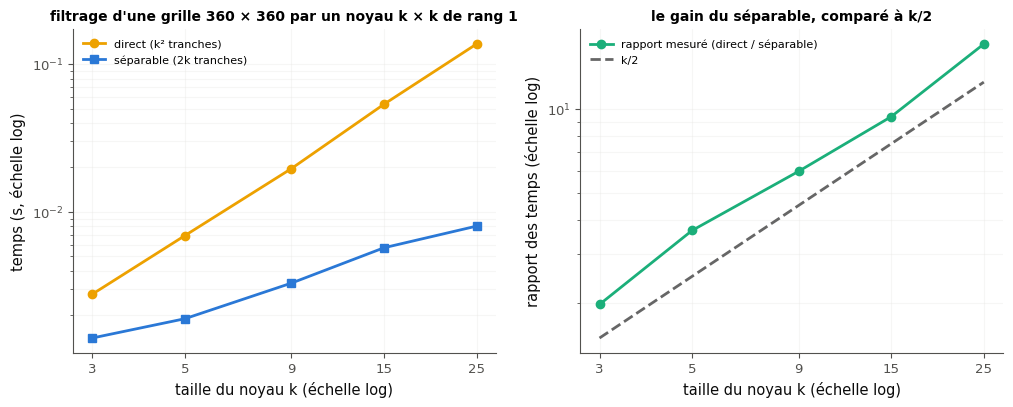

✅ Ex M21.25 : tes deux filtrages sont justes, et leurs coûts sont dessinés.


In [45]:
def direct_25(X, a, b):
    """The valid sliding sum of the grid X by the k × k kernel K = outer(a, b): the sum of the k² slices of X shifted
    by (u, v), each multiplied by K[u, v]."""
    K = np.outer(a, b)
    rows, cols = X.shape[0] - K.shape[0] + 1, X.shape[1] - K.shape[1] + 1
    out = np.zeros((rows, cols))
    for u in range(K.shape[0]):
        for v in range(K.shape[1]):
            out += K[u, v] * X[u:u + rows, v:v + cols]
    return out


def separable_25(X, a, b):
    """The same in two passes: k slices along the columns (shifted by u rows) multiplied by a[u], then k slices of
    the result along the rows (shifted by v columns) multiplied by b[v]."""
    rows, cols = X.shape[0] - len(a) + 1, X.shape[1] - len(b) + 1
    middle = np.zeros((rows, X.shape[1]))
    for u in range(len(a)):
        middle += a[u] * X[u:u + rows, :]                 # along the columns: k slices
    out = np.zeros((rows, cols))
    for v in range(len(b)):
        out += b[v] * middle[:, v:v + cols]               # then along the rows: k slices
    return out


def draw_costs_25(ax_time, ax_ratio, ks, direct_times, separable_times):
    """In ax_time: the two times against k (one line with points each), both scales logarithmic; in ax_ratio: the
    ratio direct / separable against k, and the line k / 2. No other axes."""
    ks = np.asarray(ks, dtype=float)
    direct, separable = np.asarray(direct_times, dtype=float), np.asarray(separable_times, dtype=float)
    ax_time.plot(ks, direct, "o-", color="C3", label="direct (k² tranches)")
    ax_time.plot(ks, separable, "s-", color="C0", label="séparable (2k tranches)")
    ax_time.set_xscale("log")
    ax_time.set_yscale("log")
    ax_time.set_xticks(ks, [f"{k:g}" for k in ks])
    ax_time.xaxis.set_minor_locator(plt.NullLocator())
    ax_time.set_xlabel("taille du noyau k (échelle log)")
    ax_time.set_ylabel("temps (s, échelle log)")
    ax_time.set_title("filtrage d'une grille 360 × 360 par un noyau k × k de rang 1", fontsize=10)
    ax_time.grid(True, which="both", alpha=0.3)
    ax_time.legend(fontsize=8)
    ax_ratio.plot(ks, direct / separable, "o-", color="C2", label="rapport mesuré (direct / séparable)")
    ax_ratio.plot(ks, ks / 2, "--", color="0.4", label="k/2")
    ax_ratio.set_xscale("log")
    ax_ratio.set_yscale("log")
    ax_ratio.set_xticks(ks, [f"{k:g}" for k in ks])
    ax_ratio.xaxis.set_minor_locator(plt.NullLocator())
    ax_ratio.set_xlabel("taille du noyau k (échelle log)")
    ax_ratio.set_ylabel("rapport des temps (échelle log)")
    ax_ratio.set_title("le gain du séparable, comparé à k/2", fontsize=10)
    ax_ratio.grid(True, which="both", alpha=0.3)
    ax_ratio.legend(fontsize=8)


direct_times_25 = [best_time_25(direct_25, GRID_25, *FACTORS_25[k]) for k in KS_25]
separable_times_25 = [best_time_25(separable_25, GRID_25, *FACTORS_25[k]) for k in KS_25]
answer_M21_25a = [25 * 25, 2 * 25]
ratio_25 = direct_times_25[-1] / separable_times_25[-1]
offered_25 = {"A": 2, "B": 12.5, "C": 625}
answer_M21_25b = min(offered_25, key=lambda letter: abs(math.log(offered_25[letter] / ratio_25)))
a_25, b_25 = FACTORS_25[25]
answer_M21_25c = bool(np.allclose(direct_25(GRID_25, a_25, b_25), separable_25(GRID_25, a_25, b_25), rtol=0, atol=1e-9))
for k_25, t_direct_25, t_separable_25 in zip(KS_25, direct_times_25, separable_times_25):
    print(f"k = {k_25:2d} : direct {1000 * t_direct_25:7.2f} ms, séparable {1000 * t_separable_25:6.2f} ms, rapport "
          f"{t_direct_25 / t_separable_25:5.1f} (k/2 = {k_25 / 2})")
print("a)", answer_M21_25a, " b)", answer_M21_25b, f"(rapport mesuré {ratio_25:.1f})", " c)", answer_M21_25c,
      "; plus grand écart :", f"{np.max(np.abs(direct_25(GRID_25, a_25, b_25) - separable_25(GRID_25, a_25, b_25))):.1e}")

with checked("M21.25"):
    results_25 = []

    def report_25(ok, success, failure):
        """One ✅ line, or one ❌ line that stops the check there (the figure is shown when it exists)."""
        results_25.append(bool(ok))
        print(("✅ " + success) if ok else ("❌ " + failure))
        if not ok:
            raise StopCheck

    rng_c25 = np.random.default_rng(5525)
    for name_c25, function_c25 in (("direct_25", direct_25), ("separable_25", separable_25)):
        wrong_c25 = []
        for shape_c25, k_c25 in (((12, 10), 3), ((9, 14), 4), ((8, 8), 8), ((7, 11), 1)):
            X_c25 = rng_c25.standard_normal(shape_c25)
            a_c25, b_c25 = rng_c25.standard_normal(k_c25), rng_c25.standard_normal(k_c25)
            want_c25 = scipy.signal.correlate2d(X_c25, np.outer(a_c25, b_c25), "valid")
            got_c25 = function_c25(X_c25.copy(), a_c25.copy(), b_c25.copy())
            where_c25 = f"une grille {shape_c25[0]} × {shape_c25[1]}, k = {k_c25}"
            if got_c25 is None or np.shape(got_c25) != want_c25.shape:
                wrong_c25.append(f"{where_c25} : attendu la forme {want_c25.shape}, reçu "
                                 + ("None" if got_c25 is None else f"la forme {np.shape(got_c25)}"))
            elif not np.allclose(np.asarray(got_c25, dtype=float), want_c25):
                wrong_c25.append(f"{where_c25} : la bonne forme, mais un écart de "
                                 f"{np.max(np.abs(np.asarray(got_c25, dtype=float) - want_c25)):.3g} avec "
                                 "scipy.signal.correlate2d")
        report_25(not wrong_c25, f"{name_c25} : juste sur quatre grilles que tu ne vois pas (comparé à "
                  "scipy.signal.correlate2d)", f"{name_c25}, " + " ; ".join(wrong_c25[:2]))
    if not filled(direct_times_25, separable_times_25):
        print("⏳ Ex M21.25 : la figure attend tes temps, direct_times_25 et separable_times_25.")
        raise StopCheck
    times_c25 = [np.asarray(times, dtype=float).ravel() for times in (direct_times_25, separable_times_25)]
    report_25(all(t.shape == (len(KS_25),) and np.all(t > 0) for t in times_c25),
              "tes temps : cinq nombres positifs par fonction, un par k de KS_25",
              "direct_times_25 et separable_times_25 doivent avoir un temps positif par k de KS_25")
    fig_25, (ax_time_25, ax_ratio_25) = plt.subplots(1, 2, figsize=(12, 4.2))
    try:
        opened_25 = drawn(draw_costs_25, ax_time_25, ax_ratio_25, list(KS_25), times_c25[0].tolist(),
                          times_c25[1].tolist())

        def through_25(ax, ys):
            """True when one line of ax passes by all the points (k, y) of KS_25 and ys."""
            return any(np.asarray(line.get_xdata(), dtype=float).shape == (len(KS_25),)
                       and np.allclose(np.asarray(line.get_xdata(), dtype=float), KS_25)
                       and np.allclose(np.asarray(line.get_ydata(), dtype=float), ys, rtol=1e-9) for line in ax.lines)

        report_25(not opened_25, "draw_costs_25 dessine dans les axes reçus",
                  "draw_costs_25 doit dessiner dans les deux axes reçus, sans ouvrir de figure")
        report_25(through_25(ax_time_25, times_c25[0]) and through_25(ax_time_25, times_c25[1]),
                  "les deux temps sont tracés contre k", "il manque, dans le premier axe, une courbe des temps contre k "
                  "(une par fonction, une valeur par k de KS_25)")
        report_25(ax_time_25.get_xscale() == "log" and ax_time_25.get_yscale() == "log",
                  "les temps sont en échelles logarithmiques", "mets les deux échelles du premier axe en logarithmique "
                  "(ax.set_xscale(\"log\"), ax.set_yscale(\"log\"))")
        report_25(through_25(ax_ratio_25, times_c25[0] / times_c25[1]) and through_25(ax_ratio_25, np.array(KS_25) / 2),
                  "le rapport des temps est tracé à côté de k/2", "il manque, dans le second axe, le rapport des temps "
                  "(direct / séparable) contre k, ou la droite k/2")
    except StopCheck:
        plt.show()
        raise
    except BaseException:
        plt.close(fig_25)
        raise
    plt.show()
    verdict("M21.25", all(results_25), "tes deux filtrages sont justes, et leurs coûts sont dessinés.", "")

In [46]:
wbm.record("M21.25a", [25 * 25, 25 + 25],
           mistakes={"deux passes de k multiplications chacune": [25 * 25, 25],
                     "dans l'ordre : en direct, puis en deux passes": [25 + 25, 25 * 25]})
wbm.record("M21.25b", "B",
           mistakes={"relis tes deux temps pour k = 25 : le rapport se calcule direct / séparable, et se compare aux "
                     "trois valeurs sur une échelle logarithmique (par leurs rapports, pas par leurs différences)": "A",
                     "625 est le nombre de multiplications du filtrage direct, pas le rapport des temps": "C"})
rng_25r = np.random.default_rng(5535)
grid_25r = rng_25r.standard_normal((360, 360))
a_25r, b_25r = {k: (rng_25r.standard_normal(k), rng_25r.standard_normal(k)) for k in [3, 5, 9, 15, 25]}[25]
two_passes_25r = scipy.signal.correlate2d(scipy.signal.correlate2d(grid_25r, a_25r[:, None], "valid"), b_25r[None, :],
                                          "valid")
wbm.record("M21.25c", bool(np.allclose(scipy.signal.correlate2d(grid_25r, np.outer(a_25r, b_25r), "valid"),
                                       two_passes_25r, rtol=0, atol=1e-9)),
           mistakes={"si tes deux fonctions passent la vérification, compare leurs sorties par np.allclose(..., rtol=0, "
                     "atol=1e-9)": False})

WBM_ANSWER {"decimals": 0, "element_hashes": ["3b25bd672c17ab6aa4ccc3feaac5d9707ba35e434ab89787ddbbb156216fdae4", "e0a20796fb78fc0a7b25a94f31fe20f568a41706de61ae09a09eb6872091ea06"], "hash": "61cec27be3cdc9faae1caeb11a164c7668d0f5b6ff92143a7aaf7d3bf7623586", "id": "M21.25a", "integer": true, "kind": "array", "mistakes": {"187d274fe8808b7112333cdc1eb7198a5f0068133143f9d0cc040e69e661ec08": "deux passes de k multiplications chacune", "ed8acbbb3d2c318c4aef994c135b3f855da01a539d5f01a9281763ddcd8a7f82": "dans l'ordre : en direct, puis en deux passes"}, "shape": [2]}
📝 Ex M21.25a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"hash": "5a147dbbea894e850d7d617e678229aaa8999dd9670e8680c5e575fafa5e534c", "id": "M21.25b", "kind": "str", "mistakes": {"9165c122ef8401ba3a6c35eaa0898773e8263fc955ff617e7f987531f1687725": "relis tes deux temps pour k = 25 : le rapport se calcule direct / séparable, et se compare aux trois valeurs sur une échelle logarithmique (par leurs rapports, pas par leurs d

**Après la figure**, dans ta copie : pourquoi le temps suit-il le nombre de tranches ? Pour quels $k$ le séparable vaut-il la peine ? Pourquoi la passe intermédiaire a-t-elle un peu plus de valeurs que la sortie, et que devient le compte « environ $2k$ » pour une très grande grille ? Que ferais-tu pour un noyau de rang 2 ?

💡 a) $[625, 50]$ multiplications par valeur de sortie pour $k = 25$, selon les comptes de la fiche (en deux passes, la passe intermédiaire a un peu plus de valeurs que la sortie). b) (B) : le rapport mesuré pour $k = 25$ est de l'ordre de 12 à 17 (il dépend de la machine), proche de $\frac k2 = 12{,}5$ ; pour $k = 3$, il n'est que de 1,5 à 2. c) Vrai : l'écart est de l'ordre de $10^{-13}$. Chaque passe est une addition de tranches de même taille : le temps suit le nombre de tranches, $k^2$ contre $2k$, et le séparable ne vaut la peine qu'à partir de noyaux moyens.

### Ex M21.26 — La carte des recouvrements d'une convolution transposée : un damier ou pas, selon k et s 🎨 ★ ⏱️ 15 min
**Objectif :** dessiner, en chaque case de la sortie d'une convolution transposée en deux dimensions, le nombre de tampons qui la couvrent, et voir quand apparaît un damier.  
**Prérequis :** fiche §5 ; Ex M21.7 · **Parcours :** C, E

Une convolution transposée de pas $s$ imprime, pour chaque valeur d'entrée $y_i$, un tampon $y_i\,\mathbf{w}$ à partir de la case $s\,i$ (fiche §5) ; une case de la sortie reçoit un tampon de chaque $i$ tel que $0 \le j - s\,i \le k - 1$. En deux dimensions, avec une entrée de $m \times m$ valeurs et des noyaux $k \times k$ de pas $s$ selon les deux axes, le nombre de tampons qui couvrent la case $(j, j')$ est le **produit** des comptes des deux axes. Écris :
- `coverage_26(m, k, s)` : en une dimension, le nombre de tampons qui couvrent chaque case, un tableau d'entiers de longueur $(m - 1)s + k$ ;
- `coverage_map_26(m, k, s)` : la carte en deux dimensions, le tableau des produits des comptes des deux axes ;
- `draw_maps_26(fig, axes, m, pairs)` : une carte par couple $(k, s)$ de `pairs`, dans les axes de `axes`, dans cet ordre : l'image de `coverage_map_26(m, k, s)` (`ax.imshow`), sa barre de couleurs (`fig.colorbar(image, ax=ax)`) et un titre qui donne $(k, s)$ ; sans ouvrir d'autre figure.

La cellule fournie donne $m = 6$ (`M_26`) et les couples $(k, s) = (5, 2)$, $(6, 2)$, $(7, 3)$ et $(9, 3)$ (`PAIRS_26`). La vérification compare ta carte à des tampons posés un par un, sur ces quatre couples et sur des cas que tu ne vois pas, puis appelle `draw_maps_26` et regarde le dessin, en s'arrêtant au premier ❌ : chaque carte, sa barre de couleurs et son titre.

In [47]:
M_26 = 6                                                   # a 6 × 6 input
PAIRS_26 = [(5, 2), (6, 2), (7, 3), (9, 3)]                # (k, s): k × k kernels, step s along both axes

(k, s) = (5, 2) : 15 cases par axe, comptes [1, 1, 2, 2, 3, 2, 3, 2, 3, 2, 3, 2, 2, 1, 1] ; à l'intérieur, la carte prend les valeurs [4, 6, 9]
(k, s) = (6, 2) : 16 cases par axe, comptes [1, 1, 2, 2, 3, 3, 3, 3, 3, 3, 3, 3, 2, 2, 1, 1] ; à l'intérieur, la carte prend les valeurs [9]
(k, s) = (7, 3) : 22 cases par axe, comptes [1, 1, 1, 2, 2, 2, 3, 2, 2, 3, 2, 2, 3, 2, 2, 3, 2, 2, 2, 1, 1, 1] ; à l'intérieur, la carte prend les valeurs [4, 6, 9]
(k, s) = (9, 3) : 24 cases par axe, comptes [1, 1, 1, 2, 2, 2, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 2, 2, 2, 1, 1, 1] ; à l'intérieur, la carte prend les valeurs [9]
✅ coverage_map_26 : juste sur 8 cas (tampons posés un par un)
✅ draw_maps_26 dessine dans la figure reçue
✅ (k, s) = (5, 2) : la carte est dessinée
✅ … avec sa barre de couleurs
✅ … et un titre qui donne (k, s)
✅ (k, s) = (6, 2) : la carte est dessinée
✅ … avec sa barre de couleurs
✅ … et un titre qui donne (k, s)
✅ (k, s) = (7, 3) : la carte est dessinée
✅ … avec sa barre de couleu

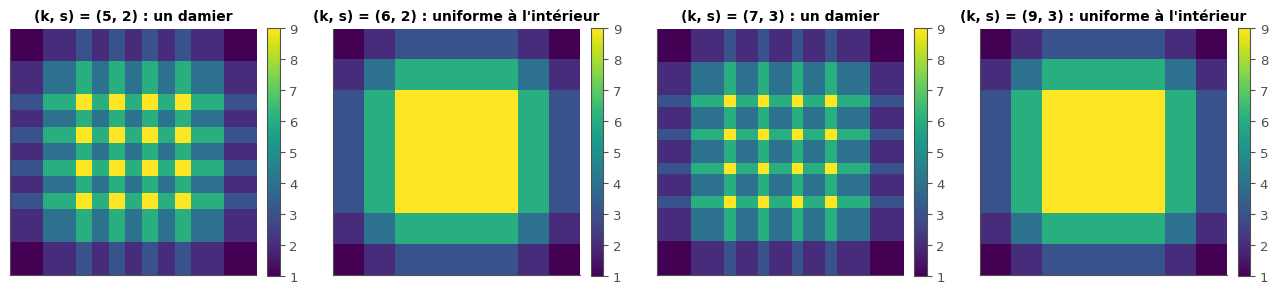

✅ Ex M21.26 : les quatre cartes des recouvrements sont dessinées.


In [48]:
def coverage_26(m, k, s):
    """The number of stamps that cover each cell of a 1-D transposed convolution: m inputs, a kernel of length k,
    the step s, no padding. A 1-D array of integers, of length (m - 1) s + k."""
    counts = np.zeros((m - 1) * s + k, dtype=int)
    for i in range(m):
        counts[s * i:s * i + k] += 1                   # the stamp of the input i covers the cells s i to s i + k - 1
    return counts


def coverage_map_26(m, k, s):
    """The same for an m × m input, k × k kernels and the step s along both axes: the 2-D array of the products of
    the counts of the two axes."""
    counts = coverage_26(m, k, s)
    return np.outer(counts, counts)


def draw_maps_26(fig, axes, m, pairs):
    """One map per (k, s) of pairs, in the axes of `axes` (in this order): the image of coverage_map_26(m, k, s),
    its colour bar and a title that gives (k, s). No other figure."""
    for ax, (k, s) in zip(axes, pairs):
        counts = coverage_map_26(m, k, s)
        image = ax.imshow(counts, cmap="viridis", interpolation="nearest")
        fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
        ax.set_title(f"(k, s) = ({k}, {s}) : " + ("uniforme à l'intérieur" if k % s == 0 else "un damier"), fontsize=10)
        ax.set_xticks([])
        ax.set_yticks([])


for k_26, s_26 in PAIRS_26:
    counts_26 = coverage_26(M_26, k_26, s_26)
    inside_26 = counts_26[k_26 - 1:(M_26 - 1) * s_26 + 1]
    print(f"(k, s) = ({k_26}, {s_26}) : {len(counts_26)} cases par axe, comptes {counts_26.tolist()} ; à l'intérieur, "
          f"la carte prend les valeurs {sorted(set(np.outer(inside_26, inside_26).ravel().tolist()))}")

with checked("M21.26"):
    results_26 = []

    def report_26(ok, success, failure):
        """One ✅ line, or one ❌ line that stops the check there."""
        results_26.append(bool(ok))
        print(("✅ " + success) if ok else ("❌ " + failure))
        if not ok:
            raise StopCheck

    def stamps_c26(m, k, s):
        """The stamps on each cell of a 1-D transposed convolution, put one by one."""
        counts = np.zeros((m - 1) * s + k, dtype=int)
        for i in range(m):
            counts[s * i:s * i + k] += 1
        return counts

    cases_c26 = [(M_26, k, s) for k, s in PAIRS_26] + [(3, 4, 4), (5, 2, 3), (4, 1, 1), (2, 7, 5)]
    wrong_c26 = []
    for m_c26, k_c26, s_c26 in cases_c26:
        want_c26 = np.outer(stamps_c26(m_c26, k_c26, s_c26), stamps_c26(m_c26, k_c26, s_c26))
        got_c26 = coverage_map_26(m_c26, k_c26, s_c26)
        if got_c26 is None or np.shape(got_c26) != want_c26.shape or not np.array_equal(got_c26, want_c26):
            wrong_c26.append(f"m = {m_c26}, k = {k_c26}, s = {s_c26} : attendu une carte {want_c26.shape}, reçu "
                             + ("None" if got_c26 is None else f"une carte {np.shape(got_c26)}"
                                + (" aux comptes différents" if np.shape(got_c26) == want_c26.shape else "")))
    report_26(not wrong_c26, f"coverage_map_26 : juste sur {len(cases_c26)} cas (tampons posés un par un)",
              "coverage_map_26, " + " ; ".join(wrong_c26[:2]))
    fig_26, axes_26 = plt.subplots(1, len(PAIRS_26), figsize=(16, 3.9))
    try:
        opened_26 = drawn(draw_maps_26, fig_26, list(axes_26), M_26, list(PAIRS_26))
        report_26(not opened_26, "draw_maps_26 dessine dans la figure reçue",
                  "draw_maps_26 doit dessiner dans les axes reçus, sans ouvrir de figure")
        for ax_c26, (k_c26, s_c26) in zip(axes_26, PAIRS_26):
            want_c26 = np.outer(stamps_c26(M_26, k_c26, s_c26), stamps_c26(M_26, k_c26, s_c26))
            images_c26 = [image for image in ax_c26.images if np.shape(image.get_array()) == want_c26.shape
                          and np.array_equal(np.asarray(image.get_array()), want_c26)]
            report_26(images_c26, f"(k, s) = ({k_c26}, {s_c26}) : la carte est dessinée",
                      f"il manque, dans l'axe de (k, s) = ({k_c26}, {s_c26}), l'image de coverage_map_26 "
                      f"({want_c26.shape[0]} × {want_c26.shape[1]} cases ; ax.imshow)")
            report_26(images_c26[0].colorbar is not None, "… avec sa barre de couleurs",
                      f"il manque la barre de couleurs de (k, s) = ({k_c26}, {s_c26}) (fig.colorbar(image, ax=ax))")
            numbers_c26 = [int(n) for n in re.findall(r"\d+", ax_c26.get_title())]
            report_26(k_c26 in numbers_c26 and s_c26 in numbers_c26, "… et un titre qui donne (k, s)",
                      f"le titre de l'axe de (k, s) = ({k_c26}, {s_c26}) doit donner k et s")
    except StopCheck:
        plt.show()
        raise
    except BaseException:
        plt.close(fig_26)
        raise
    plt.show()
    verdict("M21.26", all(results_26), "les quatre cartes des recouvrements sont dessinées.", "")

**Après la figure**, dans ta copie : pour quels couples la carte est-elle uniforme à l'intérieur, et quelle valeur y prend-elle ? Pourquoi un damier apparaît-il quand $s$ ne divise pas $k$ ? Quelles valeurs prend la carte à l'intérieur pour $(5, 2)$ ? Pourquoi les bords reçoivent-ils moins de tampons dans tous les cas ?

💡 Pour $(5, 2)$ et $(7, 3)$, $s$ ne divise pas $k$ : le long de chaque axe, les cases intérieures sont couvertes tantôt par 2, tantôt par 3 tampons, et la carte, produit des deux axes, mélange 4, 6 et 9 : un damier. Pour $(6, 2)$ et $(9, 3)$, chaque axe donne 3 partout à l'intérieur, et la carte vaut 9 sur tout l'intérieur. Les cartes ont $15 \times 15$, $16 \times 16$, $22 \times 22$ et $24 \times 24$ cases, $(m - 1)s + k$ avec $m = 6$ ; les bords reçoivent moins de tampons dans tous les cas.

## Partie C · Déboguer, tester

Fiche §2, §3, §5 et §6. Trois erreurs classiques qui ne lèvent aucune erreur Python ; un test de propriété pour la matrice de Toeplitz. La vérification de M21.28 s'appuie sur la référence (`ref_conv`), pour ne pas dépendre de ton code.

In [49]:
ref_conv = wbm.load_mymath("ref", alias="mymath_ref").convolution   # the reference: the check of M21.28

### Ex M21.27 — Chasse à l'erreur : un noyau non retourné, des recouvrements supposés réguliers, un noyau de rang 2 « séparé » 🐛 ★ ⏱️ 20 min
**Objectif :** reconnaître trois erreurs classiques qui ne lèvent aucune erreur Python et passent une vérification mal choisie, puis les corriger.  
**Prérequis :** fiche §1, §5 et §6 ; Ex M21.7 et M21.22 · **Parcours :** C, E

Un collègue a écrit trois fonctions (cellule fournie) ; chacune a l'erreur que nomme le titre, aucune ne lève d'erreur Python, et chacune a passé la vérification qu'il a faite :
1. `poly_product(p, q)` doit rendre les coefficients du produit de deux polynômes, du terme constant au terme de plus haut degré ; elle renvoie `np.correlate(p, q, "full")`. Il l'a vérifiée sur $(1 + 2X)(2 + 5X + 2X^2)$, dont le second facteur a des coefficients palindromes, et l'applique à $(1 + 2X)(3 - X + 4X^2)$ (`P_27`, `Q_27`).
2. `n_covers(k, s)` doit rendre le nombre de tampons qui couvrent une case intérieure d'une convolution transposée de noyau de longueur $k$ et de pas $s$ (fiche §5) ; elle renvoie `k // s`. Il l'a vérifiée sur $(k, s) = (6, 2)$, $(9, 3)$ et $(8, 4)$.
3. `separate(K)` doit rendre les deux facteurs d'un noyau séparable ; elle rend la première colonne de $\mathbf{K}$ et sa première ligne divisée par $K_{0,0}$, sans regarder le rang. Il l'a vérifiée sur un produit extérieur, et l'applique au noyau $\begin{pmatrix} 2 & 1 & 3 \\ 4 & 2 & 5 \\ 2 & 1 & 3 \end{pmatrix}$ (`K_27`).

À faire : écris `poly_product_fixed(p, q)`, `n_covers_fixed(j, k, s, m)` (le nombre de tampons qui couvrent la case $j$ d'une convolution transposée de $m$ valeurs d'entrée, de noyau de longueur $k$ et de pas $s$ : le nombre de $i \in \{0, \ldots, m - 1\}$ tels que $0 \le j - s\,i \le k - 1$) et `separate_fixed(K)` (qui rend les deux facteurs d'un noyau de rang 1, et `None` sinon), puis réponds :
- a) les coefficients de $(1 + 2X)(3 - X + 4X^2)$, avec `poly_product_fixed` (la valeur que donne le calcul) ;
- b) pour une convolution transposée de noyau de longueur $k = 8$, de pas $s = 3$ et de $m = 6$ valeurs d'entrée, les nombres de tampons qui couvrent les cases 9, 10 et 11, avec `n_covers_fixed` (une liste de 3 entiers) ;
- c) le plus grand écart, en valeur absolue, entre `K_27` et le produit extérieur des deux facteurs que rend le `separate` du collègue (la valeur que donne le calcul) ;
- d) vrai ou faux : ta `separable_factors` (M21.22) rend `None` pour ce noyau ;
- e) une question à part, sur le mode « même taille » d'un noyau de longueur paire, où NumPy et PyTorch diffèrent d'une case : pour la somme glissante de poids $(2, -3)$ et $\mathbf{x} = (6, 2, 7, 1, 8, 3)$ (`W_27`, `X_27`), ce que rend `np.convolve` en mode même taille, avec les poids retournés (la valeur que donne le calcul).

La vérification essaie tes corrections sur des cas que tu ne vois pas : des polynômes aux coefficients non palindromes, toutes les cases de convolutions transposées où $s$ divise $k$ ou pas, des noyaux de rang 1 (dont un avec $K_{0,0} = 0$) et de rang 2.

In [50]:
P_27, Q_27 = np.array([1.0, 2.0]), np.array([3.0, -1.0, 4.0])      # (1 + 2X)(3 − X + 4X²)
K_27 = np.array([[2.0, 1.0, 3.0], [4.0, 2.0, 5.0], [2.0, 1.0, 3.0]])
X_27, W_27 = np.array([6.0, 2.0, 7.0, 1.0, 8.0, 3.0]), np.array([2.0, -3.0])


# The colleague's code
def poly_product(p, q):
    """The coefficients of the product of two polynomials, from the constant term to the highest degree."""
    return np.correlate(p, q, "full")


def n_covers(k, s):
    """The number of stamps that cover an inner cell of a transposed convolution: kernel of length k, step s."""
    return k // s


def separate(K):
    """The two factors (u, v) of a separable kernel, K = outer(u, v)."""
    K = np.asarray(K, dtype=float)
    return K[:, 0].copy(), K[0, :] / K[0, 0]


# The colleague's checks: all pass
print("(1) (1 + 2X)(2 + 5X + 2X²) :", poly_product([1, 2], [2, 5, 2]).tolist(), "(attendu [2, 9, 12, 4])")
print("(2) n_covers : (k, s) = (6, 2) →", n_covers(6, 2), "; (9, 3) →", n_covers(9, 3), "; (8, 4) →", n_covers(8, 4),
      "(comptés à la main sur une case intérieure : k/s)")
u_c27, v_c27 = separate(np.outer([1, 2], [3, 1, 2]))
print("(3) un produit extérieur reconstruit :", bool(np.allclose(np.outer(u_c27, v_c27), np.outer([1, 2], [3, 1, 2]))))

(1) (1 + 2X)(2 + 5X + 2X²) : [2, 9, 12, 4] (attendu [2, 9, 12, 4])
(2) n_covers : (k, s) = (6, 2) → 3 ; (9, 3) → 3 ; (8, 4) → 2 (comptés à la main sur une case intérieure : k/s)
(3) un produit extérieur reconstruit : True


In [51]:
def poly_product_fixed(p, q):
    """The coefficients of the product of two polynomials, from the constant term to the highest degree."""
    return np.convolve(p, q)              # a product of polynomials is a convolution: np.correlate does not flip q


def n_covers_fixed(j, k, s, m):
    """The number of stamps that cover the cell j of a transposed convolution of m inputs, kernel of length k, step s:
    the number of i in {0, ..., m - 1} such that 0 <= j - s i <= k - 1."""
    return sum(1 for i in range(m) if 0 <= j - s * i <= k - 1)


def separate_fixed(K):
    """The two factors (u, v) of K = outer(u, v) when K has rank 1; None otherwise."""
    return mymath.convolution.separable_factors(K)         # tests the rank, and works when K[0, 0] = 0


answer_M21_27a = poly_product_fixed(P_27, Q_27).tolist()
answer_M21_27b = [n_covers_fixed(j, 8, 3, 6) for j in (9, 10, 11)]
u_27, v_27 = separate(K_27)
answer_M21_27c = float(np.max(np.abs(K_27 - np.outer(u_27, v_27))))
answer_M21_27d = mymath.convolution.separable_factors(K_27) is None
answer_M21_27e = np.convolve(X_27, W_27[::-1], "same").tolist()
pytorch_27 = [float(W_27[0] * X_27[i] + W_27[1] * (X_27[i + 1] if i + 1 < len(X_27) else 0)) for i in range(len(X_27))]
print("a)", answer_M21_27a, "; le collègue :", poly_product(P_27, Q_27).tolist())
print("b)", answer_M21_27b, "; le collègue :", n_covers(8, 3), "partout ; la carte des 23 cases :",
      [n_covers_fixed(j, 8, 3, 6) for j in range((6 - 1) * 3 + 8)])
print("c)", answer_M21_27c, "; produit extérieur du collègue :\n", np.outer(u_27, v_27))
print("d)", answer_M21_27d, "; s₂/s₁ =", round(float(np.divide(*np.linalg.svd(K_27, compute_uv=False)[[1, 0]])), 4))
print("e)", answer_M21_27e, "; PyTorch (zéro en trop à droite) :", pytorch_27)


results_27, parts_27 = [], []


def report_27(ok, success, failure):
    results_27.append(bool(ok))
    print(("✅ " + success) if ok else ("❌ " + failure))


def call_27(part, name, function, *args):
    """function(*args); an error of the learner's code becomes one ❌ line that names the function (the check of this
    part stops there, the final verdict stays)."""
    try:
        return function(*args)
    except (NotImplementedError, MymathMissingError):
        raise
    except Exception as exc:  # noqa: BLE001 - the learner's error, reported with the name of the function
        report_27(False, "", f"({part}) {name} : ton code lève {type(exc).__name__} : {str(exc)[:200]}")
        parts_27.append(part)
        raise StopCheck from None


rng_c27 = np.random.default_rng(5521)
with checked("M21.27"):                                       # (1) poly_product_fixed
    wrong_27 = []
    for n_c27, m_c27 in ((2, 4), (4, 2), (3, 3), (5, 1), (1, 3)):
        p_c27 = rng_c27.integers(-5, 6, size=n_c27).astype(float)
        q_c27 = rng_c27.integers(-5, 6, size=m_c27).astype(float)
        q_c27[0], q_c27[-1] = 2.0, -3.0 if m_c27 > 1 else 2.0         # never a palindrome
        want_c27 = np.array([sum(p_c27[i] * q_c27[d - i] for i in range(n_c27) if 0 <= d - i < m_c27)
                             for d in range(n_c27 + m_c27 - 1)])          # the product, expanded term by term
        got_c27 = call_27(1, "poly_product_fixed", poly_product_fixed, p_c27.copy(), q_c27.copy())
        if got_c27 is None or np.shape(got_c27) != want_c27.shape or not np.allclose(got_c27, want_c27):
            wrong_27.append(f"p = {p_c27.astype(int).tolist()}, q = {q_c27.astype(int).tolist()} : attendu "
                            f"{want_c27.astype(int).tolist()}, reçu {shown(got_c27, 3)}"[:260])
    report_27(not wrong_27, "(1) poly_product_fixed : des polynômes aux coefficients non palindromes, de degrés variés "
              "(comparé au développement terme à terme)", "(1) poly_product_fixed : " + " ; ".join(wrong_27[:2]))
    parts_27.append(1)

with checked("M21.27"):                                       # (2) n_covers_fixed
    wrong_27 = []
    for k_c27, s_c27, m_c27 in ((8, 3, 6), (5, 2, 4), (7, 3, 5), (6, 2, 3), (4, 5, 3), (1, 1, 4)):
        stamps_c27 = np.zeros((m_c27 - 1) * s_c27 + k_c27, dtype=int)
        for i_c27 in range(m_c27):
            stamps_c27[s_c27 * i_c27:s_c27 * i_c27 + k_c27] += 1          # the stamps, put one by one
        got_c27 = [call_27(2, "n_covers_fixed", n_covers_fixed, j_c27, k_c27, s_c27, m_c27)
                   for j_c27 in range(len(stamps_c27))]
        if got_c27 != stamps_c27.tolist():
            wrong_27.append(f"(k, s, m) = ({k_c27}, {s_c27}, {m_c27}), toutes les cases : attendu "
                            f"{stamps_c27.tolist()}, reçu {got_c27!r}"[:220])
    report_27(not wrong_27, "(2) n_covers_fixed : toutes les cases de six convolutions transposées, s divisant k ou "
              "pas (tampons posés un par un)", "(2) n_covers_fixed : " + " ; ".join(wrong_27[:2]))
    parts_27.append(2)

with checked("M21.27"):                                       # (3) separate_fixed
    wrong_27 = []
    rank_one_c27 = [np.outer([0.0, 2.0, -1.0], [3.0, 1.0, 2.0]), np.outer([1.5, -2.0], [0.0, 3.0, 1.0, -2.0]),
                    np.outer(rng_c27.normal(size=4), rng_c27.normal(size=3))]
    rank_two_c27 = [np.array([[1.0, 2.0, 1.0], [2.0, 4.0, 3.0]]), rng_c27.normal(size=(3, 3))]
    for kernel_c27 in rank_one_c27:
        got_c27 = call_27(3, "separate_fixed", separate_fixed, kernel_c27.copy())
        if (not isinstance(got_c27, tuple) or len(got_c27) != 2
                or np.shape(np.outer(*got_c27)) != kernel_c27.shape or not np.allclose(np.outer(*got_c27), kernel_c27)):
            wrong_27.append(f"un noyau de rang 1, {np.round(kernel_c27, 2).tolist()} : attendu deux facteurs dont "
                            f"le produit extérieur le redonne, reçu {shown(got_c27, 3)}"[:260])
    for kernel_c27 in rank_two_c27:
        got_c27 = call_27(3, "separate_fixed", separate_fixed, kernel_c27.copy())
        if got_c27 is not None:
            wrong_27.append(f"un noyau de rang 2 ou plus, {np.round(kernel_c27, 2).tolist()} : attendu None"[:160])
    report_27(not wrong_27, "(3) separate_fixed : des noyaux de rang 1 (dont un avec K[0, 0] = 0) et de rang 2 ou plus",
              "(3) separate_fixed : " + " ; ".join(wrong_27[:2]))
    parts_27.append(3)

if len(set(parts_27)) == 3:
    verdict("M21.27", all(results_27), "les trois fonctions corrigées passent tous les cas.",
            "relis les lignes ❌ ci-dessus.")

a) [3.0, 5.0, 2.0, 8.0] ; le collègue : [4.0, 7.0, 1.0, 6.0]
b) [3, 3, 2] ; le collègue : 2 partout ; la carte des 23 cases : [1, 1, 1, 2, 2, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 2, 2, 1, 1, 1]
c) 1.0 ; produit extérieur du collègue :
 [[2. 1. 3.]
 [4. 2. 6.]
 [2. 1. 3.]]
d) True ; s₂/s₁ = 0.0434
e) [-18.0, 6.0, -17.0, 11.0, -22.0, 7.0] ; PyTorch (zéro en trop à droite) : [6.0, -17.0, 11.0, -22.0, 7.0, 6.0]
✅ (1) poly_product_fixed : des polynômes aux coefficients non palindromes, de degrés variés (comparé au développement terme à terme)
✅ (2) n_covers_fixed : toutes les cases de six convolutions transposées, s divisant k ou pas (tampons posés un par un)
✅ (3) separate_fixed : des noyaux de rang 1 (dont un avec K[0, 0] = 0) et de rang 2 ou plus
✅ Ex M21.27 : les trois fonctions corrigées passent tous les cas.


In [52]:
p_27r, q_27r = [1, 2], [3, -1, 4]
product_27r = [sum(p_27r[i] * q_27r[m - i] for i in range(len(p_27r)) if 0 <= m - i < len(q_27r))
               for m in range(len(p_27r) + len(q_27r) - 1)]                    # the coefficients, by the definition
wbm.record("M21.27a", product_27r,
           mistakes={"le produit de deux polynômes est une convolution : np.correlate ne retourne pas son second "
                     "argument": np.correlate(p_27r, q_27r, "full").tolist()})
stamps_27r = np.zeros((6 - 1) * 3 + 8, dtype=int)
for i_27r in range(6):
    stamps_27r[3 * i_27r:3 * i_27r + 8] += 1                                   # the stamps, put one by one
wbm.record("M21.27b", stamps_27r[[9, 10, 11]].tolist(),
           mistakes={"s ne divise pas k : le nombre de tampons change d'une case à l'autre ; compte les i tels que "
                     "0 ≤ j − s i ≤ k − 1": [8 // 3] * 3,
                     "s ne divise pas k : les cases intérieures ne reçoivent pas toutes le même nombre de tampons ; "
                     "compte les i tels que 0 ≤ j − s i ≤ k − 1": [8 // 3 + 1] * 3})
kernel_27r = np.array([[2.0, 1.0, 3.0], [4.0, 2.0, 5.0], [2.0, 1.0, 3.0]])
bogus_27r = np.outer(kernel_27r[:, 0], kernel_27r[0, :] / kernel_27r[0, 0])
wbm.record("M21.27c", float(np.max(np.abs(kernel_27r - bogus_27r))), decimals=2,
           mistakes={"compare K au produit extérieur case par case : le noyau n'est pas de rang 1": 0.0})
wbm.record("M21.27d", bool(np.linalg.matrix_rank(kernel_27r) > 1),
           mistakes={"le noyau est de rang 2 : sa deuxième valeur singulière n'est pas négligeable devant la première":
                         False})
x_27r, w_27r = [6, 2, 7, 1, 8, 3], [2, -3]
wbm.record("M21.27e", np.convolve(x_27r, w_27r[::-1], "same").tolist(),
           mistakes={"c'est la version de PyTorch, le zéro en trop à droite ; NumPy le met au début":
                         [w_27r[0] * x_27r[i] + w_27r[1] * (x_27r[i + 1] if i + 1 < 6 else 0) for i in range(6)],
                     "np.convolve retourne les poids qu'on lui donne": np.convolve(x_27r, w_27r, "same").tolist()})

WBM_ANSWER {"decimals": 0, "element_hashes": ["a0072e2b7ea872f8547672775f65a56363a1f43576381ba8390d009ba425aa3b", "96cf8e8a683f4fdb5a046a2600bf9a910f2c850921022fecd4ca8c2175e02aca", "de2e68612503349de20ec4177856c2d8349d5ee99dcb6202331c21a4cdc0fecf", "3b4e904141c8de3525dd7df3bb829b86556edfcca628bf3d2430ceecc7fa9d5e"], "hash": "21e6256331364a7ac626fd5330badd75df21467267889ac56d07e98c890fc494", "id": "M21.27a", "integer": true, "kind": "array", "mistakes": {"aeac0c205f3686602c3c809c94936e0d698c027df80c203d754186c9103f2662": "le produit de deux polynômes est une convolution : np.correlate ne retourne pas son second argument"}, "shape": [4]}
📝 Ex M21.27a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["e5775041e9a275b75b22c6c77443dcadf38e0d5949face71c07bc623ccff92ab", "e9ba0cab8861b3b181ea12746f9fbb62f9fdb18b767915d7a41573811c15145a", "74ae8455b7d9e5cf39556be68d0ae1ee841811a3306259833859d4e49ef5bc33"], "hash": "3837c8aa77cdd075c1ef98c622f7a3190a19b60

**Après la vérification**, dans ta copie : pour chaque erreur, pourquoi la vérification du collègue ne la voyait-elle pas (un facteur palindrome, des couples où $s$ divise $k$, un noyau de rang 1), et quelle vérification l'aurait vue ? Écris la carte complète des tampons pour $k = 8$, $s = 3$, $m = 6$. Pour (3), quelle case de `K_27` le produit extérieur du collègue manque-t-il, et que se passerait-il avec $K_{0,0} = 0$ ? Pour e), de quel côté est le zéro en trop dans chaque bibliothèque ?

💡 (1) Un produit de polynômes est une convolution : `np.correlate` ne retourne pas son second argument, il faut `np.convolve(p, q)`. La vérification du collègue prenait un facteur palindrome, $(2, 5, 2)$, que le retournement ne change pas. a) $(1 + 2X)(3 - X + 4X^2) = 3 + 5X + 2X^2 + 8X^3$ ; la version fausse rend $(4, 7, 1, 6)$. (2) `k // s` ne vaut que si $s$ divise $k$ : sinon, le nombre de tampons change d'une case à l'autre, et il faut compter, pour la case $j$, les $i$ tels que $0 \le j - s\,i \le k - 1$. Les trois cas du collègue avaient $s$ qui divise $k$. b) $(3, 3, 2)$ pour les cases 9, 10 et 11 ; la carte complète vaut $(1, 1, 1, 2, 2, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 2, 2, 1, 1, 1)$, et la version fausse dit 2 partout. (3) Une première colonne et une première ligne ne suffisent que pour un noyau de rang 1 (et avec $K_{0,0} \ne 0$) : il faut tester le rang, par exemple avec `separable_factors`. c) L'écart maximal vaut 1, en ligne 1, colonne 2 ($5$ contre $6$), sans aucun message d'erreur. d) Vrai : le noyau est de rang 2, avec $\frac{s_2}{s_1} \approx 0{,}043$. e) $(-18, 6, -17, 11, -22, 7)$, alors que PyTorch donne $(6, -17, 11, -22, 7, 6)$ : les mêmes nombres, décalés d'une case.

### Ex M21.28 — Un test de propriété : la matrice de Toeplitz fois x égale la convolution, pour des longueurs tirées au hasard 🛠️ ★ ⏱️ 15 min
**Objectif :** écrire un test de propriété pour `toeplitz_matrix`, et s'assurer qu'il attrape une version fausse du mode même taille.  
**Prérequis :** fiche §3 ; Ex M21.20 · **Parcours :** C

Un **test de propriété** vérifie, sur beaucoup de cas tirés au hasard, une loi que tout résultat juste respecte, sans connaître la réponse de chaque cas (M17, M18). La loi, ici (fiche §3) : pour tout noyau $\mathbf{w}$ de longueur $k$, tout signal $\mathbf{x}$ de longueur $n \ge k$ et chacun des trois modes, `toeplitz_matrix(w, n, mode) @ x` égale `convolve(x, w, mode)`.

Écris `property_test_28(toeplitz_matrix, convolve)`, qui reçoit les deux fonctions à tester :
- elle tire 200 cas avec un générateur `np.random.default_rng(5538)`, créé dans la fonction : une longueur de noyau $k$ de 1 à 6, une longueur de signal $n$ de $k$ à 12, un noyau et un signal d'entiers ; puis elle ajoute les cas limites $k = 1$ et $n = k$ ;
- pour chaque cas et chaque mode (`"full"`, `"valid"`, `"same"`), elle vérifie la loi par un `assert` (avec `np.allclose`), dont le message dit **d'abord** ce qui était attendu (il commence par « expected »), **puis** le cas fautif, écrit `k = …, n = …` avec le mode ;
- elle rend le nombre de cas vérifiés.

La cellule fournie donne une version **fausse** de `toeplitz_matrix`, construite sur la référence (`ref_conv`) : `toeplitz_wrong_same_28`, dont le mode même taille garde les lignes à partir de $\lfloor k/2\rfloor$ au lieu de $\lfloor\frac{k-1}{2}\rfloor$. La vérification lance ton test sur la référence, où il doit passer (elle compte les appels, les modes et les cas limites) ; sur la version fausse, où il doit échouer par un `assert` dont le message montre un noyau de longueur paire ; puis sur **ta** librairie.

In [53]:
def toeplitz_wrong_same_28(kernel, n, mode="full"):
    """Wrong: in the mode "same", the rows kept start at k // 2 instead of (k - 1) // 2 (built on the reference)."""
    if mode != "same":
        return ref_conv.toeplitz_matrix(kernel, n, mode)
    k = len(kernel)
    return ref_conv.toeplitz_matrix(kernel, n, "full")[k // 2:k // 2 + max(n, k)]

In [54]:
def property_test_28(toeplitz_matrix, convolve):
    """200 random cases drawn with np.random.default_rng(5538), created inside: k from 1 to 6, n from k to 12, a
    kernel and a signal of integers; then the edge cases k = 1 and n = k. For each case and each mode ("full",
    "valid", "same"), assert that toeplitz_matrix(w, n, mode) @ x equals convolve(x, w, mode), with a message that
    says first what was expected, then the case (k = ..., n = ..., the mode). Return the number of cases checked."""
    rng = np.random.default_rng(5538)
    cases = []
    for _ in range(200):
        k = int(rng.integers(1, 7))
        n = int(rng.integers(k, 13))
        cases.append((rng.integers(-5, 6, size=k).astype(float), rng.integers(-5, 6, size=n).astype(float)))
    cases.append((np.array([3.0]), np.array([2.0, -1.0, 4.0, 0.0])))                       # k = 1
    cases.append((np.array([1.0, -2.0, 3.0, 2.0]), np.array([4.0, 0.0, -1.0, 5.0])))      # n = k
    for w, x in cases:
        for mode in ("full", "valid", "same"):
            got = toeplitz_matrix(w, len(x), mode) @ x
            want = convolve(x, w, mode)
            assert np.shape(got) == np.shape(want) and np.allclose(got, want), (
                f"expected toeplitz_matrix(w, n, {mode!r}) @ x = {np.round(want, 6).tolist()}, got "
                f"{np.round(got, 6).tolist()} (k = {len(w)}, n = {len(x)}, mode {mode!r}, w = {w.tolist()}, "
                f"x = {x.tolist()})")
    return len(cases)


print("sur la référence :", property_test_28(ref_conv.toeplitz_matrix, ref_conv.convolve), "cas")
try:
    property_test_28(toeplitz_wrong_same_28, ref_conv.convolve)
except AssertionError as exc:
    print("la version fausse :", str(exc)[:300])


with checked("M21.28"):
    results_28 = []

    def report_28(ok, success, failure):
        results_28.append(bool(ok))
        print(("✅ " + success) if ok else ("❌ " + failure))

    calls_28 = []

    def counted_28(toeplitz):
        """toeplitz, its calls recorded in calls_28 as (k, n, mode)."""
        def wrapper(kernel, n, mode="full"):
            calls_28.append((len(kernel), int(n), mode))
            return toeplitz(kernel, n, mode)
        return wrapper

    try:
        cases_28 = property_test_28(counted_28(ref_conv.toeplitz_matrix), ref_conv.convolve)
    except AssertionError as exc:
        print(f"❌ Ex M21.28 : ton test échoue sur la référence, qui est juste : {exc}"[:400])
        raise StopCheck from None
    report_28(isinstance(cases_28, int) and cases_28 >= 202 and len(calls_28) >= 3 * 202,
              f"sur la référence, ton test passe : {cases_28} cas, {len(calls_28)} appels de toeplitz_matrix",
              f"sur la référence, ton test rend {cases_28!r} et fait {len(calls_28)} appels de toeplitz_matrix : au "
              "moins 200 cas tirés et les deux cas limites, chacun dans les trois modes, et le nombre de cas rendu")
    report_28({mode for _, _, mode in calls_28} == {"full", "valid", "same"}, "les trois modes sont testés",
              "ton test doit appeler toeplitz_matrix dans les trois modes, \"full\", \"valid\" et \"same\"")
    report_28(any(k == 1 for k, _, _ in calls_28) and any(k == n for k, n, _ in calls_28),
              "les cas limites k = 1 et n = k sont testés", "ajoute les cas limites k = 1 et n = k")
    try:
        property_test_28(toeplitz_wrong_same_28, ref_conv.convolve)
        report_28(False, "", "ton test n'attrape pas toeplitz_wrong_same_28 (son mode même taille garde les lignes "
                  "à partir de ⌊k/2⌋)")
    except AssertionError as exc:
        message_28 = str(exc)
        k_28 = re.search(r"\bk\s*=\s*(\d+)", message_28)
        n_28 = re.search(r"\bn\s*=\s*(\d+)", message_28)
        report_28(True, "ton test attrape toeplitz_wrong_same_28 par un assert", "")
        report_28(message_28.strip().lower().startswith(("expected", "attendu")),
                  "son message dit d'abord ce qui était attendu",
                  f"le message doit commencer par ce qui était attendu (« expected … »), reçu : {message_28[:160]!r}")
        report_28(k_28 is not None and n_28 is not None and "same" in message_28,
                  "… puis le cas fautif : k, n et le mode",
                  f"le message doit donner le cas fautif, « k = …, n = … » et le mode, reçu : {message_28[:160]!r}")
        if k_28 is not None:
            report_28(int(k_28.group(1)) % 2 == 0, f"le cas fautif a un noyau de longueur paire, k = {k_28.group(1)}",
                      f"le cas fautif montré a k = {k_28.group(1)} : pour un noyau de longueur impaire, les deux "
                      "versions coïncident ; ton message donne-t-il bien la longueur du noyau ?")
    except Exception as exc:  # noqa: BLE001 - another error than an assert
        report_28(False, "", f"sur toeplitz_wrong_same_28, ton test lève {type(exc).__name__} au lieu d'un assert : "
                  f"{str(exc)[:160]}")
    try:
        property_test_28(mymath.convolution.toeplitz_matrix, mymath.convolution.convolve)
        print("✅ ta librairie (toeplitz_matrix et convolve) passe ton test de propriété")
    except (NotImplementedError, MymathMissingError):
        print("⏳ ta librairie : toeplitz_matrix ou convolve n'est pas encore écrite (M21.19, M21.20)")
    except AssertionError as exc:
        print(f"❌ ta librairie échoue à ton test ({str(exc)[:200]}) : si ton test passe sur la référence, l'erreur est "
              "dans ta toeplitz_matrix ou ta convolve (lance aussi leurs tests, M21.19 et M21.20)")
    verdict("M21.28", all(results_28), "ton test passe sur la référence et attrape la version fausse.",
            "relis les lignes ❌ ci-dessus.")

sur la référence : 202 cas
la version fausse : expected toeplitz_matrix(w, n, 'same') @ x = [0.0, 10.0, 17.0, 3.0, 25.0, 25.0], got [10.0, 17.0, 3.0, 25.0, 25.0, 4.0] (k = 2, n = 6, mode 'same', w = [-5.0, -1.0], x = [0.0, -2.0, -3.0, 0.0, -5.0, -4.0])
✅ sur la référence, ton test passe : 202 cas, 606 appels de toeplitz_matrix
✅ les trois modes sont testés
✅ les cas limites k = 1 et n = k sont testés
✅ ton test attrape toeplitz_wrong_same_28 par un assert
✅ son message dit d'abord ce qui était attendu
✅ … puis le cas fautif : k, n et le mode
✅ le cas fautif a un noyau de longueur paire, k = 2
✅ ta librairie (toeplitz_matrix et convolve) passe ton test de propriété
✅ Ex M21.28 : ton test passe sur la référence et attrape la version fausse.


**Après la vérification**, dans ta copie : pourquoi la version fausse passe-t-elle tous les cas de noyau impair, et les modes plein et valide ? Pourquoi les cas limites $k = 1$ et $n = k$ valent-ils d'être écrits à part ? Pourquoi un test de propriété tire-t-il des **entiers** ?

💡 Le test passe sur la référence (202 cas, 606 appels de `toeplitz_matrix`), et attrape la version fausse dès le premier noyau de longueur paire tiré : pour $k$ impair, $\lfloor k/2\rfloor = \lfloor\frac{k-1}{2}\rfloor$, et les deux versions coïncident. Son message dit d'abord ce qui était attendu, puis $k$, $n$ et le mode. Un test sur des noyaux tous impairs, ou sur les seuls modes plein et valide, ne l'aurait jamais vue.

## Partie D · Défi

Fiche §3. Un noyau inconnu, retrouvé par les moindres carrés à partir d'un signal et de sa version filtrée et bruitée.

### Ex M21.29 — Défi : retrouver un noyau inconnu à partir d'un signal et de sa version filtrée bruitée, par les moindres carrés 🏆 ★★★ ⏱️ 25 min
**Objectif :** retrouver un noyau inconnu par les moindres carrés, à partir d'un signal et de sa version filtrée et bruitée.  
**Prérequis :** fiche §3 ; M09b ; Ex M21.20 · **Parcours :** C

Un capteur a été filtré par une somme glissante de 7 poids inconnus, puis bruité. La cellule fournie tire (graine 5539) les poids secrets, un signal $\mathbf{x}$ de 2 000 valeurs gaussiennes (`X_29`), et la sortie $\mathbf{y} = \mathbf{w} \star \mathbf{x} + 0{,}05\,\boldsymbol{\eta}$ (`Y_29`, 1 994 valeurs, $\boldsymbol{\eta}$ gaussien) ; elle ne garde pas les poids secrets.

La sortie est **linéaire en $\mathbf{w}$** (fiche §3) : retrouver $\mathbf{w}$, c'est minimiser $\lVert\mathbf{A}\mathbf{c} - \mathbf{y}\rVert^2$, un problème de moindres carrés (M09b). Écris `estimate_kernel_29(x, y, k)`, l'estimation des $k$ poids d'une somme glissante valide $\mathbf{y} \approx \mathbf{w} \star \mathbf{x}$, avec ta `toeplitz_matrix` et `np.linalg.lstsq` : les lignes $k - 1$ à $n - 1$ de la matrice pleine de $\mathbf{x}$, pris comme noyau, pour des signaux de longueur $k$, envoient $\tilde{\mathbf{w}}$ (le noyau retourné) sur $\mathbf{w} \star \mathbf{x}$ (tu peux aussi prendre la matrice des fenêtres $\mathbf{X}_{\text{f}}$ de la fiche §3, qui envoie $\mathbf{w}$ sur $\mathbf{w} \star \mathbf{x}$). Puis :
- `w_hat_29` : ton estimation des 7 poids, à partir de `X_29` et `Y_29`.

**Critère de réussite :** a) ton estimation, arrondie à 2 décimales, redonne exactement les 7 poids secrets (une liste de 7 nombres). Puis :
- b) l'écart type du bruit estimé par $\frac{\lVert\mathbf{y} - \mathbf{X}_{\text{f}}\hat{\mathbf{w}}\rVert}{\sqrt{1\,994 - 7}}$ (la valeur que donne le calcul) ;
- c) le plus petit nombre $m$ de valeurs de $\mathbf{y}$, parmi 10, 20, 50, 100, 200 et 500 (`M_CHOICES_29`), pour lequel l'estimation faite avec les $m$ premières valeurs de $\mathbf{y}$ (et leurs fenêtres) a tous ses poids à moins de 0,025 des poids secrets (ceux de a), une fois a) juste).

La vérification essaie aussi `estimate_kernel_29` sur des noyaux que tu ne vois pas. Dans ta copie : pourquoi la matrice de Toeplitz de $\mathbf{x}$ donne-t-elle le noyau **retourné** ? Comment l'erreur de c) décroît-elle avec $m$ ? Pourquoi divise-t-on par $\sqrt{1\,994 - 7}$ en b), et non par $\sqrt{1\,994}$ ?

In [55]:
def _sensor_29():
    """The filtered and noisy sensor (seed 5539): 7 secret weights, x of 2 000 Gaussian values, y = w ⋆ x + 0.05 η."""
    rng = np.random.default_rng(5539)
    secret = np.round(rng.uniform(-1, 1, 7), 2)
    x = rng.standard_normal(2000)
    y = np.correlate(x, secret, "valid") + 0.05 * rng.standard_normal(2000 - 7 + 1)
    return x, y


X_29, Y_29 = _sensor_29()                                  # the secret weights are not kept
M_CHOICES_29 = [10, 20, 50, 100, 200, 500]
print("x :", X_29.shape, "; y :", Y_29.shape)

x : (2000,) ; y : (1994,)


In [56]:
toeplitz_matrix = mymath.convolution.toeplitz_matrix


def estimate_kernel_29(x, y, k):
    """The least-squares estimate of the k weights w of a valid sliding sum y ≈ w ⋆ x (len(y) = len(x) - k + 1),
    with your toeplitz_matrix and np.linalg.lstsq."""
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    A = toeplitz_matrix(x, k)[k - 1:len(x)]            # (n - k + 1, k): A @ (flipped w) = w ⋆ x
    flipped, *_ = np.linalg.lstsq(A, y, rcond=None)
    return flipped[::-1]


w_hat_29 = estimate_kernel_29(X_29, Y_29, 7)
answer_M21_29a = np.round(w_hat_29, 2).tolist()
windows_29 = np.array([X_29[i:i + 7] for i in range(len(Y_29))])     # the window matrix X_f: X_f @ w = w ⋆ x
answer_M21_29b = float(np.linalg.norm(Y_29 - windows_29 @ w_hat_29) / math.sqrt(len(Y_29) - 7))
errors_29 = {m: float(np.max(np.abs(estimate_kernel_29(X_29[:m + 6], Y_29[:m], 7) - np.array(answer_M21_29a))))
             for m in M_CHOICES_29}
answer_M21_29c = min(m for m in M_CHOICES_29 if errors_29[m] < 0.025)
print("a)", answer_M21_29a, "; plus grand écart avant l'arrondi :", f"{np.max(np.abs(w_hat_29 - answer_M21_29a)):.4f}")
print("b)", round(answer_M21_29b, 4))
print("c)", answer_M21_29c, "; erreurs maximales :", {m: round(e, 4) for m, e in errors_29.items()})

with checked("M21.29"):
    rng_c29 = np.random.default_rng(5529)
    wrong_29 = []
    for n_c29, k_c29, noise_c29 in ((60, 3, 0.0), (400, 5, 0.01), (30, 1, 0.0)):
        w_c29 = np.round(rng_c29.uniform(-2, 2, k_c29), 2)
        x_c29 = rng_c29.standard_normal(n_c29)
        y_c29 = np.correlate(x_c29, w_c29, "valid") + noise_c29 * rng_c29.standard_normal(n_c29 - k_c29 + 1)
        got_c29 = estimate_kernel_29(x_c29.copy(), y_c29.copy(), k_c29)
        tolerance_c29 = 1e-9 if noise_c29 == 0 else 0.01
        if got_c29 is None or np.shape(got_c29) != (k_c29,) or not np.allclose(got_c29, w_c29, rtol=0, atol=tolerance_c29):
            wrong_29.append(f"{k_c29} poids, {n_c29} valeurs, bruit {noise_c29} : attendu {w_c29.tolist()} à "
                            f"{tolerance_c29} près, reçu {shown(got_c29)}"[:260])
    verdict("M21.29", not wrong_29, "estimate_kernel_29 retrouve trois noyaux que tu ne vois pas (dont deux sans bruit, "
            "exactement).", "estimate_kernel_29, " + " ; ".join(wrong_29[:2]))

a) [-0.46, 0.18, 0.92, 0.03, 0.75, -0.35, 0.59] ; plus grand écart avant l'arrondi : 0.0020
b) 0.0493
c) 50 ; erreurs maximales : {10: 0.0687, 20: 0.0285, 50: 0.0196, 100: 0.0093, 200: 0.005, 500: 0.003}
✅ Ex M21.29 : estimate_kernel_29 retrouve trois noyaux que tu ne vois pas (dont deux sans bruit, exactement).


In [57]:
rng_29r = np.random.default_rng(5539)
secret_29r = np.round(rng_29r.uniform(-1, 1, 7), 2)
x_29r = rng_29r.standard_normal(2000)
y_29r = np.correlate(x_29r, secret_29r, "valid") + 0.05 * rng_29r.standard_normal(1994)
windows_29r = np.array([x_29r[i:i + 7] for i in range(1994)])
estimate_29r = np.linalg.lstsq(windows_29r, y_29r, rcond=None)[0]
assert np.array_equal(np.round(estimate_29r, 2), secret_29r)
wbm.record("M21.29a", secret_29r.tolist(), decimals=2,
           mistakes={"la matrice de Toeplitz de x envoie le noyau RETOURNÉ sur w ⋆ x : retourne ton estimation":
                         secret_29r[::-1].tolist()})
residual_29r = y_29r - windows_29r @ estimate_29r
wbm.record("M21.29b", float(np.linalg.norm(residual_29r) / math.sqrt(1994 - 7)), decimals=2,
           mistakes={"l'écart type du bruit, pas la moyenne du résidu": 0.0,
                     "divise la norme du résidu par la racine du nombre de degrés de liberté":
                         float(np.linalg.norm(residual_29r))})
errors_29r = [float(np.max(np.abs(np.linalg.lstsq(windows_29r[:m], y_29r[:m], rcond=None)[0] - secret_29r)))
              for m in [10, 20, 50, 100, 200, 500]]
first_29r = next(m for m, e in zip([10, 20, 50, 100, 200, 500], errors_29r) if e < 0.025)
assert min(abs(e - 0.025) for e in errors_29r) > 0.003
wbm.record("M21.29c", first_29r, choices=[10, 20, 50, 100, 200, 500],
           mistakes={"vérifie les valeurs plus petites de la liste : on cherche la plus petite qui convient":
                         [10, 20, 50, 100, 200, 500][[10, 20, 50, 100, 200, 500].index(first_29r) + 1],
                     "pour cette valeur de m, regarde l'écart du plus mauvais poids, pas leur écart moyen":
                         [10, 20, 50, 100, 200, 500][[10, 20, 50, 100, 200, 500].index(first_29r) - 1]})

WBM_ANSWER {"decimals": 2, "element_coarse": [["64f29de7b721205521ba93fdade20299f9ac0f07133eb5c5a3a667da771d5d12"], ["2ad522c3552bf6069d01f7f2550f0a0923c29df7da2ed94c2a49c9e768d082d2"], ["86c6254f02f1a27651d1054c8687d5049dd9e6cdbc70156d85ef1c82c2baa251"], ["93d699feac7e4aa3048414e9eacacdb09c7725af637fca76bb1de3690c3f6434"], ["4b11fbc7fdc7063b4606aacc7bbfe1466d6749886b0025538f2791b1f48ab289"], ["b359a4b1e845aa31dce4c77ed35c7fbd25dbc7d2c9c689e19784eb18eaeebf99", "f43f6d606a099c9a81ae4ff79ea741340c30b627d002ff5fb479625d1a54b424"], ["c54329f38ac39ac35339cebf914583e96c2ef313e16d7fe6d0b280c3109b7582"]], "element_coarse_any": [[], [], ["8f94045569329b062d79b18e33929d16dc9ffbbf385e2d90e0d602ada4afe015"], [], ["a27392e55671099e5e919316a0d60427b9317d7ebfb20512d84a707d463b23f4"], [], ["4f168cbdc8963f57f2dbc863c5e642423a2641321503234c86ff08500500f42d"]], "element_hashes": ["99e01e1b11ca0a554d06ca37fa1dcb129b9f6ec3bfa754227c8c2077ee5868b5", "1ca6d46c5545d23ba751817eef2baa89524a09f59a37a743ae4273f8f

**Dans ta copie** : trace l'erreur maximale contre $m$ en échelles logarithmiques ; quelle pente vois-tu ? Que deviendrait le problème si l'on ne connaissait pas $k$ ? Pourquoi un filtrage par une couche apprise, dans workbookIA 21, se règle-t-il par une autre méthode, alors que celui-ci se résout en une ligne ?

💡 a) Les poids secrets, $(-0{,}46 ;\ 0{,}18 ;\ 0{,}92 ;\ 0{,}03 ;\ 0{,}75 ;\ -0{,}35 ;\ 0{,}59)$, sont retrouvés à $2 \cdot 10^{-3}$ près. b) L'écart type du bruit estimé vaut $0{,}049$, soit $0{,}05$ à 2 décimales. c) Avec 10, 20, 50, 100, 200 et 500 valeurs, les erreurs maximales valent environ $0{,}069$, $0{,}029$, $0{,}020$, $0{,}009$, $0{,}005$ et $0{,}003$ : 50 valeurs suffisent pour une erreur sous 0,025. L'erreur décroît à peu près comme $\frac{1}{\sqrt m}$ : c'est la précision des moindres carrés, et la sortie est **linéaire en $\mathbf{w}$**, ce qui rend le problème si simple.

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu calculer une convolution et une corrélation croisée dans les trois modes, et passer de l'une à l'autre par le noyau retourné ?
2. Sais-tu écrire la matrice de Toeplitz d'une convolution, lire son rang, son noyau et sa transposée ?
3. Sais-tu dire ce qu'un décalage fait à un filtrage, avec ou sans pas, et reconnaître une convolution circulaire ?
4. Sais-tu compter les positions d'une fenêtre, la taille d'une convolution transposée, les paramètres et le coût d'un filtrage à plusieurs canaux ?
5. Sais-tu composer des convolutions, calculer un champ récepteur, séparer un noyau de rang 1, et trouver le pire cas d'une perturbation bornée ?

**La suite** : le chapitre 21 de workbookIA, qui fait glisser des noyaux appris sur des images, règle leur pas, leur padding et leur dilatation, compte paramètres et opérations, calcule des champs récepteurs et agrandit des cartes par des convolutions transposées ; puis M22 (récurrences vectorielles, rayon spectral et normes de matrices).